In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# python libs
import glob
import os
import pickle
import random
import copy
import logging
import hashlib

from collections import defaultdict
from typing import List, Tuple, Optional, Dict, NamedTuple, Union, Callable
import itertools
import os
import string
from pathlib import Path

In [3]:
# IO
from tqdm import tqdm
from IPython.display import display, clear_output

In [4]:
# data libs
import pandas as pd
import numpy as np
import seaborn as sns

In [5]:
# plotting
import matplotlib as mpl
import matplotlib.pyplot as plt

In [6]:
# bio stuff
from Bio.Seq import Seq
from Bio import SeqIO

In [47]:
# sklearn
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.manifold import TSNE
from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, WhiteKernel, ConstantKernel as C

# hyperopt
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials, space_eval

# scipy
from scipy.spatial.distance import squareform, pdist, cdist
from scipy.stats import spearmanr

# statsmodels
import statsmodels
import statsmodels.api as sm

# elastic net
from glmnet import ElasticNet

In [8]:
# PLMs
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler, random_split, TensorDataset
import torch.optim as optim
from torch.optim import Adam

from torch.nn import HuberLoss, MSELoss

# ESM
import esm

In [9]:
sm.__version__

'0.14.1'

In [10]:
import sys
sys.path.append('/data/mhoffert/fiererlab/adenylate_kinase_ogt/')

# Notes
* Need to update get_embedding code for each model (DONE)
* need to adjust save locations for some data (PCAs, tuned MSA state dict, correlation coefficients)
* Need to make mean models just use first embedding component instead

# Models using MSA transformer

# Get training data

In [27]:
from src.models.utils import construct_msa_dataset, scale_ogts, unscale_ogts, reload_model, compute_gaussian_weights
from src.models.utils import plot_performance

In [141]:
from src.models.embeddings import get_embeddings, get_random_context

In [12]:
# get dataset
full_msa_dataset = construct_msa_dataset('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/high_qual_alignments/backbone.filtered_only.afa')

# scale ogts
full_msa_dataset, scaler = scale_ogts(full_msa_dataset)

print('Number of observations:', len(full_msa_dataset))

Number of observations: 8532


In [13]:
# save scaler
with open('./../data/predictive_models/ogt_scaler.pickle', 'wb') as handle:
    pickle.dump(scaler, handle)

#### Notes
There are three subdivisions of this dataset:
1. Corkrey (high quality observations)
2. Evenly sampled (relatively high quality)
3. Everything else

# Reload data

In [14]:
# scaler
with open('./../data/predictive_models/ogt_scaler.pickle', 'rb') as handle:
    ogt_scaler = pickle.load(handle)

In [15]:
# msa datasets
with open('./../data/predictive_models/supporting_data/even_msa_dataset.pickle', 'rb') as handle:
    even_msa_dataset = pickle.load(handle)

with open('./../data/predictive_models/supporting_data/corkrey_msa_dataset.pickle', 'rb') as handle:
    corkrey_msa_dataset = pickle.load(handle)

print(f'Even: {len(even_msa_dataset)}, Corkrey: {len(corkrey_msa_dataset)}')

Even: 1227, Corkrey: 230


In [16]:
# even dataset
with open('./../data/esm_msa/even_temps.pickle', 'rb') as handle:
    even_temps = pickle.load(handle)

with open('./../data/esm_msa/even_full_context.pickle', 'rb') as handle:
    even_full_context = pickle.load(handle)

with open('./../data/esm_msa/even_full_embeddings.pickle', 'rb') as handle:
    even_full_embeddings = pickle.load(handle)

print(f'Even: {even_full_embeddings.shape}, {len(even_temps)}')

Even: (1227, 215, 768), 1227


In [17]:
# corkrey dataset
with open('./../data/esm_msa/corkrey_temps.pickle', 'rb') as handle:
    corkrey_temps = pickle.load(handle)

with open('./../data/esm_msa/corkrey_full_context.pickle', 'rb') as handle:
    corkrey_full_context = pickle.load(handle)

with open('./../data/esm_msa/corkrey_full_embeddings.pickle', 'rb') as handle:
    corkrey_full_embeddings = pickle.load(handle)

print(f'Corkrey: {corkrey_full_embeddings.shape}, {len(corkrey_temps)}')

Corkrey: (230, 215, 768), 230


In [18]:
# e_w_c dataset (even embedded with corkrey as context)
with open('./../data/esm_msa/e_w_c_temps.pickle', 'rb') as handle:
    e_w_c_temps = pickle.load(handle)

# with open('./../data/esm_msa/e_w_c_full_context.pickle', 'rb') as handle:
#     e_w_c_full_context = pickle.load(handle)

with open('./../data/esm_msa/e_w_c_full_embeddings.pickle', 'rb') as handle:
    e_w_c_full_embeddings = pickle.load(handle)

print(f'Even embedded using Corkrey: {e_w_c_full_embeddings.shape}, {len(e_w_c_temps)}')

Even embedded using Corkrey: (1227, 215, 768), 1227


In [19]:
# c_w_e dataset
with open('./../data/esm_msa/c_w_e_temps.pickle', 'rb') as handle:
    c_w_e_temps = pickle.load(handle)

# with open('./../data/esm_msa/c_w_e_full_context.pickle', 'rb') as handle:
#     c_w_e_full_context = pickle.load(handle)

with open('./../data/esm_msa/c_w_e_full_embeddings.pickle', 'rb') as handle:
    c_w_e_full_embeddings = pickle.load(handle)

print(f'Corkrey embedded using Even: {c_w_e_full_embeddings.shape}, {len(c_w_e_temps)}')

Corkrey embedded using Even: (230, 215, 768), 230


# Load ESM model

In [20]:
# load ESM model
esm_msa_model, alphabet = esm.pretrained.esm_msa1b_t12_100M_UR50S()
conv = alphabet.get_batch_converter()

# turn off gradients
for name, param in esm_msa_model.named_parameters():
    param.requires_grad = False

In [21]:
esm.__version__

'2.0.0'

# Generate embedding data

## Subset to Corkrey

In [13]:
# load pre-formatted corkrey data
corkrey_matches = pd.read_csv('/data/mhoffert/fiererlab/ogt/results/db/corkey_gtdb_matching.tsv', sep='\t', index_col=0)
corkrey_data = pd.read_csv('/data/mhoffert/fiererlab/ogt/source_data/Corkey_temperatures.csv')
corkrey_full = pd.merge(corkrey_data.groupby('binomial.name').agg({'T.C':'mean'}), corkrey_matches, left_index=True, right_on='original_id')

# get ids
corkrey_ids = set(corkrey_full['match_accession'].unique())
#
corkrey_msa_dataset = [i for i in full_msa_dataset if i[0].split('|')[1] in corkrey_ids]
print("Number of observations in Corkrey dataset:", len(corkrey_msa_dataset))

Number of observations in Corkrey dataset: 230


## Get evenly sampled temperature dataset

In [26]:
full_msa_df = pd.DataFrame(full_msa_dataset, columns=['id', 'seq', 'ogt'])
full_msa_df['group'] = pd.cut(full_msa_df['ogt'], np.linspace(-5, 7, 40))
even_sample = full_msa_df.groupby('group', observed=True).apply(lambda x: x.sample(np.min([len(x), 100]), random_state=111, replace=False))['id'].unique()

In [27]:
# how many of each temp are in this sample?
full_msa_df.groupby('group', observed=True).apply(lambda x: x['id'].isin(even_sample).sum())

group
(-3.769, -3.462]       5
(-3.462, -3.154]       4
(-3.154, -2.846]       1
(-2.846, -2.538]      20
(-2.538, -2.231]      11
(-2.231, -1.923]      67
(-1.923, -1.615]      21
(-1.615, -1.308]     100
(-1.308, -1.0]        82
(-1.0, -0.692]       100
(-0.692, -0.385]     100
(-0.385, -0.0769]    100
(-0.0769, 0.231]     100
(0.231, 0.538]       100
(0.538, 0.846]       100
(0.846, 1.154]        13
(1.154, 1.462]        34
(1.462, 1.769]        14
(1.769, 2.077]        57
(2.077, 2.385]         4
(2.385, 2.692]        74
(2.692, 3.0]          11
(3.0, 3.308]          85
(3.308, 3.615]        10
(3.615, 3.923]        51
(3.923, 4.231]         5
(4.231, 4.538]         3
(4.538, 4.846]        41
(4.846, 5.154]         3
(5.154, 5.462]        31
(5.462, 5.769]         2
(5.769, 6.077]        11
(6.077, 6.385]         1
(6.385, 6.692]         6
dtype: int64

In [39]:
# what fraction of every temp range are in this dataset?
mins = []
space = list(np.linspace(-5, 7, 40))
for i in range(40):
    
    ids = full_msa_df[(full_msa_df['ogt'] > space[i-1]) & (full_msa_df['ogt'] <= space[i])]['id'].unique()
    if len(ids) > 0:
        # len(set(ids).intersection(set(even_sample))) > 0:
        print(len(ids), len(set(ids).intersection(set(even_sample))))

5 5
4 4
1 1
20 20
11 11
67 67
21 21
210 100
82 82
670 100
306 100
4913 100
126 100
127 100
1513 100
13 13
34 34
14 14
57 57
4 4
74 74
11 11
85 85
10 10
51 51
5 5
3 3
41 41
3 3
31 31
2 2
11 11
1 1
6 6


In [36]:
even_msa_dataset = [i for i in full_msa_dataset if (i[0] in even_sample) and not (i[0].split('|')[1] in corkrey_ids)]

In [37]:
print(len(even_sample), len(even_msa_dataset))

1367 1227


In [38]:
# save IDs used in each dataset
with open('./../data/predictive_models/supporting_data/even_genome_ids.txt', 'w') as handle:
    handle.write('\n'.join([i[0].split('|')[1] for i in even_msa_dataset]))

with open('./../data/predictive_models/supporting_data/corkrey_genome_ids.txt', 'w') as handle:
    handle.write('\n'.join([i[0].split('|')[1] for i in corkrey_msa_dataset]))

In [196]:
# save datasets for ease of reloading
with open('./../data/predictive_models/supporting_data/even_msa_dataset.pickle', 'wb') as handle:
    pickle.dump(even_msa_dataset, handle)

with open('./../data/predictive_models/supporting_data/corkrey_msa_dataset.pickle', 'wb') as handle:
    pickle.dump(corkrey_msa_dataset, handle)

In [40]:
from src.models.embeddings import get_embeddings, get_random_context

In [42]:
# test 1
random_context = get_random_context(even_msa_dataset[:9], n_contexts=9, context_size=8, self=True)
random_context

[[7, 3, 4, 2, 6, 1, 5, 8],
 [4, 0, 2, 8, 3, 6, 5, 7],
 [5, 1, 0, 6, 8, 4, 3, 7],
 [1, 7, 4, 2, 5, 0, 6, 8],
 [0, 6, 1, 3, 8, 2, 5, 7],
 [6, 0, 7, 4, 1, 3, 8, 2],
 [0, 2, 8, 5, 4, 1, 7, 3],
 [6, 1, 5, 0, 3, 4, 8, 2],
 [1, 2, 6, 7, 4, 3, 0, 5]]

In [43]:
# test 2
random_context = get_random_context(even_msa_dataset[:9], context_size = 8, n_contexts = 15, self=False)
random_context

[[5, 1, 8, 7, 2, 3, 0, 6],
 [7, 4, 8, 5, 6, 0, 2, 3],
 [6, 7, 0, 2, 5, 1, 8, 3],
 [3, 5, 1, 2, 7, 0, 4, 6],
 [4, 6, 1, 3, 7, 5, 8, 2],
 [8, 3, 5, 6, 4, 1, 7, 2],
 [7, 8, 1, 4, 0, 5, 6, 3],
 [1, 3, 2, 4, 0, 7, 6, 8],
 [8, 2, 4, 0, 1, 3, 6, 7],
 [1, 3, 0, 8, 6, 7, 5, 2],
 [2, 5, 8, 1, 7, 0, 4, 6],
 [8, 7, 6, 2, 3, 4, 1, 0],
 [8, 6, 0, 3, 5, 2, 1, 7],
 [7, 0, 5, 4, 3, 1, 2, 8],
 [8, 7, 5, 2, 0, 3, 6, 1]]

In [44]:
# test 3
# # get 8 random sequences different than the queries
# random_context = get_random_context(even_msa_dataset[:9], 
#                                     n_contexts = None, # not used with self=True
#                                     context_size = 8,
#                                     self=True)

# # test get_embedding code
# test_embeddings1, test_temps1, context1 = get_embeddings(esm_msa_model, 
#                                     converter = conv, 
#                                     data_to_embed = even_msa_dataset[:9], 
#                                     training_context = even_msa_dataset[:9], 
#                                     context_inds = random_context,
#                                     n_context=8, layer=12, return_mean=True)

# test_embeddings2, test_temps2, context2 = get_embeddings(esm_msa_model, 
#                                     converter = conv, 
#                                     data_to_embed = even_msa_dataset[:9], 
#                                     training_context = even_msa_dataset[:9], 
#                                     context_inds = random_context,
#                                     n_context=8, layer=12, return_mean=False)

#### Notes
this is a bit tricky, maybe should write some unit tests

## Initial embedding of traing and test datasets (E, C)

In [49]:
# full dataset
# not implemented yet
# random_context = get_random_context(corkrey_msa_dataset, 
#                                     n_contexts=None, # not used
#                                     context_size=8,
#                                     self=True
#                                    )

# # if you wanted to sample embeddings in a different way using the same context
# # it can be passed again
# # get embeddings
# # corkrey_embeddings, corkrey_temps, corkrey_context = get_embeddings(esm_msa_model, 
# #                                     conv, 
# #                                     corkrey_msa_dataset, 
# #                                     corkrey_msa_dataset, 
# #                                     random_context,
# #                                     layer=12, return_mean=True)

# # get embeddings
# corkrey_full_embeddings, corkrey_temps, corkrey_full_context = get_embeddings(esm_msa_model, 
#                                     conv, 
#                                     corkrey_msa_dataset, 
#                                     corkrey_msa_dataset, 
#                                     random_context,
#                                     layer=12, return_mean=False)

In [51]:
random_context = get_random_context(corkrey_msa_dataset, 
                                    n_contexts=None, # not used
                                    context_size=8,
                                    self=True
                                   )

# if you wanted to sample embeddings in a different way using the same context
# it can be passed again
# get embeddings
# corkrey_embeddings, corkrey_temps, corkrey_context = get_embeddings(esm_msa_model, 
#                                     conv, 
#                                     corkrey_msa_dataset, 
#                                     corkrey_msa_dataset, 
#                                     random_context,
#                                     layer=12, return_mean=True)

# get embeddings
corkrey_full_embeddings, corkrey_temps, corkrey_full_context = get_embeddings(esm_msa_model, 
                                    conv, 
                                    corkrey_msa_dataset, 
                                    corkrey_msa_dataset, 
                                    random_context,
                                    layer=12, return_mean=False)

100%|██████████████████████████████████████████████████████████████████| 230/230 [02:42<00:00,  1.42it/s]


In [52]:
with open('./../data/esm_msa/corkrey_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(corkrey_full_embeddings, handle)

with open('./../data/esm_msa/corkrey_full_context.pickle', 'wb') as handle:
    pickle.dump(corkrey_full_context, handle)

with open('./../data/esm_msa/corkrey_temps.pickle', 'wb') as handle:
    pickle.dump(corkrey_temps, handle)

In [53]:
# # quick test of how different "mean" vs "full" embeddings are (should basically be identical)
# perc_diff = ((corkrey_full_embeddings.mean(axis=1) - corkrey_embeddings).ravel() / corkrey_full_embeddings.mean(axis=1).ravel()) * 100
# print(f'Number of different obs: {len(perc_diff[perc_diff > 1e-3])}')

# # check full and mean embeddings are the same
# fig, ax = plt.subplots(figsize=(4, 2))
# sns.histplot(perc_diff[perc_diff > 1e-3])
# sns.despine()
# ax.set_title('Difference between means and mean(full)')

In [54]:
random_context = get_random_context(even_msa_dataset, 
                                    n_contexts=None, # not used
                                    context_size=8,
                                    self=True
                                   )

# get embeddings
even_full_embeddings, even_temps, even_full_context = get_embeddings(esm_msa_model, 
                                    conv, 
                                    even_msa_dataset, 
                                    even_msa_dataset, 
                                    random_context,
                                    layer=12, return_mean=False)

100%|████████████████████████████████████████████████████████████████| 1227/1227 [13:54<00:00,  1.47it/s]


In [55]:
with open('./../data/esm_msa/even_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(even_full_embeddings, handle)

with open('./../data/esm_msa/even_full_context.pickle', 'wb') as handle:
    pickle.dump(even_full_context, handle)

with open('./../data/esm_msa/even_temps.pickle', 'wb') as handle:
    pickle.dump(even_temps, handle)

In [56]:
even_full_embeddings.shape

(1227, 215, 768)

## Reciprocal datasets

In [57]:
random_context = get_random_context(even_msa_dataset, 
                                    n_contexts=len(corkrey_msa_dataset),
                                    context_size=8,
                                    self=False
                                   )

# get embeddings
c_w_e_full_embeddings, c_w_e_temps, c_w_e_context = get_embeddings(esm_msa_model, 
                                    conv, 
                                    corkrey_msa_dataset, 
                                    even_msa_dataset, 
                                    random_context,
                                    layer=12, return_mean=False)


random_context = get_random_context(corkrey_msa_dataset, 
                                    n_contexts=len(even_msa_dataset),
                                    context_size=8,
                                    self=False
                                   )

# get embeddings
e_w_c_full_embeddings, e_w_c_temps, e_w_c_context = get_embeddings(esm_msa_model, 
                                    conv, 
                                    even_msa_dataset, 
                                    corkrey_msa_dataset, 
                                    random_context,
                                    layer=12, return_mean=False)

100%|████████████████████████████████████████████████████████████████| 1227/1227 [13:58<00:00,  1.46it/s]


In [58]:
# print(c_w_e_embeddings.shape)
print(c_w_e_full_embeddings.shape)
# print(e_w_c_embeddings.shape)
print(e_w_c_full_embeddings.shape)

(230, 215, 768)
(1227, 215, 768)


## save embeddings

In [136]:
with open('./../data/validation_datasets/tomes/corkrey_genome_ids.txt', 'w') as handle:
    handle.write('\n'.join([i[0].split('|')[1] for i in corkrey_msa_dataset]))

In [137]:
with open('./../data/validation_datasets/tomes/even_genome_ids.txt', 'w') as handle:
    handle.write('\n'.join([i[0].split('|')[1] for i in even_msa_dataset]))

In [63]:
with open('./../data/esm_msa/c_w_e_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(c_w_e_full_embeddings, handle)

with open('./../data/esm_msa/c_w_e_context.pickle', 'wb') as handle:
    pickle.dump(c_w_e_context, handle)

with open('./../data/esm_msa/c_w_e_temps.pickle', 'wb') as handle:
    pickle.dump(c_w_e_temps, handle)

In [195]:
with open('./../data/esm_msa/e_w_c_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(e_w_c_full_embeddings, handle)

# with open('./../data/esm_msa/e_w_c_context.pickle', 'wb') as handle:
#     pickle.dump(e_w_c_context, handle)

with open('./../data/esm_msa/e_w_c_temps.pickle', 'wb') as handle:
    pickle.dump(e_w_c_temps, handle)

# First set of models (SVR, RF, LM, $LM_{ind}$)

# Models

## SVR and RF

In [65]:
def optimize_sklearn_cv(model_class, X_train, y_train, X_test, y_test, space, is_regression=True, max_evals=50):
    
    def objective(params):
        # fix random forest parameter problems
        for p in ['max_depth', 'n_estimators', 'degree', 'min_samples_leaf']:
            if p in params and params[p] is not None:
                params[p] = int(params[p])
                
        # make model with params        
        model = model_class(**params)
        # two types of scores
        scoring = 'neg_mean_squared_error' if is_regression else 'accuracy'
        # cross val on training only
        cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=scoring, n_jobs=8)
        # calculate loss
        loss = -cv_scores.mean() if is_regression else 1 - cv_scores.mean()
        return {'loss': loss, 'status': STATUS_OK}

    # make trials
    trials = Trials()
    best_raw = fmin(fn=objective, space=space, algo=tpe.suggest, max_evals=max_evals, trials=trials)

    # go from indices e.g. 0 to params ('rbf' etc.)
    best_params = space_eval(space, best_raw)
    
    # stupid random forest params
    for p in ['max_depth', 'n_estimators', 'degree', 'min_samples_leaf']:
        if p in best_params and best_params[p] is not None:
            best_params[p] = int(best_params[p])

    # fit best model
    best_model = model_class(**best_params)
    best_model.fit(X_train, y_train)
    preds = best_model.predict(X_test)
    
    return {
        'best_model': best_model,
        'best_params': best_params,
        'predictions': preds,
        'true_values': y_test,
        'sklearn_version':sklearn.__version__
    }

In [66]:
# delete once tested
# def plot_performance(y_true, y_pred, title, show=False, save_loc=None, colors=None, label=None):
#         # Plotting
#     fig, ax  = plt.subplots(figsize=(4, 4))
#     sc = plt.scatter(y_true, y_pred, 
#                      alpha=0.7, edgecolors='w')
#     # plt.colorbar(sc, label='Normalized OGT')

#     r2 = r2_score(y_true, y_pred)
#     mse = np.sqrt(mean_squared_error(y_true, y_pred))
        
#     ax.set_title(f"{title}\n$R^{2}$: {r2:.2f} | RMSE: {mse:.2f}")
#     # plt.title(title)
#     plt.tick_params(labelsize=14, axis='both')
#     plt.xlabel(f"True", fontsize=16)
#     plt.ylabel(f"Predicted", fontsize=16)
#     sns.despine()
#     ax.set_aspect('equal')
    
#     _min = np.floor(np.min([np.min(y_true), np.min(y_pred)]))
#     print(_min, _min-(_min*.5))
#     _max = np.floor(np.max([np.max(y_true), np.max(y_pred)]))
#     _range = np.abs(_max-_min)
#     ax.set_ylim(_min-(_range*.1),
#                 _max+(_range*.1))
#     ax.set_xlim(_min-(_range*.1),
#             _max+(_range*.1))
    
#     plt.plot((_min+0.5, _max-0.5), (_min+0.5, _max-0.5), 'k--', label='x=y')
#     if save_loc is not None:
#         plt.savefig(save_loc, bbox_inches='tight')
#     if show:
#         plt.show()

#     plt.cla()
#     plt.close()

In [67]:
svr_space = {
    # Regularization: small C = smoother surface, large C = fit data closely
    'C': hp.loguniform('C', np.log(1e-3), np.log(1e3)),
    
    # Kernel: RBF is standard, but Linear or Poly are worth checking
    'kernel': hp.choice('kernel', ['rbf', 'linear', 'poly']),
    
    # Gamma: Only for RBF/Poly. Controls the influence of a single point.
    'gamma': hp.loguniform('gamma', np.log(1e-4), np.log(1e1)),
    
    # Epsilon: The "tube" around the regression line where no penalty is given
    'epsilon': hp.uniform('epsilon', 0.01, 0.5),
    
    # Degree: Only used if kernel is 'poly'
    'degree': hp.quniform('degree', 2, 5, 1)
}

# Define your search space
rf_space = {
    # Number of trees: Usually 100-500 is the sweet spot
    'n_estimators': hp.quniform('n_estimators', 100, 500, 10),
    
    # Depth: Prevent overfitting by capping depth
    'max_depth': hp.quniform('max_depth', 3, 30, 1),
    
    # Minimum samples to split a node: Helps generalize
    'min_samples_split': hp.uniform('min_samples_split', 0.01, 0.2),
    
    # Number of features to consider at each split
    'max_features': hp.choice('max_features', ['sqrt', 'log2', None]),
    
    # Criterion: Quality of split
    'criterion': hp.choice('criterion', ['squared_error', 'absolute_error'])
}

In [68]:
models = [RandomForestRegressor] * 2 + [SVR] * 2
labels = ['corkrey_rf_means', 'even_rf_means', 'corkrey_svr_means', 'even_svr_means']
titles = ['RF, means, training: Corkrey', 'RF, means, training: Even', 'SVR, means, training: Corkrey', 'SVR, means, training: Even']
training_inputs = [corkrey_full_embeddings[:, 0, :], even_full_embeddings[:, 0, :]] * 2
testing_inputs = [e_w_c_full_embeddings[:, 0, :], c_w_e_full_embeddings[:, 0, :]] * 2
training_ys = [corkrey_temps, even_temps] * 2
testing_ys = [even_temps, corkrey_temps] * 2
spaces = [rf_space] * 2 + [svr_space] * 2

Running corkrey_rf_means ...
100%|████████████████████████████████████| 20/20 [04:52<00:00, 14.63s/trial, best loss: 1.83901188946216]
4.0 2.0


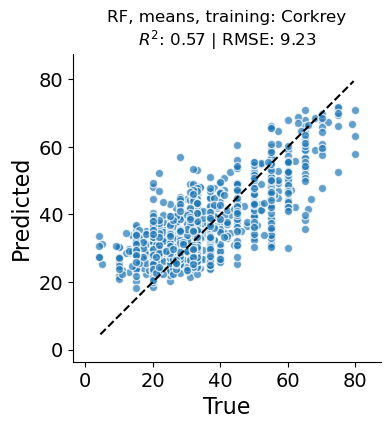

Running even_rf_means ...
100%|███████████████████████████████| 20/20 [1:21:10<00:00, 243.51s/trial, best loss: 1.4044429765469881]
4.0 2.0


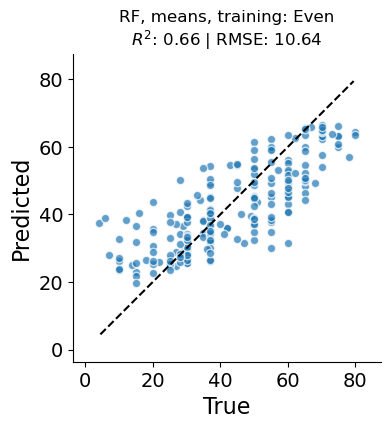

Running corkrey_svr_means ...
100%|███████████████████████████████████| 20/20 [00:05<00:00,  3.58trial/s, best loss: 1.466116944217537]
1.0 0.5


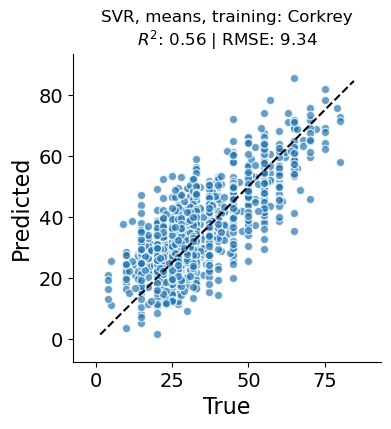

Running even_svr_means ...
100%|██████████████████████████████████| 20/20 [00:59<00:00,  2.99s/trial, best loss: 1.1736243491845184]
4.0 2.0


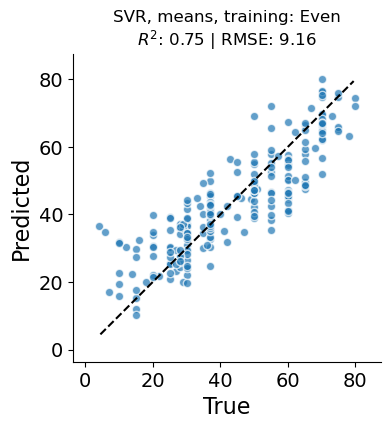

In [69]:
for model, label, title, x_train, x_test, y_train, y_test, space in zip(models,
                                                              labels,
                                                              titles,
                                                              training_inputs, 
                                                              testing_inputs,
                                                              training_ys,
                                                              testing_ys,
                                                              spaces):
    print(f'Running {label} ...')
    # Run the optimizer
    optimizer_results = optimize_sklearn_cv(
        model_class=model,
        X_train=x_train, 
        y_train=y_train, 
        X_test=x_test, 
        y_test=y_test, 
        space=space,
        is_regression=True,
        max_evals=20
    )


    plot_performance(unscale_ogts(optimizer_results['true_values'], scaler), 
                     unscale_ogts(optimizer_results['predictions'], scaler),
                     title=title,
                     show=True,
                     save_loc=f'./../data/figures/models/{label}.svg')

    
    optimizer_results['metadata'] = {'type':str(model),
                                      'input_shape':x_train.shape,
                                      'title':title,
                                      'label':label
    }
    
    with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
        pickle.dump(optimizer_results, handle)

In [38]:
# testing with testing data embedded in training context 
# i.e. trained on even -> tested on corkrey embedded using even 

## Linear model

In [71]:
corkrey_full_embeddings.shape

(230, 215, 768)

4.0 2.0


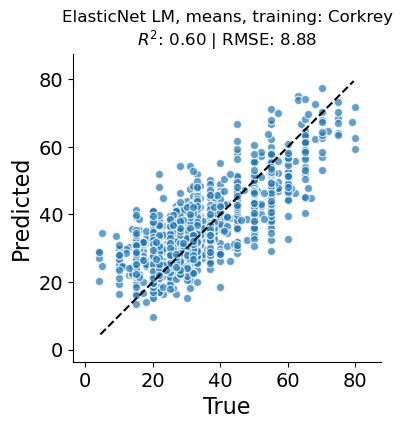

In [72]:
title = 'ElasticNet LM, means, training: Corkrey'
label = 'corkrey_lm_means'
# en_scaler = StandardScaler().fit(corkrey_full_embeddings[:, 0, :])
lm = ElasticNet(alpha=0.1)
lm.fit(corkrey_full_embeddings[:, 0, :], corkrey_temps)
# lm = sm.WLS(corkrey_temps, corkrey_embeddings).fit()

lm_pred = lm.predict(e_w_c_full_embeddings[:, 0, :])

lm_results = {'best_model':lm,
           'best_params':'', #lm.params,
           'predictions':lm_pred,
           'true_values': e_w_c_temps,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':str(lm),
                       'input_shape':corkrey_full_embeddings[:, 0, :].shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')


with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(lm_results, handle)

4.0 2.0


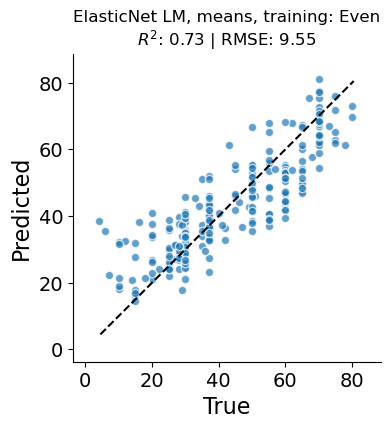

In [73]:
title = 'ElasticNet LM, means, training: Even'
label = 'even_lm_means' 

lm = ElasticNet(alpha=0.1)
lm.fit(even_full_embeddings[:, 0, :], even_temps)
# lm = sm.WLS(even_temps, even_embeddings).fit()

lm_pred = lm.predict(c_w_e_full_embeddings[:, 0, :])

lm_results = {'best_model':lm,
           'best_params':'', #lm.params,
           'predictions':lm_pred,
           'true_values': c_w_e_temps,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':str(lm),
                       'input_shape':even_full_embeddings[:, 0, :].shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')



with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(lm_results, handle)

## Gaussian process model

In [75]:
# define kernels to test
# plus a WhiteKernel for handle noise 
candidate_kernels = {
    "RBF (Smooth)": C(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1e-1),
    "Matern 1.5 (Rougher)": C(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1e-1),
    "Matern 2.5 (Balanced)": C(1.0) * Matern(length_scale=1.0, nu=2.5) + WhiteKernel(noise_level=1e-1),
    "RationalQuadratic": C(1.0) * RationalQuadratic(length_scale=1.0) + WhiteKernel(noise_level=1e-1)
}

X_train = even_full_embeddings[:, 0, :]
y_train = even_temps

results = {}

print(f"{'Kernel Type':<25} | {'Mean CV Score (R2)':<20} | {'Log-Marginal Likelihood'}")
print("-" * 75)

for name, kernel in candidate_kernels.items():
    # Initialize GPR
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=5, random_state=1234)
    
    # Perform 3-fold Cross Validation (R^2 score)
    scores = cross_val_score(gp, X_train, y_train, cv=3)
    
    # Fit once on full training set to get the optimized LML
    gp.fit(X_train, y_train)
    lml = gp.log_marginal_likelihood_value_
    
    results[name] = {'score': np.mean(scores), 'lml': lml, 'model': gp}
    
    print(f"{name:<25} | {np.mean(scores):18.4f} | {lml:18.2f}")

# 2. Identify the best kernel based on LML
best_kernel_name = max(results, key=lambda x: results[x]['lml'])
print(f"\nRecommended Kernel: {best_kernel_name}")

Kernel Type               | Mean CV Score (R2)   | Log-Marginal Likelihood
---------------------------------------------------------------------------
RBF (Smooth)              |             0.6662 |           -1858.28
Matern 1.5 (Rougher)      |             0.6681 |           -1854.42
Matern 2.5 (Balanced)     |             0.6674 |           -1856.05
RationalQuadratic         |             0.6672 |           -1856.57

Recommended Kernel: Matern 1.5 (Rougher)


4.0 2.0


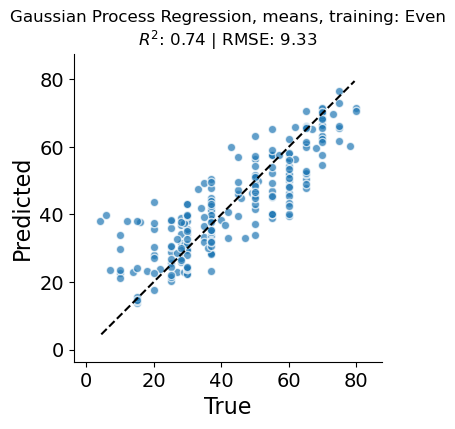

In [76]:

# 1. Setup metadata
title = 'Gaussian Process Regression, means, training: Even'
label = 'even_gpr_means' 

# 2. Define the Kernel
# We use a mix of a Constant kernel, RBF (smoothness), and WhiteKernel (noise)
# length_scale is often set to 1.0 initially; the optimizer will tune it.
# kernel = C(1.0, (1e-3, 1e3)) * RBF(1.0, (1e-2, 1e2)) + WhiteKernel(noise_level=1e-1)
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1e-1)

# 3. Initialize and fit GPR
# n_restarts_optimizer helps avoid local minima during kernel parameter tuning
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, random_state=123)

# Fitting on component 0: shape (N, E)
gp.fit(even_full_embeddings[:, 0, :], even_temps)

# 4. Predict
# GPR can also return standard deviation: gp.predict(X, return_std=True)
gp_pred = gp.predict(c_w_e_full_embeddings[:, 0, :])

# 5. Package results
gp_results = {
    'best_model': gp,
    'best_params': gp.kernel_, # This returns the optimized kernel parameters
    'predictions': gp_pred,
    'true_values': c_w_e_temps,
    'statsmodels_version': statsmodels.__version__,
    'metadata': {
        'type': str(gp),
        'kernel_config': str(gp.kernel_),
        'input_shape': even_full_embeddings[:, 0, :].shape,
        'title': title,
        'label': label
    }
}

# 6. Plot and Save
plot_performance(unscale_ogts(gp_results['true_values'], scaler), 
                 unscale_ogts(gp_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')

with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(gp_results, handle)

## Per-site linear model / ENET

In [77]:
print(corkrey_full_embeddings.shape)
print(even_full_embeddings.shape)

(230, 215, 768)
(1227, 215, 768)


4.0 2.0


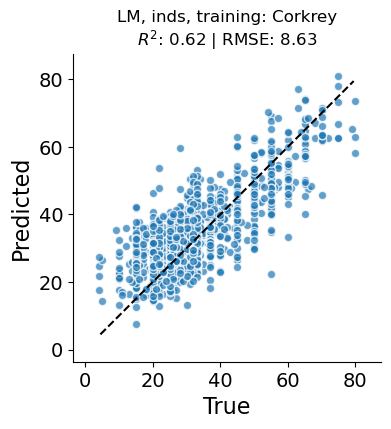

Dumping...
Done


In [126]:
title = 'LM, inds, training: Corkrey'
label = 'corkrey_lm_ind'

# fit models
corkrey_col_lms = {}
for col in range(corkrey_full_embeddings.shape[1]):
    display(col)
    clear_output(wait=True)
    col_embedding = corkrey_full_embeddings[:, col, :]
    # col_lm = ElasticNet(alpha=0.1, n_jobs=5)
    # col_lm.fit(col_embedding, corkrey_temps)
    col_lm = sm.WLS(corkrey_temps, col_embedding).fit()
    corkrey_col_lms[col] = col_lm

# predict
even_col_preds = []
for col in range(len(corkrey_col_lms)):
    display(col)
    clear_output(wait=True)
    even_col_preds.append(corkrey_col_lms[col].predict(e_w_c_full_embeddings[:, col, :]))

even_mean_preds = np.array(even_col_preds).mean(axis=0)

lm_results = {'best_model':corkrey_col_lms,
           'best_params':'', #dict((k, i.params) for k,i in corkrey_col_lms.items()),
           'predictions':even_mean_preds,
          'full_predictions':np.array(even_col_preds),
           'true_values': even_temps,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':f'array of {str(lm)}',
                       'input_shape':corkrey_full_embeddings.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')


print('Dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(lm_results, handle)
print('Done')

4.0 2.0


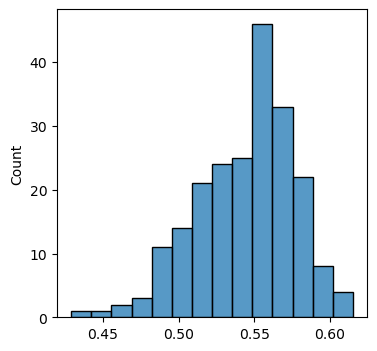

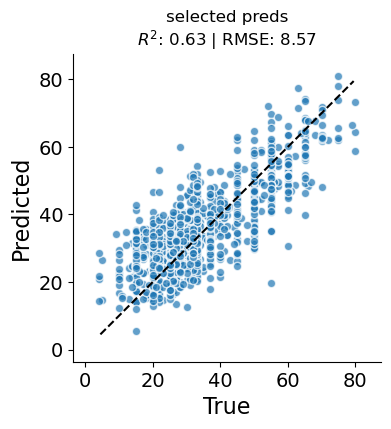

-5.0 -2.5


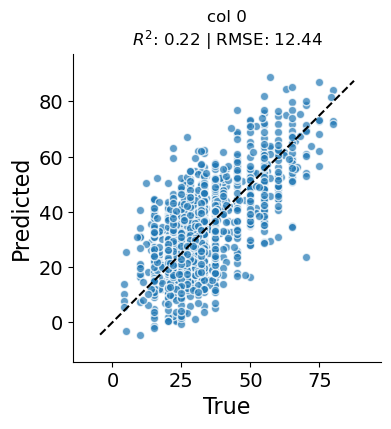

In [129]:
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(1,1,1)
col_rs = [spearmanr(col, even_temps)[0] for col in even_col_preds]
sns.histplot(col_rs)
np.argmax(col_rs)
selected_preds = np.array([even_col_preds[i] for i in range(len(even_col_preds)) if col_rs[i] > 0.55])

plot_performance( unscale_ogts(even_temps, scaler),
                  unscale_ogts(selected_preds.mean(axis=0), scaler),
                title='selected preds', show=True)
col = 0
plot_performance( unscale_ogts(even_temps, scaler),
                  unscale_ogts(even_col_preds[col], scaler),
                title=f'col {col}', show=True)

4.0 2.0


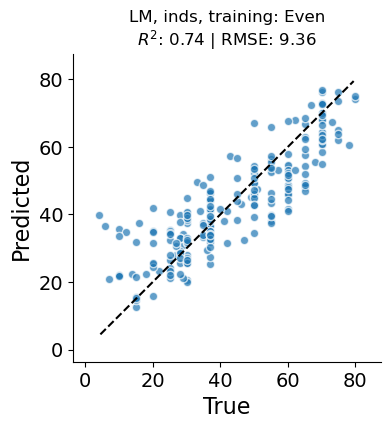

dumping...
done.


In [130]:
title = 'LM, inds, training: Even'
label = 'even_lm_ind'
# fit models
even_col_lms = {}
for col in range(even_full_embeddings.shape[1]):
    display(col)
    clear_output(wait=True)
    col_embedding = even_full_embeddings[:, col, :]
    col_lm = sm.WLS(even_temps, col_embedding).fit()
    # col_lm = ElasticNet(alpha=0.1, n_jobs=5)
    # col_lm.fit( col_embedding, even_temps)
    even_col_lms[col] = col_lm

# predict
corkrey_col_preds = []
for col in range(len(even_col_lms)):
    display(col)
    clear_output(wait=True)
    corkrey_col_preds.append(even_col_lms[col].predict(c_w_e_full_embeddings[:, col, :]))

corkrey_mean_preds = np.array(corkrey_col_preds).mean(axis=0)

lm_results = {'best_model':even_col_lms,
           'best_params':'', #dict((k, i.params) for k,i in even_col_lms.items()),
           'predictions':corkrey_mean_preds,
          'full_predictions':np.array(corkrey_col_preds),
           'true_values': c_w_e_temps,
            'true_labels':[i[0] for i in corkrey_msa_dataset],
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':f'array of {str(lm)}',
                       'input_shape':even_full_embeddings.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')


print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(lm_results, handle)
print('done.')

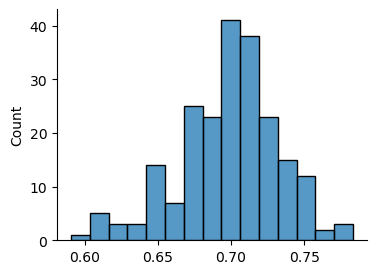

In [132]:
col_rs = pd.Series()
good_cols = []
for col in range(len(even_col_lms)):
    spr = spearmanr(even_col_lms[col].predict(c_w_e_full_embeddings[:, col, :]), corkrey_temps)[0]
    col_rs.loc[col] = spr
    if spr > 0.725:
        good_cols.append(col)

fig, ax = plt.subplots(figsize=(4,3))
sns.histplot(col_rs)
sns.despine()

In [133]:
print('Best col:', col_rs[np.argmax(col_rs)], 'col', np.argmax(col_rs))
even_full_embeddings.shape

Best col: 0.7831138989230382 col 53


(1227, 215, 768)

0.7831138989230382
-8.0 -4.0


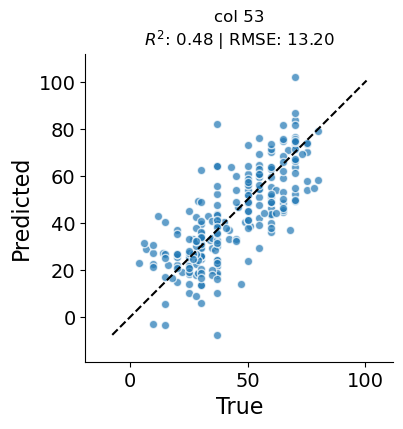

In [134]:
# test of an individual column
col = np.argmax(col_rs)
y_pred = unscale_ogts(even_col_lms[col].predict(c_w_e_full_embeddings[:, col, :]), scaler)
y_true = unscale_ogts(corkrey_temps, scaler)
print(spearmanr(y_pred, y_true)[0])
plot_performance(y_pred=y_pred, 
                y_true=y_true, title=f'col {col}', show=True)


In [135]:
col_rs.to_csv('./../data/predictive_models/supporting_data/even_lm_ind_spearmans.tsv', sep='\t')

<Axes: xlabel='index', ylabel='0'>

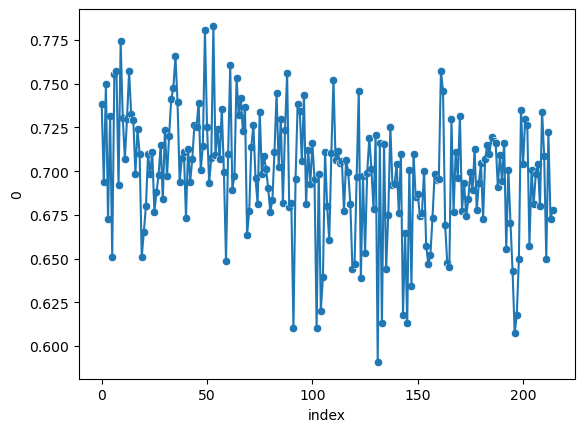

In [136]:
sns.scatterplot(data=col_rs.reset_index(),
               x='index', y=0)

sns.lineplot(data=col_rs.reset_index(),
               x='index', y=0)

In [137]:
# predict
good_col_preds = []
for col in range(len(even_col_lms)):
    display(col)
    clear_output(wait=True)
    if col in good_cols:
        good_col_preds.append(even_col_lms[col].predict(c_w_e_full_embeddings[:, col, :]))
        

214

<Axes: ylabel='Count'>

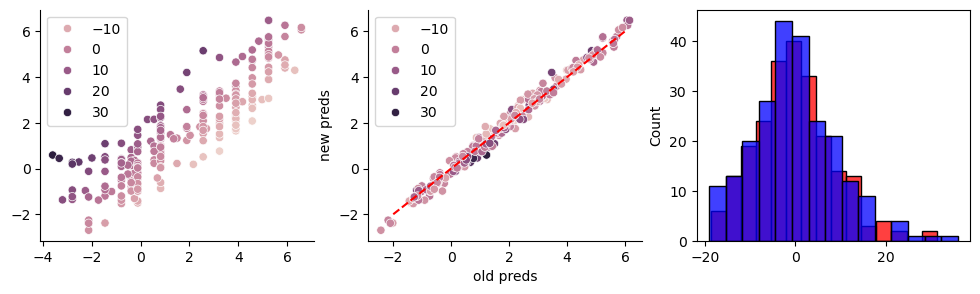

In [138]:
fig = plt.figure(figsize=(12, 3))
ax = fig.add_subplot(1,3,1)
sns.scatterplot(y=np.array(good_col_preds).mean(axis=0), 
                x=corkrey_temps, hue=unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler))
sns.despine()

ax = fig.add_subplot(1,3,2)
sns.scatterplot(y=np.array(good_col_preds).mean(axis=0), 
                x=corkrey_mean_preds,
               hue=unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler))
ax.set_ylabel('new preds')
ax.set_xlabel('old preds')
plt.plot((-2, 6), (-2, 6), 'r--')
sns.despine()
ax = fig.add_subplot(1,3,3)
sns.histplot(unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler), color='r', label='new')
sns.histplot(unscale_ogts(corkrey_mean_preds, scaler) - unscale_ogts(corkrey_temps, scaler), color='b', label='old')

4.0 2.0


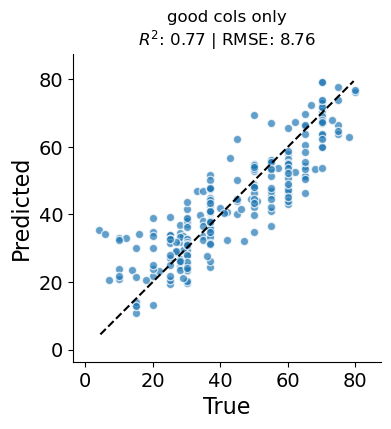

In [139]:
plot_performance(unscale_ogts(corkrey_temps, scaler),
                unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler), 
                'good cols only', show=True)

### Working on this model a little more

In [140]:
emb_scaler = StandardScaler()
scaled_emb = emb_scaler.fit_transform(even_full_embeddings[:, col, :])

-8.0 -4.0


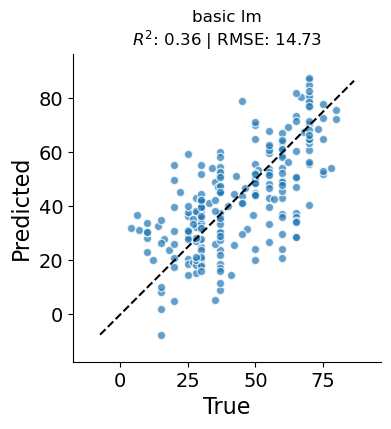

<Axes: ylabel='Count'>

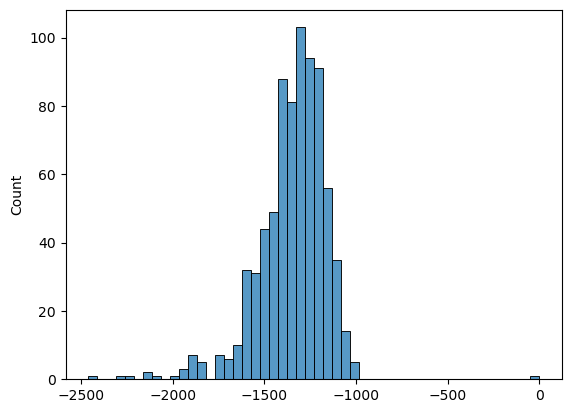

In [141]:
# after
scaled_emb = sm.add_constant(scaled_emb)
lm = sm.WLS(even_temps, scaled_emb).fit()

plot_performance(unscale_ogts(corkrey_temps, scaler),
                unscale_ogts(lm.get_prediction(sm.add_constant(emb_scaler.transform(c_w_e_full_embeddings[:, col, :]))).predicted_mean, scaler),
                'basic lm',
                show=True)

sns.histplot(lm.params, bins=50)

In [142]:
lm.params.argmin()

18

In [143]:
lm.params[18]

-2460.3916898985126

<Axes: >

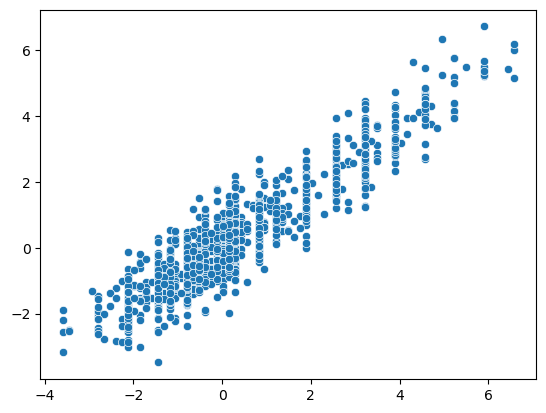

In [144]:
sns.scatterplot(y=np.sum(scaled_emb * lm.params, axis=1), x=even_temps)

<Axes: >

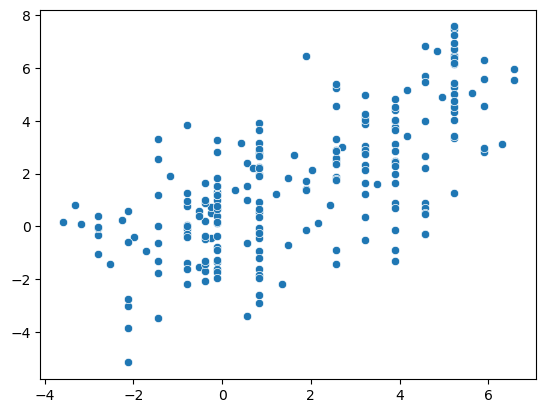

In [145]:
sns.scatterplot(y=np.sum(sm.add_constant(emb_scaler.transform(c_w_e_full_embeddings[:, col, :])) * lm.params, axis=1), x=corkrey_temps)

In [146]:
lm.condition_number

35831575.59727968

#### Notes
obviously this weighted least squares regression is suffering from a lot of covariance, so the parameter estimates (which I need later) are kind of whacky

#### Trying out ElasticNet

In [110]:
scaled_emb = emb_scaler.fit_transform(even_full_embeddings[:, col, :])
lm = ElasticNet(alpha=0.1)
lm.fit(scaled_emb, even_temps)

ElasticNet(alpha=0.1)

4.0 2.0


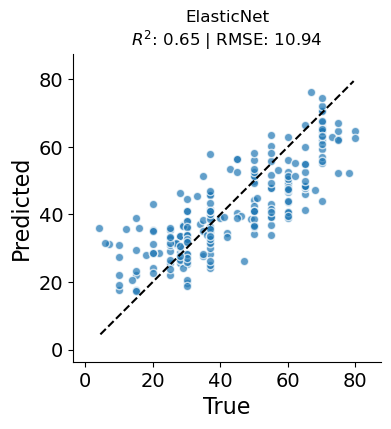

In [111]:
plot_performance(unscale_ogts(corkrey_temps, scaler),
                 unscale_ogts(lm.predict(emb_scaler.transform(c_w_e_full_embeddings[:, col, :])), scaler),
                'ElasticNet',
                show=True)

<Axes: ylabel='Count'>

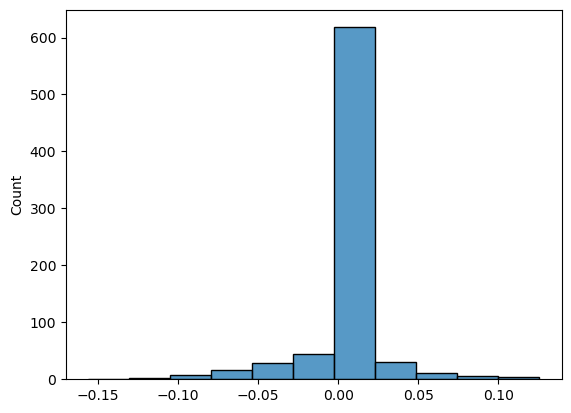

In [112]:
sns.histplot(lm.coef_)

#### Notes
Coefficients are much better behaved

## Per site ENET

4.0 2.0


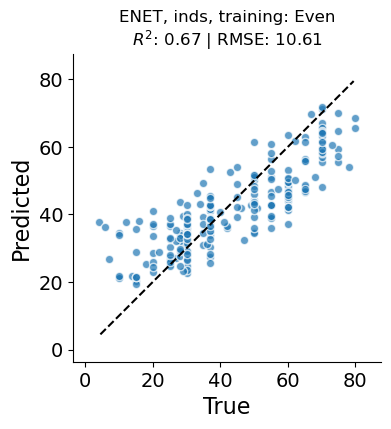

dumping...
done.


In [113]:
title = 'ENET, inds, training: Even'
label = 'even_enet_ind'
# fit models
even_col_enets = {}
even_col_scalers = {}
for col in range(even_full_embeddings.shape[1]):
    display(col)
    clear_output(wait=True)
    col_embedding = even_full_embeddings[:, col, :]
    even_col_scalers[col] = StandardScaler()
    X = even_col_scalers[col].fit_transform(col_embedding)
    # col_lm = sm.WLS(even_temps, X).fit()
    col_lm = ElasticNet(alpha=0.1, n_jobs=5)
    col_lm.fit(X, even_temps)
    even_col_enets[col] = col_lm

# predict
corkrey_col_preds = []
for col in range(len(even_col_enets)):
    display(col)
    clear_output(wait=True)
    corkrey_col_preds.append(even_col_enets[col].predict(even_col_scalers[col].transform(c_w_e_full_embeddings[:, col, :])))

corkrey_mean_preds = np.array(corkrey_col_preds).mean(axis=0)

enet_results = {'best_model':even_col_enets,
           'best_params':'', #dict((k, i.params) for k,i in even_col_enets.items()),
           'predictions':corkrey_mean_preds,
          'full_predictions':np.array(corkrey_col_preds),
           'true_values': c_w_e_temps,
            'true_labels':[i[0] for i in corkrey_msa_dataset],
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':f'array of {str(lm)}',
                       'input_shape':even_full_embeddings.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(enet_results['true_values'], scaler), 
                 unscale_ogts(enet_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')


print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(enet_results, handle)
print('done.')

In [114]:
enet_results['scalers'] = even_col_scalers

print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(enet_results, handle)
print('done.')

dumping...
done.


In [115]:
enet_results['best_model'][0]

ElasticNet(alpha=0.1, n_jobs=5)

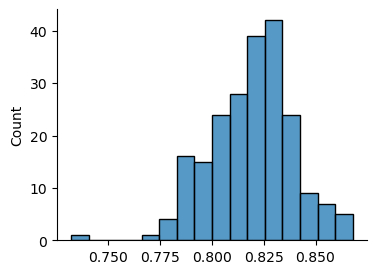

In [118]:
col_rs = pd.Series()
good_cols = []
for col in range(len(even_col_enets)):
    spr = spearmanr(even_col_enets[col].predict(even_col_scalers[col].transform(c_w_e_full_embeddings[:, col, :])), corkrey_temps)[0]
    col_rs.loc[col] = spr
    if spr > 0.82:
        good_cols.append(col)

fig, ax = plt.subplots(figsize=(4,3))
sns.histplot(col_rs)
sns.despine()

In [119]:
print('Best col:', col_rs[np.argmax(col_rs[1:])+1], 'col', np.argmax(col_rs[1:])+1)
even_full_embeddings.shape

Best col: 0.8677668278433261 col 88


(1227, 215, 768)

0.8677668278433261
4.0 2.0


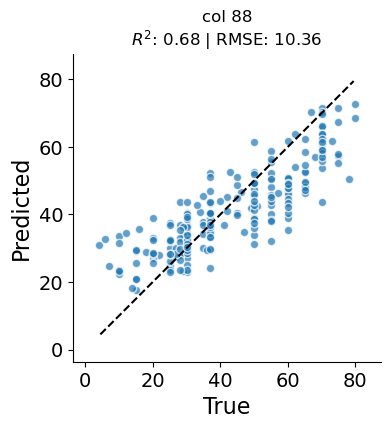

In [120]:
# test of an individual column
col = 88
y_pred = unscale_ogts(even_col_enets[col].predict(even_col_scalers[col].transform(c_w_e_full_embeddings[:, col, :])), scaler)
y_true = unscale_ogts(corkrey_temps, scaler)
print(spearmanr(y_pred, y_true)[0])
plot_performance(y_pred=y_pred, 
                y_true=y_true, title=f'col {col}', show=True)


In [121]:
col_rs.to_csv('./../data/predictive_models/supporting_data/even_enet_ind_spearmans.tsv', sep='\t')

<Axes: xlabel='index', ylabel='0'>

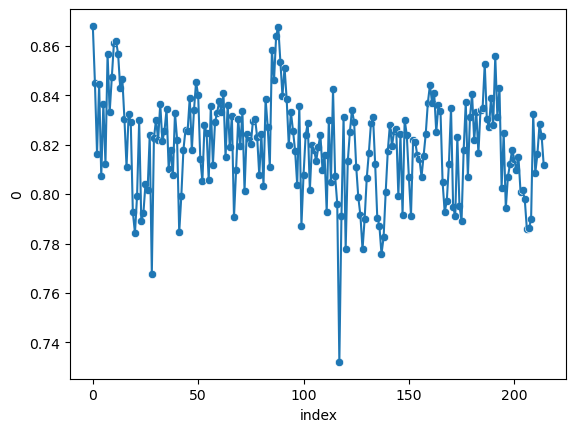

In [122]:
sns.scatterplot(data=col_rs.reset_index(),
               x='index', y=0)

sns.lineplot(data=col_rs.reset_index(),
               x='index', y=0)

In [123]:
# predict
good_col_preds = []
for col in range(len(even_col_enets)):
    display(col)
    clear_output(wait=True)
    if col in good_cols:
        good_col_preds.append(even_col_enets[col].predict(even_col_scalers[col].transform(c_w_e_full_embeddings[:, col, :])))
        

214

<Axes: ylabel='Count'>

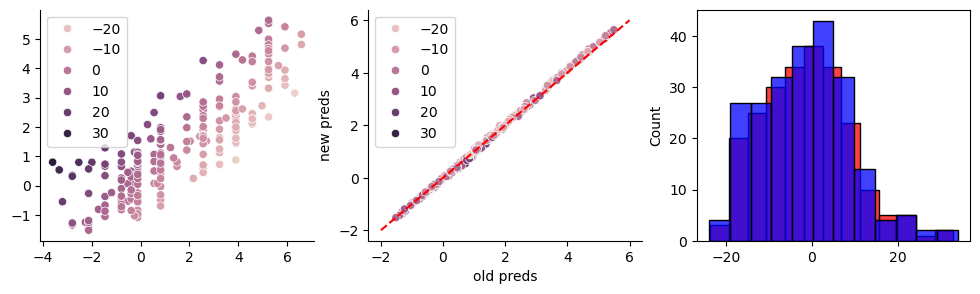

In [124]:
fig = plt.figure(figsize=(12, 3))
ax = fig.add_subplot(1,3,1)
sns.scatterplot(y=np.array(good_col_preds).mean(axis=0), 
                x=corkrey_temps, hue=unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler))
sns.despine()

ax = fig.add_subplot(1,3,2)
sns.scatterplot(y=np.array(good_col_preds).mean(axis=0), 
                x=corkrey_mean_preds,
               hue=unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler))
ax.set_ylabel('new preds')
ax.set_xlabel('old preds')
plt.plot((-2, 6), (-2, 6), 'r--')
sns.despine()
ax = fig.add_subplot(1,3,3)
sns.histplot(unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler), color='r', label='new')
sns.histplot(unscale_ogts(corkrey_mean_preds, scaler) - unscale_ogts(corkrey_temps, scaler), color='b', label='old')

4.0 2.0


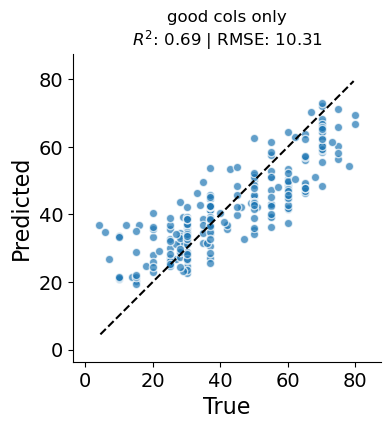

In [125]:
plot_performance(unscale_ogts(corkrey_temps, scaler),
                 unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler), 
                 'good cols only', show=True)

### Trying to improve ENET accuracy

In [147]:
from sklearn.linear_model import ElasticNetCV

In [148]:
emb_scaler = StandardScaler()
scaled_emb = emb_scaler.fit_transform(even_full_embeddings[:, 0, :])


In [149]:
sklearn.__version__

'1.4.1.post1'

In [150]:
enet = ElasticNetCV(l1_ratio=[0.01, 0.1, 0.25, .5, .75, .9, 0.99, 1.0], cv=5, 
                    n_alphas=100, max_iter=10000, selection='random', tol=1e-3,
                   random_state=123, n_jobs=24)
enet.fit(scaled_emb, even_temps)

ElasticNetCV(cv=5, l1_ratio=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0],
             max_iter=10000, n_jobs=24, random_state=123, selection='random',
             tol=0.001)

In [151]:
print("ElasticNet alpha:", enet.alpha_, "l1_ratio:", enet.l1_ratio_)

ElasticNet alpha: 0.013461868364605094 l1_ratio: 0.99


4.0 2.0


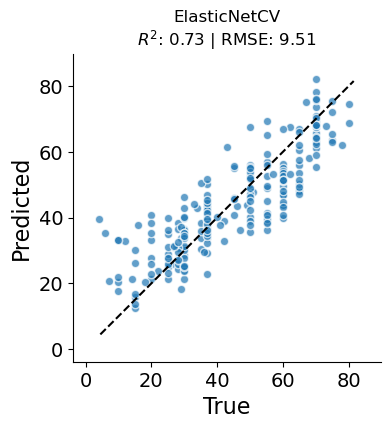

In [152]:
plot_performance(unscale_ogts(corkrey_temps, scaler),
                 unscale_ogts(enet.predict(emb_scaler.transform(c_w_e_full_embeddings[:, 0, :])), scaler),
                'ElasticNetCV',
                show=True)

4.0 2.0


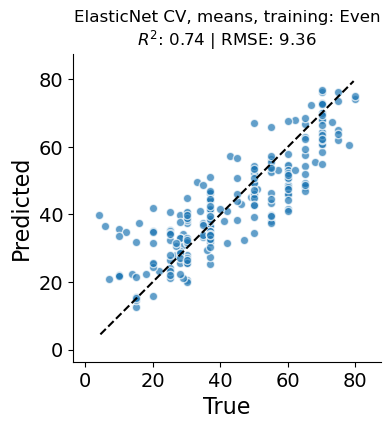

In [161]:
title = 'ElasticNet CV, means, training: Even'
label = 'even_enetcv_means'
emb_scaler = StandardScaler()
scaled_emb = emb_scaler.fit_transform(even_full_embeddings[:, 0, :])

enet = ElasticNetCV(l1_ratio=[0.01, 0.1, 0.25, .5, .75, .9, 0.99, 1.0], cv=5, 
                    n_alphas=100, max_iter=10000, selection='random', tol=1e-3,
                   random_state=123, n_jobs=24)
enet.fit(scaled_emb, even_temps)

enet_pred = enet.predict(emb_scaler.transform(c_w_e_full_embeddings[:, 0, :]))

enet_results = {'best_model':enet,
           'best_params':'', #lm.params,
           'predictions':enet_pred,
           'true_values': c_w_e_temps,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':str(lm),
                       'input_shape':c_w_e_full_embeddings[:, 0, :].shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')


with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(enet_results, handle)

#### Notes: ElasticNetCV is better than ElasticNet

### Does a GLM work better just using the ElasticNet coefficients?

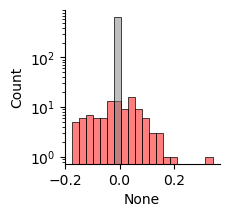

In [156]:
coef_series = pd.Series(enet.coef_, index=list(range(X.shape[1])))
fig, ax = plt.subplots(figsize=(2,2))
sns.histplot(x=coef_series, 
             bins=20,
             hue=(coef_series.abs() > 1e-4), 
             legend=False, palette=['gray', 'red'])
ax.set_yscale('log')
sns.despine()

In [157]:
X_final = sm.add_constant(scaled_emb[:, coef_series[coef_series.abs()>1e-6].index])

Condition number of X_final: 34.73117786128156
3.0 1.5


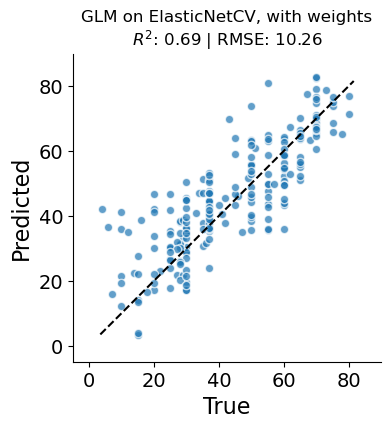

In [158]:
# GLM with weights
weights = compute_gaussian_weights(even_temps)

model = sm.GLM(even_temps, X_final, family=sm.families.Gaussian(), var_weights=weights).fit()

# get y predictions
y_pred = model.get_prediction(sm.add_constant(emb_scaler.transform(c_w_e_full_embeddings[:, 0, :])[:, coef_series[coef_series.abs()>1e-6].index])).predicted_mean
# y_pred = y_pred.map(lambda x: y_scaler.inverse_transform([[x]])[0][0])
# residuals = y['temp'] - y_pred
print("Condition number of X_final:", np.linalg.cond(X_final))

plot_performance(unscale_ogts(corkrey_temps, scaler),
                 unscale_ogts(y_pred, scaler),
                'GLM on ElasticNetCV, with weights',
                show=True)

Condition number of X_final: 34.73117786128156
4.0 2.0


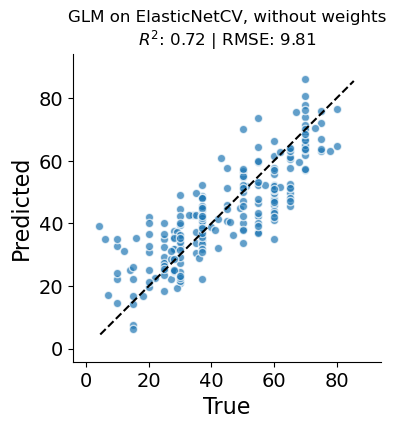

In [160]:
# OLS with weights
weights = compute_gaussian_weights(even_temps)

model = sm.OLS(even_temps, X_final).fit()

# get y predictions
y_pred = model.get_prediction(sm.add_constant(emb_scaler.transform(c_w_e_full_embeddings[:, 0, :])[:, coef_series[coef_series.abs()>1e-6].index])).predicted_mean
# y_pred = y_pred.map(lambda x: y_scaler.inverse_transform([[x]])[0][0])
# residuals = y['temp'] - y_pred
print("Condition number of X_final:", np.linalg.cond(X_final))

plot_performance(unscale_ogts(corkrey_temps, scaler),
                 unscale_ogts(y_pred, scaler),
                'GLM on ElasticNetCV, without weights',
                show=True)

#### Answer: yes? but doesn't add anything

### Is per-column ElasticNetCV better?

4.0 2.0


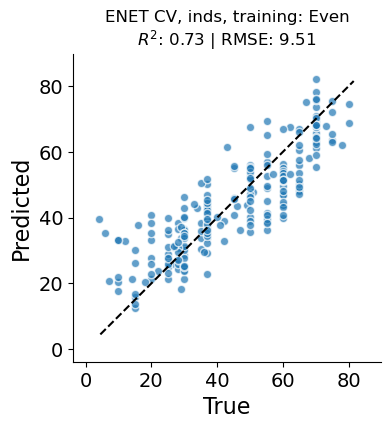

In [168]:
title = 'ENET CV, inds, training: Even'
label = 'even_enetcv_ind'
# fit models
even_col_enets = {}
even_col_scalers = {}
for col in range(even_full_embeddings.shape[1]):
    display(col)
    clear_output(wait=True)
    col_embedding = even_full_embeddings[:, col, :]
    even_col_scalers[col] = StandardScaler()
    X = even_col_scalers[col].fit_transform(col_embedding)
    # col_lm = sm.WLS(even_temps, X).fit()
    enet = ElasticNetCV(l1_ratio=[0.01, 0.1, 0.25, .5, .75, .9, 0.99, 1.0], cv=5, 
                    n_alphas=100, max_iter=10000, selection='random', tol=1e-3,precompute=False,
                   random_state=123, n_jobs=24)
    enet.fit(X, even_temps)
    # col_lm = ElasticNet(alpha=0.1, n_jobs=5)
    # col_lm.fit(X, even_temps)
    even_col_enets[col] = enet

# predict
corkrey_col_preds = []
for col in range(len(even_col_enets)):
    display(col)
    clear_output(wait=True)
    corkrey_col_preds.append(even_col_enets[col].predict(even_col_scalers[col].transform(c_w_e_full_embeddings[:, col, :])))

corkrey_mean_preds = np.array(corkrey_col_preds).mean(axis=0)

# enet_results = {'best_model':even_col_enets,
#            'best_params':'', #dict((k, i.params) for k,i in even_col_enets.items()),
#            'predictions':corkrey_mean_preds,
#           'full_predictions':np.array(corkrey_col_preds),
#            'true_values': c_w_e_temps,
#             'true_labels':[i[0] for i in corkrey_msa_dataset],
#            'statsmodels_version':statsmodels.__version__,
#            'metadata':{'type':f'array of {str(lm)}',
#                        'input_shape':even_full_embeddings.shape,
#                        'title':title,
#                        'label':label
#                       }
#           }

plot_performance(unscale_ogts(enet_results['true_values'], scaler), 
                 unscale_ogts(enet_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')


# print('dumping...')
# with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
#     pickle.dump(enet_results, handle)
# print('done.')

In [169]:
enet_results = {'best_model':even_col_enets,
           'best_params':'', #dict((k, i.params) for k,i in even_col_enets.items()),
           'predictions':corkrey_mean_preds,
          'full_predictions':np.array(corkrey_col_preds),
           'true_values': c_w_e_temps,
            'true_labels':[i[0] for i in corkrey_msa_dataset],
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':f'array of {str(lm)}',
                       'input_shape':even_full_embeddings.shape,
                       'title':title,
                       'label':label
                      }
          }

enet_results['scalers'] = even_col_scalers

print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(enet_results, handle)
print('done.')

dumping...
done.


#### Kind of 

### What about with good cols?

Best col: 0.8714739882571023 col 88
0.8714739882571023
4.0 2.0


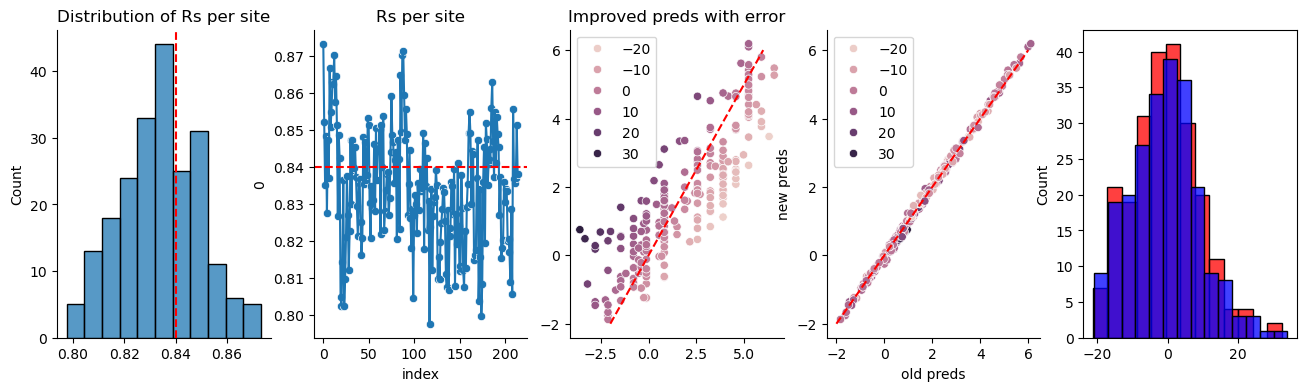

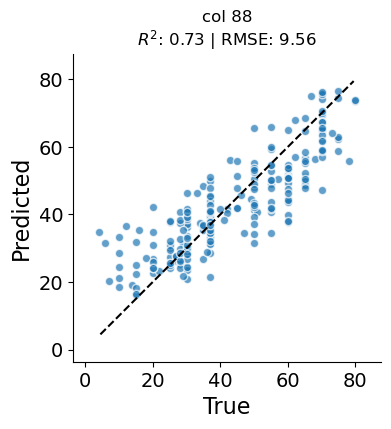

In [176]:
fig = plt.figure(figsize=(16, 4))
ax = fig.add_subplot(1, 5, 1)
cutoff = 0.84
col_rs = pd.Series()
good_cols = []
for col in range(len(even_col_enets)):
    spr = spearmanr(even_col_enets[col].predict(even_col_scalers[col].transform(c_w_e_full_embeddings[:, col, :])), corkrey_temps)[0]
    col_rs.loc[col] = spr
    if spr > cutoff:
        good_cols.append(col)

sns.histplot(col_rs)
sns.despine()
ax.axvline(cutoff, linestyle='--', color='r')
ax.set_title('Distribution of Rs per site')

ax = fig.add_subplot(1, 5, 2)
sns.scatterplot(data=col_rs.reset_index(),
               x='index', y=0, ax=ax)

sns.lineplot(data=col_rs.reset_index(),
               x='index', y=0, ax=ax)
sns.despine()
ax.axhline(cutoff, color='r', linestyle='--')
ax.set_title('Rs per site')

# predict using good columns
good_col_preds = []
for col in range(len(even_col_enets)):
    # display(col)
    # clear_output(wait=True)
    if col in good_cols:
        good_col_preds.append(even_col_enets[col].predict(even_col_scalers[col].transform(c_w_e_full_embeddings[:, col, :])))
        

ax = fig.add_subplot(1,5,3)
sns.scatterplot(y=np.array(good_col_preds).mean(axis=0), 
                x=corkrey_temps, hue=unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler), ax=ax)
plt.plot((-2, 6), (-2, 6), color='r', linestyle='--')
sns.despine()
ax.set_title('Improved preds with error')

ax = fig.add_subplot(1,5,4)
sns.scatterplot(y=np.array(good_col_preds).mean(axis=0), 
                x=corkrey_mean_preds,
               hue=unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler),
               ax=ax)
ax.set_ylabel('new preds')
ax.set_xlabel('old preds')
plt.plot((-2, 6), (-2, 6), 'r--')
sns.despine()

ax = fig.add_subplot(1,5,5)
sns.histplot(unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler) - unscale_ogts(corkrey_temps, scaler), color='r', label='new', ax=ax)
sns.histplot(unscale_ogts(corkrey_mean_preds, scaler) - unscale_ogts(corkrey_temps, scaler), color='b', label='old', ax=ax)

# ax = fig.add_subplot(1, 4, 2)
print('Best col:', col_rs[np.argmax(col_rs[1:])+1], 'col', np.argmax(col_rs[1:])+1)

best_col = np.argmax(col_rs[1:])+1
# test of an individual column
y_pred = unscale_ogts(even_col_enets[best_col].predict(even_col_scalers[best_col].transform(c_w_e_full_embeddings[:, best_col, :])), scaler)
y_true = unscale_ogts(corkrey_temps, scaler)
print(spearmanr(y_pred, y_true)[0])
plot_performance(y_pred=y_pred, 
                y_true=y_true, title=f'col {best_col}', show=True)


4.0 2.0


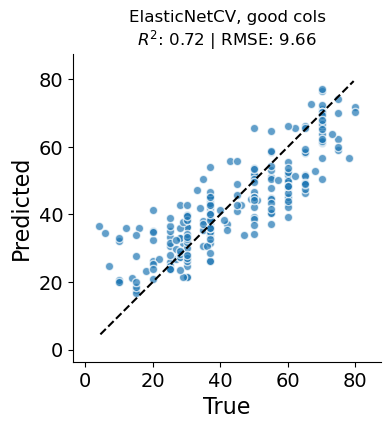

In [177]:
plot_performance(unscale_ogts(corkrey_temps, scaler),
                 unscale_ogts(np.array(good_col_preds).mean(axis=0), scaler), 
                 'ElasticNetCV, good cols',
                show=True)

#### Marginally

In [174]:
col_rs.to_csv('./../data/predictive_models/supporting_data/even_enetcv_ind_spearmans.tsv', sep='\t')

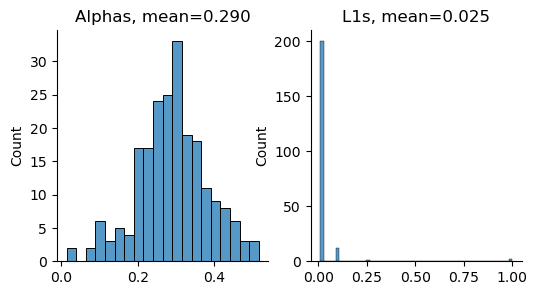

In [175]:
# how stable are the l1s / alphas found by the CV per site in protein?
l1s, alphas = [], []
for enet_col in even_col_enets.keys():
    enet = even_col_enets[enet_col]
    alphas.append(enet.alpha_)
    l1s.append(enet.l1_ratio_)

fig = plt.figure(figsize=(6, 3))
ax = fig.add_subplot(1, 2, 1)
sns.histplot(alphas, bins=20, ax=ax)
ax.set_title(f'Alphas, mean={np.mean(alphas):.3f}')
sns.despine()

ax = fig.add_subplot(1, 2, 2)
sns.histplot(l1s, bins=50, ax=ax)
ax.set_title(f'L1s, mean={np.mean(l1s):.3f}')
sns.despine()

In [420]:
# Are the ENET coefficients stable?
# test on cls
col_embedding = even_full_embeddings[:, 0, :]
emb_scaler = StandardScaler()
X = emb_scaler.fit_transform(col_embedding)
# Create a random generator
rng = np.random.default_rng()
coefs = []

for i in tqdm(range(100)):
    test_enet = ElasticNet(alpha=even_col_enets[0].alpha_, n_jobs=5)
    # bootstrap sampling
    # 1. Synchronize your bootstrap sampling
    indices = rng.integers(0, len(X), size=len(X))
    X_sampled = X[indices, :]
    y_sampled = even_temps[indices]
    test_enet.fit(X_sampled, y_sampled)
    coefs.append(test_enet.coef_)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [06:09<00:00,  3.69s/it]


In [421]:
temp_plotdf = pd.DataFrame(np.array(coefs)).stack().reset_index()

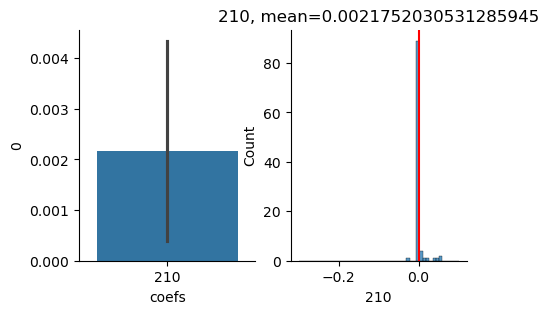

In [445]:
# do these estimates match the per-site estimates?
fig= plt.figure(figsize=(5,3))
emb_comp = 210
ax = fig.add_subplot(1,2,1)
sns.barplot(data=temp_plotdf[temp_plotdf.level_1.eq(emb_comp)],
           x='level_1', y=0)
sns.despine()
ax.set_xlabel('coefs')
ax = fig.add_subplot(1,2,2)
sns.histplot(pd.DataFrame(np.array(coefs)).iloc[:, emb_comp], 
             label='boostrap coeffs', bins=np.linspace(-0.3, 0.1, 50))
ax.axvline(np.array(coefs)[:, emb_comp].mean(), color='r')
# sns.histplot([even_col_enets[col].coef_[emb_comp] for col in even_col_enets.keys()], 
#              label='col coeffs', bins=np.linspace(-0.3, 0.1, 50))
ax.set_title(f'{emb_comp}, mean={np.array(coefs)[:, emb_comp].mean()}')
sns.despine()

Text(0.5, 1.0, '# coef != 0 (n = 100)')

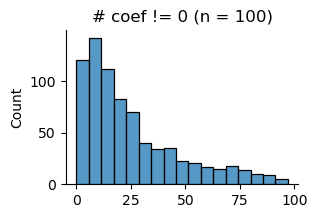

In [469]:
fig, ax = plt.subplots(figsize=(3,2))
sns.histplot((boot_coefs != 0).sum(axis=0))
sns.despine()
ax.set_title('# coef != 0 (n = 100)')

In [ ]:
boot_coefs = np.array(coefs)
lower_bounds = np.percentile(boot_coefs, 2.5, axis=0)
upper_bounds = np.percentile(boot_coefs, 97.5, axis=0)
means = np.mean(boot_coefs, axis=0)
stds = np.std(boot_coefs, axis=0)

# 2. Identify significant components
# A component is significant if the range [lower, upper] does not straddle 0
is_significant = (lower_bounds > 0) | (upper_bounds < 0)

# 3. Create a summary table
results = pd.DataFrame({
    'component': np.arange(768),
    'n_nonzero':(boot_coefs != 0).sum(axis=0),
    'mean_coef': means,
    'std_coef':stds,
    'ci_lower': lower_bounds,
    'ci_upper': upper_bounds,
    'significant': is_significant
})

results.to_csv('./../data/predictive_models/supporting_data/enet_col0_boostrap_coefs.tsv', sep='\t')

In [ ]:
# do these estimates match the per-site estimates?
fig, ax = plt.subplots(figsize=(4,3))
emb_comp = 210
sns.histplot(pd.DataFrame(np.array(coefs)).iloc[:, emb_comp], 
             label='boostrap coeffs', bins=np.linspace(-0.3, 0.1, 50))
ax.axvline(pd.DataFrame(np.array(coefs)).iloc[:, emb_comp].mean(), color='r')
# sns.histplot([even_col_enets[col].coef_[emb_comp] for col in even_col_enets.keys()], 
#              label='col coeffs', bins=np.linspace(-0.3, 0.1, 50))
ax.set_title(emb_comp)
sns.despine()

## Per site GPR

4.0 2.0


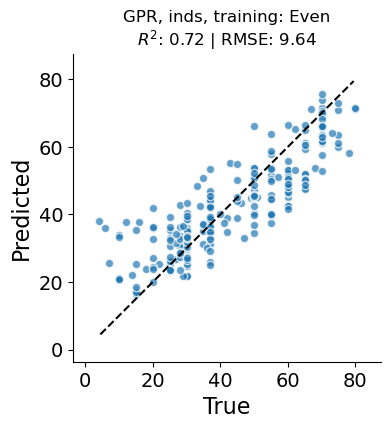

dumping...
done.


In [178]:
title = 'GPR, inds, training: Even'
label = 'even_gpr_ind'

# 1. Define base kernel (RBF + Noise is a solid default for embeddings)
kernel = C(1.0) * RBF(1.0) + WhiteKernel(noise_level=1e-1)

# fit models
even_col_gps = {}
for col in range(even_full_embeddings.shape[1]):
    display(f"Fitting GPR for column: {col}")
    clear_output(wait=True)
    
    col_embedding = even_full_embeddings[:, col, :]
    
    # Initialize GPR (n_restarts_optimizer is key for column-wise tuning)
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=5, random_state=1234)
    gp.fit(col_embedding, even_temps)
    
    even_col_gps[col] = gp

# predict
corkrey_col_preds = []
corkrey_col_std = []

for col in range(len(even_col_gps)):
    display(f"Predicting for column: {col}")
    clear_output(wait=True)
    
    # GPR allows us to return the standard deviation (uncertainty)
    mu, std = even_col_gps[col].predict(c_w_e_full_embeddings[:, col, :], return_std=True)
    
    corkrey_col_preds.append(mu)
    corkrey_col_std.append(std)

# Aggregate results
corkrey_mean_preds = np.array(corkrey_col_preds).mean(axis=0)
corkrey_mean_std = np.array(corkrey_col_std).mean(axis=0) # Average uncertainty

gp_results = {
    'best_model': even_col_gps,
    'best_params': {k: v.kernel_ for k, v in even_col_gps.items()},
    'predictions': corkrey_mean_preds,
    'prediction_std': corkrey_mean_std, # New: Uncertainty metric
    'full_predictions': np.array(corkrey_col_preds),
    'true_values': c_w_e_temps,
    'metadata': {
        'type': 'Column-wise GaussianProcessRegressor',
        'input_shape': even_full_embeddings.shape,
        'title': title,
        'label': label
    }
}

# Plotting
plot_performance(unscale_ogts(gp_results['true_values'], scaler), 
                 unscale_ogts(gp_results['predictions'], scaler),
                 title=title,
                 show=True,
                 save_loc=f'./../data/figures/models/{label}.svg')

print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(gp_results, handle)
print('done.')

## neural network

In [25]:
from src.models.nn_models import MLPRegressor, AttentionRegressor, train_model

In [180]:
# delete once tested
# class MLPRegressor(nn.Module):
#     def __init__(self, input_size=768, hidden_size=256):
#         super(MLPRegressor, self).__init__()
#         self.network = nn.Sequential(
#             nn.Linear(input_size, hidden_size),
#             nn.ReLU(),
#             nn.Dropout(0.1), # Prevents overfitting
#             nn.Linear(hidden_size, hidden_size // 2),
#             nn.ReLU(),
#             nn.Linear(hidden_size // 2, 1)
#         )
        
#     def forward(self, x):
#         return self.network(x)

#     def predict(self, X_input):
#         """
#         X_input: A numpy array or torch tensor of shape (N, 768)
#         """
#         device = next(self.network.parameters()).device # Get model's current device
#         self.network.eval()                             # Set to evaluation mode
        
#         # Convert input to tensor if it's currently a numpy array
#         if not isinstance(X_input, torch.Tensor):
#             X_input = torch.tensor(X_input, dtype=torch.float32)
        
#         X_input = X_input.to(device)
        
#         with torch.no_grad():                    # Disable gradient tracking
#             predictions = self.network(X_input)
        
#         return predictions.cpu().numpy()         # Move back to CPU and convert to numpy

# def train_model(X_train, y_train, regressor_class, epochs=50, batch_size=32, lr=1e-3):
#     # Setup device
#     device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
#     # Prepare data
#     dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), 
#                             torch.tensor(y_train, dtype=torch.float32).view(-1, 1))
#     loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
#     # Initialize model, loss, and optimizer
#     model = regressor_class(input_size=768).to(device)
#     criterion = nn.MSELoss()
#     optimizer = optim.Adam(model.parameters(), lr=lr)
    
#     model.train()
#     for epoch in range(epochs):
#         running_loss = 0.0
#         for batch_x, batch_y in loader:
#             batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
#             # Forward pass
#             predictions = model(batch_x)
#             loss = criterion(predictions, batch_y)
            
#             # Backward pass
#             optimizer.zero_grad()
#             loss.backward()
#             optimizer.step()
            
#             running_loss += loss.item()
            
#         if (epoch + 1) % 10 == 0:
#             print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(loader):.4f}")
            
#     return model



### Code for reloading model

In [181]:
# # 1. Instantiate the model architecture
# # Ensure input_dim and pooling match what you used during training
# msa_regressor2 = OGTRegressor(input_dim=768, pooling='mean')

# # 2. Load the state dictionary from the file
# # Using map_location ensures it loads correctly even if saved on GPU but loaded on CPU
# state_dict = torch.load('./../data/esm_msa/attention_model_Jan2026_highqual/epoch10.pt')

# # 3. Load the weights into the model
# msa_regressor2.load_state_dict(state_dict)

# # 4. Set to evaluation mode
# # This is CRITICAL because your model uses AlphaDropout
# msa_regressor2.eval()


Epoch [10/200], Loss: 2.4277
Epoch [20/200], Loss: 1.5055
Epoch [30/200], Loss: 1.6677
Epoch [40/200], Loss: 1.3171
Epoch [50/200], Loss: 1.0242
Epoch [60/200], Loss: 0.9716
Epoch [70/200], Loss: 0.9902
Epoch [80/200], Loss: 0.7641
Epoch [90/200], Loss: 0.8120
Epoch [100/200], Loss: 0.9588
Epoch [110/200], Loss: 0.8102
Epoch [120/200], Loss: 0.6003
Epoch [130/200], Loss: 0.7297
Epoch [140/200], Loss: 0.5269
Epoch [150/200], Loss: 0.5997
Epoch [160/200], Loss: 0.6791
Epoch [170/200], Loss: 0.6673
Epoch [180/200], Loss: 0.5558
Epoch [190/200], Loss: 0.4795
Epoch [200/200], Loss: 0.3887
4.0 2.0


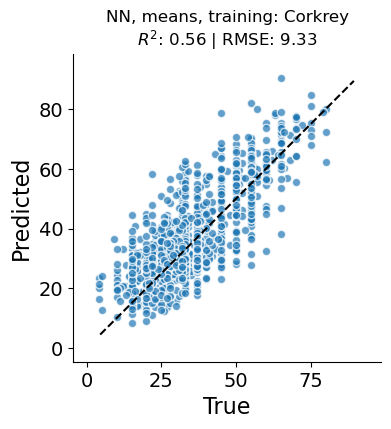

dumping...
Done.


In [28]:
title = 'NN, means, training: Corkrey'
label = 'corkrey_nn_means'

# train NN on corkrey
nn_model = train_model(corkrey_full_embeddings[:, 0, :], corkrey_temps, MLPRegressor, 
                       epochs=200, batch_size=32, lr=1e-3)

nn_preds = nn_model.predict(e_w_c_full_embeddings[:, 0, :]).reshape(1, -1)[0]

torch.save(nn_model.state_dict(), f'./../data/predictive_models/{label}_state_dict.pt')

nn_results = {'best_model':nn_model,
           'best_params':nn_model.state_dict(),
           'predictions':nn_preds,
           'true_values': e_w_c_temps,
           'torch_version':torch.__version__,
           'metadata':{'type':f'Neural network: {str(nn_model)}',
                       'input_shape':corkrey_full_embeddings[:, 0, :].shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(nn_results['true_values'], scaler), 
                 unscale_ogts(nn_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')

print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(nn_results, handle)
print('Done.')

Epoch [10/200], Loss: 1.4144
Epoch [20/200], Loss: 1.2419
Epoch [30/200], Loss: 1.1621
Epoch [40/200], Loss: 1.1385
Epoch [50/200], Loss: 1.0824
Epoch [60/200], Loss: 1.0244
Epoch [70/200], Loss: 1.0428
Epoch [80/200], Loss: 0.9948
Epoch [90/200], Loss: 0.9994
Epoch [100/200], Loss: 0.9562
Epoch [110/200], Loss: 0.9870
Epoch [120/200], Loss: 0.9667
Epoch [130/200], Loss: 0.9276
Epoch [140/200], Loss: 0.8979
Epoch [150/200], Loss: 0.9004
Epoch [160/200], Loss: 0.8813
Epoch [170/200], Loss: 0.8467
Epoch [180/200], Loss: 0.8300
Epoch [190/200], Loss: 0.8464
Epoch [200/200], Loss: 0.7871
4.0 2.0


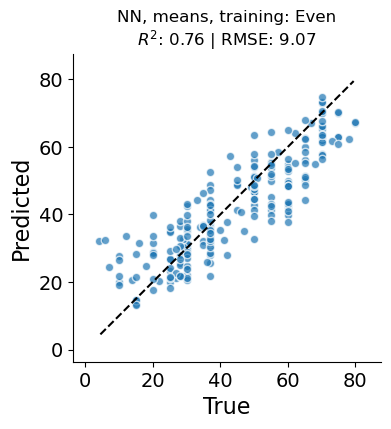

dumping...
Done.


In [29]:
title = 'NN, means, training: Even'
label = 'even_nn_means'

# train NN on corkrey
nn_model = train_model(even_full_embeddings[:, 0, :], even_temps, MLPRegressor, 
                       epochs=200, batch_size=32, lr=1e-4)

nn_preds = nn_model.predict(c_w_e_full_embeddings[:, 0, :]).reshape(1, -1)[0]

torch.save(nn_model.state_dict(), f'./../data/predictive_models/{label}_state_dict.pt')

nn_results = {'best_model':nn_model,
           'best_params':nn_model.state_dict(),
           'predictions':nn_preds,
           'true_values': corkrey_temps,
           'torch_version':torch.__version__,
           'metadata':{'type':f'Neural network: {str(nn_model)}',
                       'input_shape':even_full_embeddings[:, 0, :].shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(nn_results['true_values'], scaler), 
                 unscale_ogts(nn_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')


print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(nn_results, handle)
print('Done.')

## NN with individual embeddings

In [22]:
# class AttentionRegressor(nn.Module):
#     def __init__(self, input_size=768, hidden_size=256):
#         super(AttentionRegressor, self).__init__()
        
#         # 1. Attention Mechanism
#         # This will operate on the last dimension (768) 
#         # to produce a single score for each M.
#         self.attention_net = nn.Sequential(
#             nn.Linear(input_size, hidden_size),
#             nn.Tanh(),
#             nn.Linear(hidden_size, 1)
#         )
        
#         # 2. Regression Head
#         self.regressor = nn.Sequential(
#             nn.Linear(input_size, hidden_size),
#             nn.ReLU(),
#             nn.Dropout(0.1), # Prevents overfitting
#             nn.Linear(hidden_size, hidden_size // 2),
#             nn.ReLU(),
#             nn.Linear(hidden_size // 2, 1)
#         )

#     def forward(self, x, return_attention=False):
#         # Ensure x is (Batch, M, 768)
#         if x.dim() == 2:
#             x = x.unsqueeze(0) # Add batch dim if a single example is passed
            
#         # scores: (Batch, M, 768) -> (Batch, M, 1)
#         scores = self.attention_net(x)
        
#         # weights: (Batch, M, 1) - normalized across the M dimension
#         weights = F.softmax(scores, dim=1)

#         # context_vector: (Batch, M, 1) * (Batch, M, 768) -> (Batch, 768)
#         # We use batch matrix multiplication (bmm) or element-wise + sum
#         context_vector = torch.sum(weights * x, dim=1)
        
        
#         predictions = self.regressor(context_vector)
        
#         if return_attention:
#             return predictions, weights
#         return predictions

#     def predict(self, X, return_weights=False):
#         device = next(self.parameters()).device
#         self.eval()
        
#         if isinstance(X, np.ndarray):
#             X = torch.from_numpy(X).float()
        
#         # Ensure it's on the right device
#         X = X.to(device)
        
#         with torch.no_grad():
#             # If X is 2D (M, 768), make it 3D (1, M, 768)
#             if X.dim() == 2:
#                 X = X.unsqueeze(0)
                
#             if return_weights:
#                 preds, weights = self.forward(X, return_attention=True)
#                 return preds.cpu().numpy(), weights.cpu().numpy()
#             else:
#                 preds = self.forward(X)
#                 return preds.cpu().numpy()

Epoch [10/300], Loss: 9.1943
Epoch [20/300], Loss: 7.2675
Epoch [30/300], Loss: 6.1016
Epoch [40/300], Loss: 5.7754
Epoch [50/300], Loss: 5.1392
Epoch [60/300], Loss: 4.2874
Epoch [70/300], Loss: 3.9123
Epoch [80/300], Loss: 3.0117
Epoch [90/300], Loss: 2.4546
Epoch [100/300], Loss: 1.9054
Epoch [110/300], Loss: 1.7318
Epoch [120/300], Loss: 1.4823
Epoch [130/300], Loss: 1.2849
Epoch [140/300], Loss: 1.3027
Epoch [150/300], Loss: 1.2060
Epoch [160/300], Loss: 1.0856
Epoch [170/300], Loss: 1.0733
Epoch [180/300], Loss: 0.9817
Epoch [190/300], Loss: 1.0287
Epoch [200/300], Loss: 0.9231
Epoch [210/300], Loss: 1.0273
Epoch [220/300], Loss: 0.8517
Epoch [230/300], Loss: 0.8625
Epoch [240/300], Loss: 0.9501
Epoch [250/300], Loss: 0.7203
Epoch [260/300], Loss: 0.7384
Epoch [270/300], Loss: 0.7447
Epoch [280/300], Loss: 0.6331
Epoch [290/300], Loss: 0.6055
Epoch [300/300], Loss: 0.6024
4.0 2.0


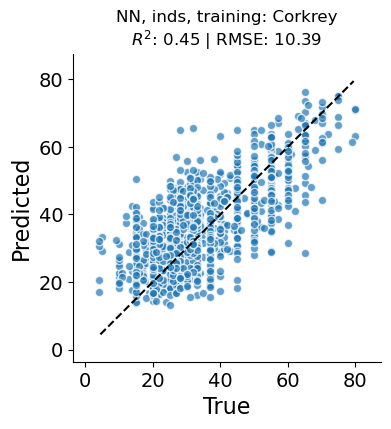

dumping...
Done.


In [30]:
title = 'NN, inds, training: Corkrey'
label = 'corkrey_nn_ind'

# train NN on corkrey
nn_model = train_model(corkrey_full_embeddings, corkrey_temps, AttentionRegressor, 
                       epochs=300, batch_size=32, lr=1e-5)

nn_preds = nn_model.predict(e_w_c_full_embeddings).reshape(1, -1)[0]

torch.save(nn_model.state_dict(), f'./../data/predictive_models/{label}_state_dict.pt')

nn_results = {'best_model':nn_model,
           'best_params':nn_model.state_dict(),
           'predictions':nn_preds,
           'true_values': even_temps,
           'torch_version':torch.__version__,
           'metadata':{'type':f'Neural network: {str(nn_model)}',
                       'input_shape':corkrey_full_embeddings.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(nn_results['true_values'], scaler), 
                 unscale_ogts(nn_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')

print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(nn_results, handle)
print('Done.')

Epoch [10/300], Loss: 2.6220
Epoch [20/300], Loss: 1.6497
Epoch [30/300], Loss: 1.3416
Epoch [40/300], Loss: 1.1949
Epoch [50/300], Loss: 1.1313
Epoch [60/300], Loss: 1.0684
Epoch [70/300], Loss: 1.0241
Epoch [80/300], Loss: 0.9969
Epoch [90/300], Loss: 0.9625
Epoch [100/300], Loss: 0.9394
Epoch [110/300], Loss: 0.9022
Epoch [120/300], Loss: 0.8777
Epoch [130/300], Loss: 0.8469
Epoch [140/300], Loss: 0.8208
Epoch [150/300], Loss: 0.7983
Epoch [160/300], Loss: 0.7571
Epoch [170/300], Loss: 0.7428
Epoch [180/300], Loss: 0.7134
Epoch [190/300], Loss: 0.6967
Epoch [200/300], Loss: 0.6594
Epoch [210/300], Loss: 0.6370
Epoch [220/300], Loss: 0.6210
Epoch [230/300], Loss: 0.5925
Epoch [240/300], Loss: 0.5809
Epoch [250/300], Loss: 0.5693
Epoch [260/300], Loss: 0.5431
Epoch [270/300], Loss: 0.5085
Epoch [280/300], Loss: 0.4872
Epoch [290/300], Loss: 0.4736
Epoch [300/300], Loss: 0.4771
4.0 2.0


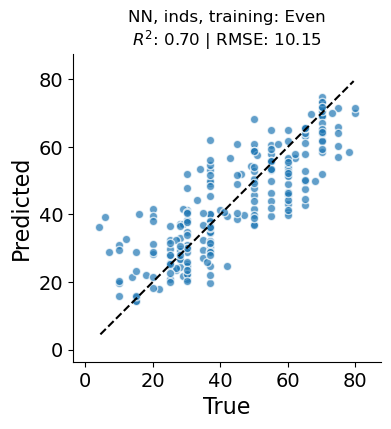

dumping...
Done.


In [31]:
title = 'NN, inds, training: Even'
label = 'even_nn_ind'

# train NN on even
nn_model = train_model(even_full_embeddings, even_temps, AttentionRegressor, 
                       epochs=300, batch_size=32, lr=1e-5)

nn_preds = nn_model.predict(c_w_e_full_embeddings).reshape(1, -1)[0]

torch.save(nn_model.state_dict(), f'./../data/predictive_models/{label}_state_dict.pt')

nn_results = {'best_model':nn_model,
           'best_params':nn_model.state_dict(),
           'predictions':nn_preds,
           'true_values': corkrey_temps,
           'torch_version':torch.__version__,
           'metadata':{'type':f'Neural network: {str(nn_model)}',
                       'input_shape':even_full_embeddings.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(nn_results['true_values'], scaler), 
                 unscale_ogts(nn_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')


print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(nn_results, handle)
print('Done.')

# CV-based baselines for performance

Basically generating a CV-based baseline for each model's loss of performance when blocked on phylogeny using "best params" if possible

In [32]:
gtdb_md = pd.read_csv('/data/mhoffert/genomes/GTDB_r214.1/bac120_metadata.tsv.gz', sep='\t', compression='gzip')

/tmp/ipykernel_3609133/884955836.py:1: DtypeWarning: Columns (61,63,65,74,82,83) have mixed types. Specify dtype option on import or set low_memory=False.
  gtdb_md = pd.read_csv('/data/mhoffert/genomes/GTDB_r214.1/bac120_metadata.tsv.gz', sep='\t', compression='gzip')


In [33]:
# get GTDB accessions for our dataset
msa_keys = dict((i[0].split('|')[1], i[0]) for i in full_msa_dataset)

In [34]:
# make mapping of genome to taxonomy
genome2tax = gtdb_md.set_index('accession').loc[msa_keys.keys(), 'gtdb_taxonomy']
# make sure all records are found
print(len(msa_keys), len(genome2tax))

# split levels into cols
levels = ['domain', 'phylum', 'class', 'order', 'family', 'genus', 'species']
genome2tax = genome2tax.apply(lambda x: pd.Series(index=levels, data=[i.split('__')[-1] for i in x.split(';')]))
# map index to sequences
genome2tax = genome2tax.rename(index=msa_keys)

genome2tax.head()

8532 8532


,domain,phylum,class,order,family,genus,species
accession,,,,,,,
CP000699.1_1354|GB_GCA_000016765.1|adk|temp=30.0|bitscore=175.3,Bacteria,Pseudomonadota,Alphaproteobacteria,Sphingomonadales,Sphingomonadaceae,Rhizorhabdus,Rhizorhabdus wittichii
JH590862.1_220|GB_GCA_000242235.1|adk|temp=37.0|bitscore=192.2,Bacteria,Bacillota_A,Clostridia,Lachnospirales,Lachnospiraceae,Stomatobaculum,Stomatobaculum longum
AP012044.1_910|GB_GCA_000283575.1|adk|temp=30.0|bitscore=168.7,Bacteria,Bacillota_A,Clostridia,Oscillospirales,Oscillospiraceae,Oscillibacter,Oscillibacter valericigenes
AQXR01000011.1_67|GB_GCA_000376885.1|adk|temp=37.0|bitscore=178.2,Bacteria,Actinomycetota,Actinomycetia,Actinomycetales,Bifidobacteriaceae,Alloscardovia,Alloscardovia criceti
KE150266.1_745|GB_GCA_000411155.1|adk|temp=37.0|bitscore=164.5,Bacteria,Actinomycetota,Actinomycetia,Actinomycetales,Actinomycetaceae,Gleimia,Gleimia europaea_B


In [35]:
even_keys = [i[0] for i in even_msa_dataset]
genome2tax.loc[even_keys, 'genus'].value_counts().loc['Arthrobacter']

1

In [36]:
len(even_msa_dataset)

1227

## load data from models

In [37]:
# load data from models
loaded_svr =reload_model('./../data/predictive_models/even_svr_means.pickle')
loaded_svr['best_model']

SVR(C=52.785322414604316, degree=2, epsilon=0.05605645922348988,
    gamma=0.007691806556795077, kernel='poly')

In [41]:
loaded_rf = reload_model('./../data/predictive_models/even_rf_means.pickle')
loaded_rf['best_model']

RandomForestRegressor(criterion='absolute_error', max_depth=28,
                      max_features=None, min_samples_split=0.04441009464893019,
                      n_estimators=390)

## Run training loop

In [92]:
from joblib import Parallel, delayed
import numpy as np

In [124]:
def benchmark_rf_scaling(X, y, rf_params, core_counts):
    results = []
    
    print(f"Starting benchmark on dataset of shape {X.shape}...")
    
    for n in tqdm(core_counts):
        # Update params with current core count
        current_params = rf_params.copy()
        current_params['n_jobs'] = n
        
        rf = RandomForestRegressor(**current_params)
        
        # Measure execution time
        start_time = time.perf_counter()
        rf.fit(X, y)
        end_time = time.perf_counter()
        
        duration = end_time - start_time
        results.append(duration)
        print(f"Cores: {n} | Time: {duration:.2f}s")
        
    return results


In [125]:
# --- Setup ---
# Define the core counts you want to test (e.g., 1, 2, 4, 8, 16, 24)
cores_to_test = [1, 2, 4, 8, 12, 16, 24, 32] 

# Use your existing parameters (extracted from your loaded model)
my_rf_params = {
    'criterion': loaded_rf['best_model'].criterion,
    'max_depth': loaded_rf['best_model'].max_depth,
    'n_estimators': loaded_rf['best_model'].n_estimators,
    'min_samples_split': loaded_rf['best_model'].min_samples_split
}

# Run the benchmark
execution_times = benchmark_rf_scaling(X_train, y_train, my_rf_params, cores_to_test)

Starting benchmark on dataset of shape (1226, 768)...






  0%|                                                                              | 0/8 [00:00<?, ?it/s]



 12%|████████▎                                                         | 1/8 [34:14<3:59:42, 2054.67s/it]

Cores: 1 | Time: 2054.67s






 25%|████████████████▌                                                 | 2/8 [50:54<2:23:25, 1434.27s/it]

Cores: 2 | Time: 999.99s


...

Cores: 16 | Time: 165.88s






 88%|██████████████████████████████████████████████████████████▋        | 7/8 [1:13:35<05:30, 330.09s/it]

Cores: 24 | Time: 151.45s






100%|███████████████████████████████████████████████████████████████████| 8/8 [1:15:54<00:00, 569.26s/it]

Cores: 32 | Time: 138.92s


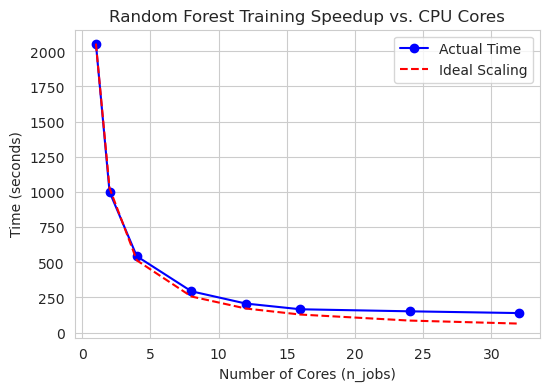

In [127]:
# --- Plotting ---
plt.figure(figsize=(6, 4))
sns.set_style("whitegrid")

# Plot actual times
plt.plot(cores_to_test, execution_times, marker='o', linestyle='-', color='b', label='Actual Time')

# Plot "Ideal" scaling (Time / N)
ideal_time = [execution_times[0] / n for n in cores_to_test]
plt.plot(cores_to_test, ideal_time, linestyle='--', color='r', label='Ideal Scaling')

plt.title('Random Forest Training Speedup vs. CPU Cores')
plt.xlabel('Number of Cores (n_jobs)')
plt.ylabel('Time (seconds)')
plt.legend()
plt.show()

In [128]:
# 1. Pre-extract parameters to avoid dict lookups in the loop
rf_params = {
    'criterion': loaded_rf['best_model'].criterion,
    'max_depth': loaded_rf['best_model'].max_depth,
    'min_samples_split': loaded_rf['best_model'].min_samples_split,
    'n_estimators': loaded_rf['best_model'].n_estimators,
    'n_jobs': 12 # Set to 1 because we will parallelize the taxon loop instead
}

svr_params = {'C':loaded_svr['best_model'].C, 
                  'degree':loaded_svr['best_model'].degree, 
                  'epsilon':loaded_svr['best_model'].epsilon, 
                  'gamma':loaded_svr['best_model'].gamma, 
                  'kernel':loaded_svr['best_model'].kernel}

In [129]:
# parallelized
def process_taxon(level, taxon, X_full, y_full, subset_level_data):
    local_errors = []
    
    # Fast boolean indexing
    is_test = (subset_level_data == taxon).values
    X_train, X_test = X_full[~is_test], X_full[is_test]
    y_train, y_test = y_full[~is_test], y_full[is_test]
    
    if len(y_test) == 0: return []

    # ElasticNet
    enet = ElasticNet(alpha=0.29).fit(X_train, y_train)
    err = np.sqrt(mean_squared_error(y_test, enet.predict(X_test)))
    local_errors.append({'level': level, 'taxon': taxon, 'error': err, 'model': 'ElasticNet'})

    # svr
    svr = SVR(**svr_params).fit(X_train, y_train)
    err = np.sqrt(mean_squared_error(y_test, svr.predict(X_test)))
    local_errors.append({'level': level, 'taxon': taxon, 'error': err, 'model': 'SVR'})

    # rf
    # print('rf')
    rf = RandomForestRegressor(**rf_params).fit(X_train, y_train)
    err = np.sqrt(mean_squared_error(y_test, rf.predict(X_test)))
    local_errors.append({'level': level, 'taxon': taxon, 'error': err, 'model': 'RF'})

    # lm
    # print('lm')
    lm = sm.WLS(y_train, X_train).fit()
    err = np.sqrt(mean_squared_error(y_test, lm.predict(X_test)))
    local_errors.append({'level': level, 'taxon': taxon, 'error': err, 'model': 'LM'})

    # gpr
    # print('gpr')    
    kernel = C(1.0) * RBF(1.0) + WhiteKernel(noise_level=1e-1)
    gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=5, random_state=1234)
    gpr.fit(X_train, y_train)
    gpr_pred_mu, gpr_pred_std = gpr.predict(X_test, return_std=True)
    err = np.sqrt(mean_squared_error(y_test, gpr_pred_mu))
    local_errors.append({'level': level, 'taxon': taxon, 'error': err, 'model': 'GPR'})

    ## nn
    # print('nn')        
    nn_model = train_model(X_train, y_train, MLPRegressor, 
                   epochs=200, batch_size=32, lr=1e-4)
    err = np.sqrt(mean_squared_error(y_test, nn_model.predict(X_test).reshape(1, -1)[0]))
    local_errors.append({'level': level, 'taxon': taxon, 'error': err, 'model': 'NN'})
    
    
    return local_errors

In [ ]:
%%time
# Execute in Parallel

subset =  genome2tax.loc[[i[0] for i in even_msa_dataset], :].copy()
errors = []

emb_scaler = StandardScaler()
scaled_even_full = emb_scaler.fit_transform(even_full_embeddings[:, 0, :])

all_results = []
for level in subset.columns[1:]:
    print(f"Processing level: {level}")
    taxons = subset[level].unique()
    
    # This parallelizes the processing of taxons
    results = Parallel(n_jobs=3)( # Use -1 for all cores
        delayed(process_taxon)(level, t, scaled_even_full, even_temps, subset[level]) 
        for t in tqdm(taxons)
    )
    
    # Flatten results
    for res in results:
        all_results.extend(res)

errors_df = pd.DataFrame(all_results)

Processing level: phylum






  0%|                                                                             | 0/35 [00:00<?, ?it/s]



  9%|█████▉                                                               | 3/35 [00:00<00:05,  5.95it/s]



 17%|███████████▊                                                         | 6/35 [08:14<46:53, 97.02s/it]



 26%|█████████████████▍                                                  | 9/35 [13:39<44:13, 102.06s/it]



 34%|██████████████████████▉                                            | 12/35 [21:17<46:48, 122.12s/it]



 43%|████████████████████████████▋                                      | 15/35 [29:36<46:00, 138.04s/it]



 51%|██████████████████████████████████▍                                | 18/35 [38:18<42:33, 150.22s/it]



 60%|████████████████████████████████████████▏                          | 21/35 [46:55<36:44, 157.44s/it]



 69%|█████████████████████████████████████████████▉                     | 24/35 [54:29<28:31, 155.58s/it]



 77%|██████████

Processing level: class






  0%|                                                                             | 0/63 [00:00<?, ?it/s]



 10%|██████▍                                                            | 6/63 [08:16<1:18:39, 82.80s/it]

Epoch [10/200], Loss: 0.8340
Epoch [20/200], Loss: 0.5687
Epoch [30/200], Loss: 0.3471
Epoch [40/200], Loss: 0.2272
Epoch [50/200], Loss: 0.1817
Epoch [60/200], Loss: 0.1288
Epoch [70/200], Loss: 0.1133
Epoch [80/200], Loss: 0.1009
Epoch [90/200], Loss: 0.0805
Epoch [100/200], Loss: 0.0713
Epoch [110/200], Loss: 0.0699
Epoch [120/200], Loss: 0.0664
Epoch [130/200], Loss: 0.0599
Epoch [140/200], Loss: 0.0545
Epoch [150/200], Loss: 0.0552
Epoch [160/200], Loss: 0.0551
Epoch [170/200], Loss: 0.0502
Epoch [180/200], Loss: 0.0490
Epoch [190/200], Loss: 0.0436
Epoch [200/200], Loss: 0.0435
Epoch [10/200], Loss: 0.9440
Epoch [20/200], Loss: 0.6243
Epoch [30/200], Loss: 0.3873
Epoch [40/200], Loss: 0.2304
Epoch [50/200], Loss: 0.1677
Epoch [60/200], Loss: 0.1266
Epoch [70/200], Loss: 0.0982
Epoch [80/200], Loss: 0.0836
Epoch [90/200], Loss: 0.0739
Epoch [100/200], Loss: 0.0673
Epoch [110/200], Loss: 0.0529
Epoch [120/200], Loss: 0.0575
Epoch [130/200], Loss: 0.0569
Epoch [140/200], Loss: 0.049

...





 37%|█████████████████████▍                                    | 453/1227 [21:33:25<37:23:20, 173.90s/it]



 37%|█████████████████████▌                                    | 456/1227 [21:41:29<36:26:01, 170.12s/it]

Epoch [90/200], Loss: 0.0904
Epoch [100/200], Loss: 0.0901
Epoch [110/200], Loss: 0.0747
Epoch [120/200], Loss: 0.0637
Epoch [130/200], Loss: 0.0632
Epoch [140/200], Loss: 0.0546
Epoch [150/200], Loss: 0.0541
Epoch [160/200], Loss: 0.0517
Epoch [170/200], Loss: 0.0566
Epoch [180/200], Loss: 0.0442
Epoch [190/200], Loss: 0.0471
Epoch [200/200], Loss: 0.0465
Epoch [10/200], Loss: 0.8697
Epoch [20/200], Loss: 0.5876
Epoch [30/200], Loss: 0.3663
Epoch [40/200], Loss: 0.2308
Epoch [50/200], Loss: 0.1658
Epoch [60/200], Loss: 0.1433
Epoch [70/200], Loss: 0.0982
Epoch [80/200], Loss: 0.0869
Epoch [90/200], Loss: 0.0832
Epoch [100/200], Loss: 0.0755
Epoch [110/200], Loss: 0.0767
Epoch [120/200], Loss: 0.0673
Epoch [130/200], Loss: 0.0551
Epoch [140/200], Loss: 0.0555
Epoch [150/200], Loss: 0.0579
Epoch [160/200], Loss: 0.0476
Epoch [170/200], Loss: 0.0460
Epoch [180/200], Loss: 0.0480
Epoch [190/200], Loss: 0.0408
Epoch [200/200], Loss: 0.0477
Epoch [10/200], Loss: 0.8479
Epoch [20/200], Loss:





 37%|█████████████████████▋                                    | 459/1227 [21:50:48<37:20:01, 175.00s/it]

Epoch [90/200], Loss: 0.0892
Epoch [100/200], Loss: 0.0766
Epoch [110/200], Loss: 0.0702
Epoch [120/200], Loss: 0.0615
Epoch [130/200], Loss: 0.0596
Epoch [140/200], Loss: 0.0612
Epoch [150/200], Loss: 0.0593
Epoch [160/200], Loss: 0.0492
Epoch [170/200], Loss: 0.0503
Epoch [180/200], Loss: 0.0451
Epoch [190/200], Loss: 0.0484
Epoch [200/200], Loss: 0.0514
Epoch [10/200], Loss: 0.8281
Epoch [20/200], Loss: 0.5755
Epoch [30/200], Loss: 0.3682
Epoch [40/200], Loss: 0.2450
Epoch [50/200], Loss: 0.1732
Epoch [60/200], Loss: 0.1466
Epoch [70/200], Loss: 0.1079
Epoch [80/200], Loss: 0.1014
Epoch [90/200], Loss: 0.0829
Epoch [100/200], Loss: 0.0781
Epoch [110/200], Loss: 0.0727
Epoch [120/200], Loss: 0.0694
Epoch [130/200], Loss: 0.0679
Epoch [140/200], Loss: 0.0514
Epoch [150/200], Loss: 0.0520
Epoch [160/200], Loss: 0.0558
Epoch [170/200], Loss: 0.0441
Epoch [180/200], Loss: 0.0469
Epoch [190/200], Loss: 0.0461
Epoch [200/200], Loss: 0.0501
Epoch [10/200], Loss: 0.8367
Epoch [20/200], Loss:





 38%|█████████████████████▊                                    | 462/1227 [21:58:38<36:00:18, 169.44s/it]

In [133]:
errors_df = pd.DataFrame(all_results)
errors_df

,level,taxon,error,model
0,phylum,Desulfobacterota,1.256143,ElasticNet
1,phylum,Desulfobacterota,2.211185,SVR
2,phylum,Desulfobacterota,1.342442,RF
3,phylum,Desulfobacterota,2.188698,LM
4,phylum,Desulfobacterota,1.172930,GPR
...,...,...,...,...
8509,genus,Cupriavidus,0.661249,SVR
8510,genus,Cupriavidus,0.112546,RF
8511,genus,Cupriavidus,0.485715,LM
8512,genus,Cupriavidus,0.132474,GPR


In [134]:
errors_df.to_csv('./../data/predictive_models/supporting_data/taxonomic_cv_results.tsv', sep='\t')

In [112]:
# old code
# %%time
# # even_msa_dataset: a list of MSA sequences

# subset =  genome2tax.loc[[i[0] for i in even_msa_dataset], :].copy()
# errors = []

# emb_scaler = StandardScaler()
# scaled_even_full = emb_scaler.fit_transform(even_full_embeddings[:, 0, :])

# for level_i, level in enumerate(subset.columns[1:2]):
#     print(level)
#     for taxon in tqdm(subset.loc[:, level].unique()):
#         train_inds = [i for i in range(len(even_msa_dataset)) if subset.iloc[i, level_i+1] != taxon]
#         test_inds = [i for i in range(len(even_msa_dataset)) if subset.iloc[i, level_i+1] == taxon]
                
#         # add assert here to ensure no overlap of train and test
#         assert set(train_inds).intersection(set(test_inds)) == set(), 'train and test overlap'
        
#         X_train = scaled_even_full[train_inds, :]
#         y_train = even_temps[train_inds]
#         X_test = scaled_even_full[test_inds, :]
#         y_test = even_temps[test_inds]

#         print('enet')
#         # elastic net
#         enet = ElasticNet(alpha=0.29, n_jobs=4)
#         enet.fit(X_train, y_train)
#         enet_pred = enet.predict(X_test)
#         error = np.sqrt(mean_squared_error(y_test, enet_pred))
#         errors.append(pd.Series(index=['level', 'taxon', 'error', 'model'],
#                                 data=[level, taxon, error, 'ElasticNet']))

#         # lm, wls
#         print('lm')
#         lm = sm.WLS(y_train, X_train).fit()
#         lm_pred = lm.predict(X_test)
#         error = np.sqrt(mean_squared_error(y_test, lm_pred))
#         errors.append(pd.Series(index=['level', 'taxon', 'error', 'model'],
#                                 data=[level, taxon, error, 'OLS']))

#         # svr
#         print('svr')
#         svr = SVR(C=loaded_svr['best_model'].C, 
#                   degree=loaded_svr['best_model'].degree, 
#                   epsilon=loaded_svr['best_model'].epsilon, 
#                   gamma=loaded_svr['best_model'].gamma, 
#                   kernel=loaded_svr['best_model'].kernel)
#         svr.fit( X_train, y_train)
#         svr_pred = svr.predict(X_test)
#         error = np.sqrt(mean_squared_error(y_test, svr_pred))
#         errors.append(pd.Series(index=['level', 'taxon', 'error', 'model'],
#                                 data=[level, taxon, error, 'SVR']))

#         # # rf
#         # print('rf')
#         # rf = RandomForestRegressor(criterion=loaded_rf['best_model'].criterion, 
#         #           max_depth=loaded_rf['best_model'].max_depth, 
#         #           min_samples_split=loaded_rf['best_model'].min_samples_split, 
#         #           n_estimators=loaded_rf['best_model'].n_estimators,
#         #           n_jobs=24)
#         # rf.fit( X_train, y_train)
#         # rf_pred = rf.predict(X_test)
#         # error = np.sqrt(mean_squared_error(y_test, rf_pred))
#         # errors.append(pd.Series(index=['level', 'taxon', 'error', 'model'],
#         #                         data=[level, taxon, error, 'RF']))
        
#         # # nn
#         # print('nn')        
#         # nn_model = train_model(X_train, y_train, MLPRegressor, 
#         #                epochs=200, batch_size=32, lr=1e-4)

#         # nn_pred = nn_model.predict(X_test).reshape(1, -1)[0]
#         # error = np.sqrt(mean_squared_error(y_test, nn_pred))
#         # errors.append(pd.Series(index=['level', 'taxon', 'error', 'model'],
#         #                         data=[level, taxon, error, 'NN']))
#         # # gpr
#         # print('gpr')
#         # kernel = C(1.0) * RBF(1.0) + WhiteKernel(noise_level=1e-1)
#         # gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=5, random_state=1234)
#         # gpr.fit(X_train, y_train)
#         # gpr_pred_mu, gpr_pred_std = gpr.predict(X_test, return_std=True)
#         # error = np.sqrt(mean_squared_error(y_test, gpr_pred_mu))
#         # errors.append(pd.Series(index=['level', 'taxon', 'error', 'model'],
#         #                         data=[level, taxon, error, 'GPR']))

        
#     clear_output(wait=True)
    
# tax_cv_plotdf = pd.concat(errors, axis=1).T

# tax_cv_plotdf.to_csv('./../data/predictive_models/supporting_data/tax_cv_plotdf.tsv', sep='\t')

CPU times: user 16min 4s, sys: 10min 46s, total: 26min 50s
Wall time: 3min 4s


<Axes: xlabel='error', ylabel='error'>

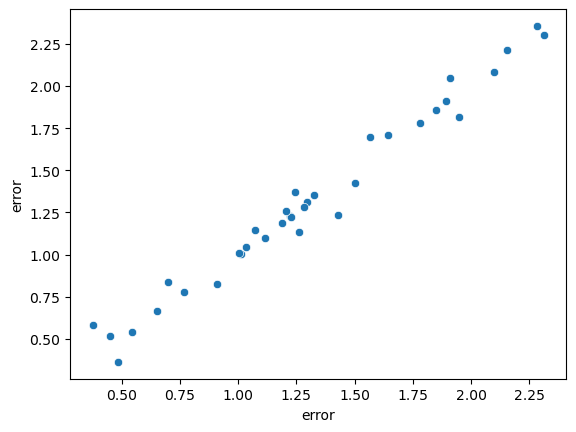

In [104]:
temp_y = errors_df.set_index('taxon')['error']
temp_x = tax_cv_plotdf[tax_cv_plotdf['level'].eq('phylum') & tax_cv_plotdf['model'].eq('ElasticNet')].set_index('taxon')['error']
sns.scatterplot(x=temp_x, y=temp_y)

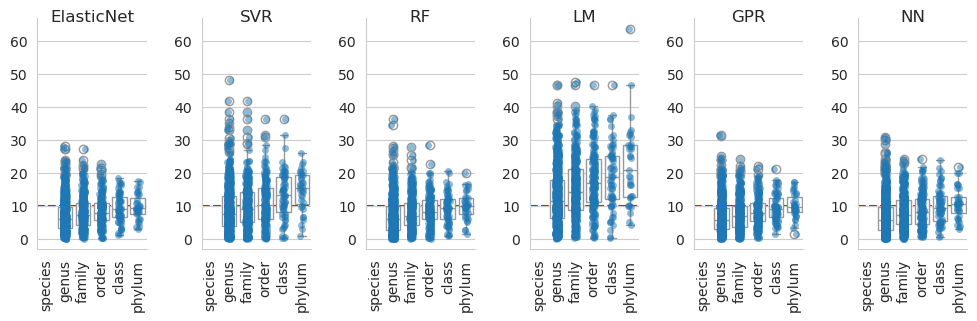

In [135]:
# plot of accuracies

fig = plt.figure(figsize=(12, 3))


axes = []
for i, model in enumerate(errors_df['model'].unique()):
   
    if i == 0:
        ax = fig.add_subplot(1,6,i+1)
        axes.append(ax)
    else:
        ax = fig.add_subplot(1,6,i+1, sharey=axes[0])
        axes.append(ax)

    ax.axhline(10, color='r', linestyle='--', zorder=0)
    
    plot_subset = errors_df[errors_df['model'].eq(model)]
    sns.boxplot(data=plot_subset,
              x='level',
              y=plot_subset['error'] * scaler.scale_,
              order=levels[1:][::-1],
              color='white', zorder=1)

    sns.stripplot(data=plot_subset,
          x='level',
          y=plot_subset['error'] * scaler.scale_,
          order=levels[1:][::-1],
          zorder=2, alpha=0.5)

    ax.set_xlabel('')
    ax.set_ylabel('')
    sns.despine()
    ax.set_title(model, y=0.95)
    plt.tick_params(rotation=90, axis='x')

fig.subplots_adjust(wspace=0.5)

In [78]:
plot_subset

,level,taxon,error,model
1,phylum,Desulfobacterota,2.188698,OLS
7,phylum,Cyanobacteriota,2.170898,OLS
13,phylum,Spirochaetota,3.666632,OLS
19,phylum,Pseudomonadota,8.537362,OLS
25,phylum,Bacteroidota,3.835045,OLS
...,...,...,...,...
1675,family,Shewanellaceae,2.486379,OLS
1681,family,Micrococcaceae,3.691559,OLS
1687,family,Chlorobiaceae,0.667657,OLS
1693,family,Thermodesulfovibrionaceae,2.391538,OLS


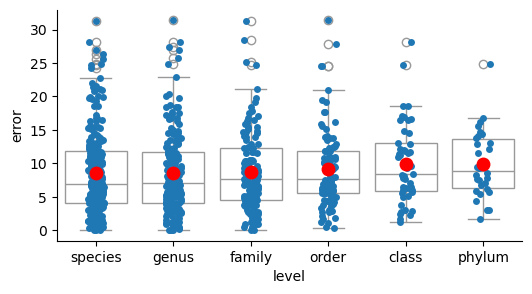

In [127]:
fig, ax = plt.subplots(figsize=(6, 3))
# tax_cv_plotdf = pd.concat(errors, axis=1).T

sns.boxplot(data=tax_cv_plotdf,
              x='level',
              y=tax_cv_plotdf['error'] * scaler.scale_,
              order=levels[1:][::-1],
              color='white', zorder=0)

sns.stripplot(data=tax_cv_plotdf,
              x='level',
              y=tax_cv_plotdf['error'] * scaler.scale_,
              order=levels[1:][::-1], zorder=1)

group_df = tax_cv_plotdf.groupby('level').apply(lambda x: (x['error'].mean() * scaler.scale_)[0]).reset_index() 
sns.stripplot(data=group_df,
               x='level', s=10,
                y=0, color='r', zorder=2)

sns.despine()

# Code for Tuned MSATransformer

In [19]:
def visualize_esm_separation(esm_model, converter, data_list, n_comps=2, title="ESM Embedding Space"):
    esm_model.eval()
    embeddings = []
    temperatures = []
    
    print(f"Extracting embeddings for visualization: {title}...")
    with torch.no_grad():
        for item in tqdm(data_list):
            # Prepare a simple MSA for extraction
            context = random.sample(data_list, 3) # Minimal context for speed
            msa = [(item[0], item[1])] + [(c[0], c[1]) for c in context]
            _, _, tokens = converter(msa)
            
            # Extract Layer 12 Mean-Pooled embedding
            output = esm_model(tokens, repr_layers=[12])["representations"][12]
            emb = output[:, 0, :, :].mean(dim=1).squeeze(0).cpu().numpy()
            
            embeddings.append(emb)
            temperatures.append(item[2])
            
    # Reduce to 2D
    pca = PCA(n_components=n_comps)
    pca_results = pca.fit_transform(np.array(embeddings))
    
    # Plotting
    plt.figure(figsize=(8, 6))
    sc = plt.scatter(pca_results[:, 0], pca_results[:, 1], 
                     c=temperatures, cmap='coolwarm', alpha=0.7, edgecolors='w')
    plt.colorbar(sc, label='Normalized OGT')
    plt.title(title)
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    sns.despine()
    # plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    return pca, pca_results

In [20]:
def compare_esm_parameters(untuned_model, tuned_model):
    """
    Compares two ESM models and returns a report on which layers changed
    and by how much (using Frobenius Norm of the weight differences).
    """
    comparison_data = []
    
    # Get all parameters from both models
    untuned_params = dict(untuned_model.named_parameters())
    tuned_params = dict(tuned_model.named_parameters())
    

    
    for name, p_untuned in untuned_params.items():
        p_tuned = tuned_params[name]
        
        # Calculate the absolute difference between weights
        diff = torch.abs(p_untuned - p_tuned).sum().item()
        
        # Calculate Frobenius Norm of the difference for a more standard metric
        # (Square root of the sum of squares)
        norm_diff = torch.norm(p_untuned - p_tuned, p='fro').item()
        
        status = "CHANGED" if diff > 0 else "FIXED"
        
        # Only log layers that actually have weights (ignore biases for brevity if desired)
        if "weight" in name:
            comparison_data.append({
                "Layer": name,
                "Status": status,
                "Delta_Norm": norm_diff
            })
            
            # Print highlights to console
            if diff > 0:
                print(f"{name:<60} | {status:<10} | {norm_diff:<20.6f}")

    return pd.DataFrame(comparison_data)

In [159]:
# load ESM model
esm_msa_model, alphabet = esm.pretrained.esm_msa1b_t12_100M_UR50S()
conv = alphabet.get_batch_converter()
# turn off gradients
for name, param in esm_msa_model.named_parameters():
    param.requires_grad = False

In [160]:
original_esm_snapshot = copy.deepcopy(esm_msa_model)

In [162]:
# pca, pca_results = visualize_esm_separation(esm_msa_model, conv, even_msa_dataset, 5, "Untuned ESM Space")

In [163]:
scaler.scale_

array([7.49758668])

## Tuning ESM-MSA

In [164]:
# def matrix_consistency_loss(dist_emb, dist_ogt):
#     # 1. Get indices for the upper triangle (excluding the diagonal)
#     # This turns the 8x8 matrix into a 1D vector of 28 unique pairwise distances
#     indices = torch.triu_indices(8, 8, offset=1)
    
#     # 2. Extract the values
#     v_emb = dist_emb[indices[0], indices[1]]
#     v_ogt = dist_ogt[indices[0], indices[1]]
    
#     # 3. Compute MSE Loss
#     # You can also use SmoothL1Loss if you want it to be less sensitive to outliers
#     return torch.nn.functional.mse_loss(v_emb, v_ogt)

def matrix_consistency_loss(dist_emb, dist_ogt, log_scale):
    indices = torch.triu_indices(8, 8, offset=1)
    
    # Extract values
    v_emb = dist_emb[indices[0], indices[1]]
    v_ogt = dist_ogt[indices[0], indices[1]]
    
    # Apply learnable scale factor
    # scale * dist_emb should match dist_ogt
    scale = torch.exp(log_scale)
    scaled_v_emb = v_emb * scale
    
    return torch.nn.functional.mse_loss(scaled_v_emb, v_ogt)

def tune_esm_separation(esm_model, 
                        converter, 
                        data_list, 
                        epochs=3):
    
    # We only want to train the last few layers of ESM to maintain structural knowledge
    # but allow for OGT specialization.
    
    esm_model.train()
    
    for name, param in esm_model.named_parameters():
        param.requires_grad = False
        
        # if "layers.11" in name or "layers.10" in name: # Tune last 2 layers
        #     param.requires_grad = True
        if "column_self_attention" in name:
            param.requires_grad = True

        if "feed_forward_layer" in name:
            param.requires_grad = True

        # unfix all layer norms
        if "layer_norm.weight" in name:
            param.requires_grad = True

    # Initialize scale at 1.0 (or a value close to your expected ratio)
    log_scale = nn.Parameter(torch.tensor([0.0])) # We use log_scale for numerical stability
    
    # Add it to your optimizer
    optimizer = torch.optim.Adam(
        list(filter(lambda p: p.requires_grad, esm_model.parameters())) + [log_scale], 
        lr=5e-6
    )
    # old optimizer: no scaling
    # optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, esm_model.parameters()), lr=5e-6)
    
    np.random.shuffle(data_list)
    for epoch in range(epochs):
        pbar = tqdm(data_list, desc=f"Tuning ESM Epoch {epoch}")
        for item in pbar:
            
            # Prepare MSA (random context)
            context = random.sample(data_list, 7)
            msa = [(item[0], item[1])] + [(c[0], c[1]) for c in context]
            _, _, tokens = converter(msa)
            ogts = torch.tensor([item[2]] + [c[2] for c in context], dtype=torch.float).view(-1,1)
            
            optimizer.zero_grad()
            
            # Extract Mean-Pooled Embedding from Layer 12
            output = esm_model(tokens, repr_layers=[12])["representations"][12]
            # use cls token
            emb = output[:, :, 0, :] # [context length, 768]

            dists = torch.cdist(emb, emb, p=2)[0]
            ogt_diffs = torch.cdist(ogts, ogts, p=2)
            
            # loss = matrix_consistency_loss(dists, ogt_diffs)
            loss = matrix_consistency_loss(dists, ogt_diffs, log_scale)
            loss.backward()

            optimizer.step()

            pbar.set_postfix(loss=f"{float(loss):.3f}" if 'loss' in locals() else "N/A",)

    return esm_model

In [31]:
_, _, tokens = conv([(i[0], i[1]) for i in corkrey_msa_dataset[:8]])
emb = esm_msa_model(tokens, repr_layers=[12])
emb['representations'][12].mean(dim=2).shape

torch.Size([1, 8, 768])

In [165]:
tuned_esm = tune_esm_separation(esm_msa_model, 
                                conv, 
                                even_msa_dataset,
                                epochs=10)

Tuning ESM Epoch 9: 100%|█████████| 997/997 [25:06<00:00,  1.51s/it, loss=0.268]


In [166]:
comparison = compare_esm_parameters(original_esm_snapshot, tuned_esm)
print(comparison['Status'].value_counts())
comparison

layers.0.row_self_attention.layer_norm.weight                | CHANGED    | 0.022667            
layers.0.column_self_attention.layer.k_proj.weight           | CHANGED    | 0.384809            
layers.0.column_self_attention.layer.v_proj.weight           | CHANGED    | 0.398486            
layers.0.column_self_attention.layer.q_proj.weight           | CHANGED    | 0.399374            
layers.0.column_self_attention.layer.out_proj.weight         | CHANGED    | 0.376633            
layers.0.column_self_attention.layer_norm.weight             | CHANGED    | 0.015406            
layers.0.feed_forward_layer.layer.fc1.weight                 | CHANGED    | 0.807297            
layers.0.feed_forward_layer.layer.fc2.weight                 | CHANGED    | 0.692738            
layers.0.feed_forward_layer.layer_norm.weight                | CHANGED    | 0.014050            
layers.1.row_self_attention.layer_norm.weight                | CHANGED    | 0.013290            
layers.1.column_self_attention

,Layer,Status,Delta_Norm
0,embed_tokens.weight,FIXED,0.0
1,layers.0.row_self_attention.layer.k_proj.weight,FIXED,0.0
2,layers.0.row_self_attention.layer.v_proj.weight,FIXED,0.0
3,layers.0.row_self_attention.layer.q_proj.weight,FIXED,0.0
4,layers.0.row_self_attention.layer.out_proj.weight,FIXED,0.0
...,...,...,...
158,embed_positions.weight,FIXED,0.0
159,emb_layer_norm_before.weight,FIXED,0.0
160,emb_layer_norm_after.weight,FIXED,0.0
161,lm_head.dense.weight,FIXED,0.0


Extracting embeddings for visualization: Tuned ESM Space...


100%|█████████████████████████████████████████| 997/997 [04:30<00:00,  3.68it/s]


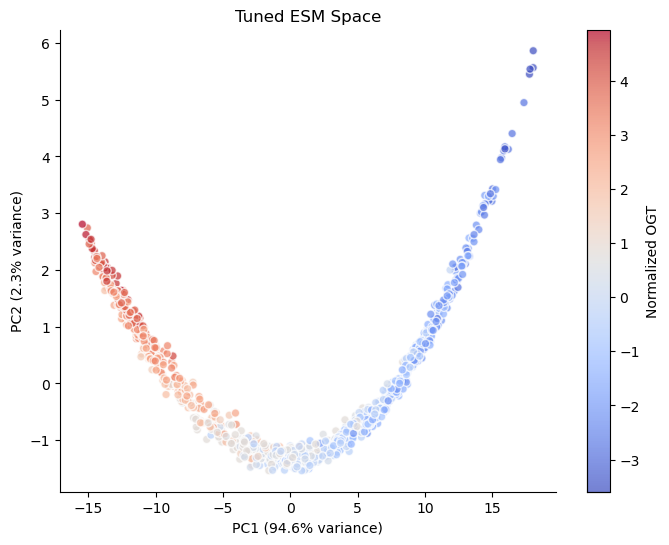

In [167]:
tuned_pca, tuned_pca_results = visualize_esm_separation(tuned_esm, conv, even_msa_dataset, 5, "Tuned ESM Space")

In [168]:
tuned_pca, tuned_pca_results = visualize_esm_separation(tuned_esm, conv, even_msa_dataset, 5, "Tuned ESM Space")

Extracting embeddings for visualization: Tuned ESM Space...


 49%|████████████████████▏                    | 492/997 [02:10<02:14,  3.76it/s]


KeyboardInterrupt: 

In [184]:
test_keys = set([i[0] for i in corkrey_msa_dataset])
np.sum([i[0] in test_keys for i in even_msa_dataset])

0

In [185]:
emb, temps = get_embeddings(tuned_esm, conv, 
                            data_to_embed=corkrey_msa_dataset, 
                            training_context=even_msa_dataset, n_context=4, return_mean=True)

TypeError: get_embeddings() got an unexpected keyword argument 'n_context'

In [187]:
trans_emb = tuned_pca.transform(tuned_c_w_e_full_embeddings[:, 0, :])

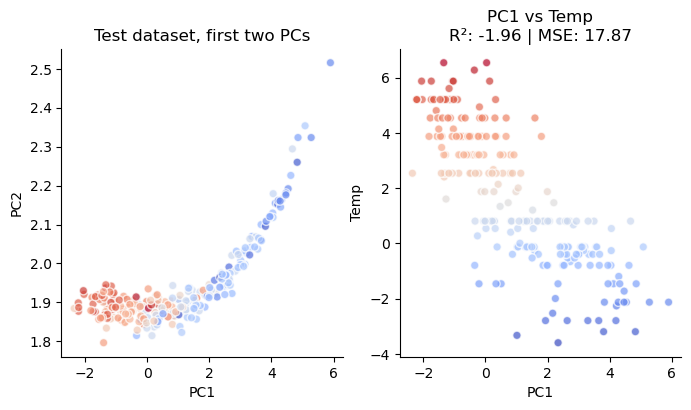

In [190]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,2,1)
ax.scatter(trans_emb[:, 0], trans_emb[:, 1], 
                 c=c_w_e_temps, cmap='coolwarm', alpha=0.7, edgecolors='w')
sns.despine()
ax.set_title('Test dataset, first two PCs')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax = fig.add_subplot(1,2,2)
# plt.scatter(y=trans_emb[:, 0], x=temps, c=temps, cmap='coolwarm')
preds = np.array(trans_emb[:, 0])
y_test = np.array(c_w_e_temps)
ax.scatter(y=y_test, x=preds, c=y_test, 
           cmap='coolwarm', alpha=0.7, edgecolors='w', zorder=1)
# ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', zorder=0)

r2 = r2_score(y_test, preds)
mse = mean_squared_error(y_test, preds)

ax.set_title(f"PC1 vs Temp\nR²: {r2:.2f} | MSE: {mse:.2f}")
ax.set_ylabel('Temp')
ax.set_xlabel('PC1')
sns.despine()

In [ ]:
[i[0] even_msa_dataset

## new, tuned embeddings

In [169]:
random_context = get_random_context(even_msa_dataset, 
                                    n_contexts=None, # not used
                                    context_size=8,
                                    self=True
                                   )

# get embeddings
tuned_even_full_embeddings, even_temps, even_full_context = get_embeddings(tuned_esm, 
                                    conv, 
                                    even_msa_dataset, 
                                    even_msa_dataset, 
                                    random_context,
                                    layer=12, return_mean=False)

100%|█████████████████████████████████████████| 997/997 [09:59<00:00,  1.66it/s]


In [170]:
random_context = get_random_context(corkrey_msa_dataset, 
                                    n_contexts=None, # not used
                                    context_size=8,
                                    self=True
                                   )

# get embeddings
tuned_corkrey_full_embeddings, corkrey_temps, corkrey_full_context = get_embeddings(tuned_esm, 
                                    conv, 
                                    corkrey_msa_dataset, 
                                    corkrey_msa_dataset, 
                                    random_context,
                                    layer=12, return_mean=False)

100%|█████████████████████████████████████████| 243/243 [02:22<00:00,  1.71it/s]


In [171]:
random_context = get_random_context(corkrey_msa_dataset, 
                                    n_contexts=len(even_msa_dataset),
                                    context_size=8,
                                    self=False
                                   )

# get embeddings
tuned_e_w_c_full_embeddings, e_w_c_temps, e_w_c_context = get_embeddings(tuned_esm, 
                                    conv, 
                                    even_msa_dataset, 
                                    corkrey_msa_dataset, 
                                    random_context,
                                    layer=12, return_mean=False)

100%|█████████████████████████████████████████| 997/997 [10:02<00:00,  1.65it/s]


In [172]:
random_context = get_random_context(even_msa_dataset, 
                                    n_contexts=len(corkrey_msa_dataset),
                                    context_size=8,
                                    self=False
                                   )

# get embeddings
tuned_c_w_e_full_embeddings, c_w_e_temps, c_w_e_context = get_embeddings(tuned_esm, 
                                    conv, 
                                    corkrey_msa_dataset, 
                                    even_msa_dataset, 
                                    random_context,
                                    layer=12, return_mean=False)

100%|█████████████████████████████████████████| 243/243 [02:22<00:00,  1.71it/s]


# Save data

In [104]:
# Define your save path
SAVE_PATH = "./../data/predictive_models/tuned_msa_transformer.pt"

# It is best practice to save the weights along with the alphabet name
# so you know exactly which base model to load later.
checkpoint = {
    'model_state_dict': tuned_esm.state_dict(),
    'alphabet_data': {
        'name': "esm_msa1b_t12_100M_UR50S",
        'all_tokenize_data': alphabet  # Optional: helps preserve custom tokens
    },
    # If your 'tune_model' function modified specific hyperparams, save them here
    'params': {
        'frozen_layers': True,
        'model_type': 'msa_transformer'
    }
}

torch.save(checkpoint, SAVE_PATH)
print(f"Model saved successfully to {SAVE_PATH}")

Model saved successfully to ./../data/predictive_models/tuned_msa_transformer.pt


In [105]:
# 1. Load the checkpoint
checkpoint = torch.load("./../data/predictive_models/tuned_msa_transformer.pt")

# 2. Re-initialize the base architecture and alphabet
# We use the name stored in our checkpoint to ensure a match
model_name = checkpoint['alphabet_data']['name']
reloaded_model, alphabet = esm.pretrained.esm_msa1b_t12_100M_UR50S()

# 3. Load the tuned weights into the model
reloaded_model.load_state_dict(checkpoint['model_state_dict'])

# 4. Re-apply your gradient settings
for param in reloaded_model.parameters():
    param.requires_grad = False

reloaded_model.eval() # Set to inference mode
print("Tuned model reloaded and ready for use.")

Tuned model reloaded and ready for use.


In [107]:
# save pcas
with open('./../data/predictive_models/tuned_pca.pickle', 'wb') as handle:
    pickle.dump(tuned_pca, handle)

In [108]:
# save pcas
with open('./../data/predictive_models/pca.pickle', 'wb') as handle:
    pickle.dump(pca, handle)

# second test of CV baseline, with tuned model

In [46]:
subset =  genome2tax.loc[[i[0] for i in corkrey_msa_dataset], :].copy()
errors = []
for level_i, level in enumerate(subset.columns[1:]):
    print(level)
    for taxon in tqdm(subset.loc[:, level].unique()):
        train_inds = [i for i in range(len(corkrey_msa_dataset)) if subset.iloc[i, level_i+1] != taxon]
        test_inds = [i for i in range(len(corkrey_msa_dataset)) if subset.iloc[i, level_i+1] == taxon]
        
        # add assert here to ensure no overlap of train and test
        assert set(train_inds).intersection(set(test_inds)) == set(), 'train and test overlap'
        
        X_train = tuned_c_w_e_full_embeddings[train_inds, 0, :]
        y_train = c_w_e_temps[train_inds]
        X_test = tuned_c_w_e_full_embeddings[test_inds, 0, :]
        y_test = c_w_e_temps[test_inds]
        
        lm = 
        lm.fit(X_train, y_train)
        lm_pred = lm.predict(X_test)
        error = y_test - lm_pred # np.sqrt(mean_squared_error(y_test, lm_pred))
        errors.append(pd.Series(index=['level', 'taxon', 'error', 'avg_pred', 'avg_temp'],
                                data=[level, taxon, error, lm_pred.mean(), y_test.mean()]))
        
    clear_output(wait=True)

    

species


100%|█████████████████████████████████████████| 243/243 [03:58<00:00,  1.02it/s]


In [48]:
tax_cv_plotdf = pd.concat(errors, axis=1).T

In [49]:
tax_cv_plotdf

,level,taxon,error,avg_pred,avg_temp
0,phylum,Thermotogota,"[-1.533615979141934, 1.601067006698539, 0.8252...",2.653929,4.059725
1,phylum,Bacteroidota,"[0.6030204496988656, -2.482349875813671, 0.796...",-0.125101,-0.566917
2,phylum,Cyanobacteriota,"[-1.021435163785622, -0.6337503000810802, -1.0...",-0.240654,-1.1483
3,phylum,Pseudomonadota,"[-0.5340393773147527, 1.3549326522169138, 0.25...",-0.081006,-0.143773
4,phylum,Bacillota_A,"[-0.6092736163568805, 1.1332550910899193, 2.82...",1.889422,1.460873
...,...,...,...,...,...
720,species,Thermoanaerobacter uzonensis,[0.9070090530515356],2.968529,3.875538
721,species,Desulfotomaculum putei,[0.6689337268534374],2.539723,3.208657
722,species,Alkalispirochaeta americana,[-0.2219233853069683],1.029808,0.807885
723,species,Vibrio ruber,[-1.161287847073333],0.768786,-0.392502


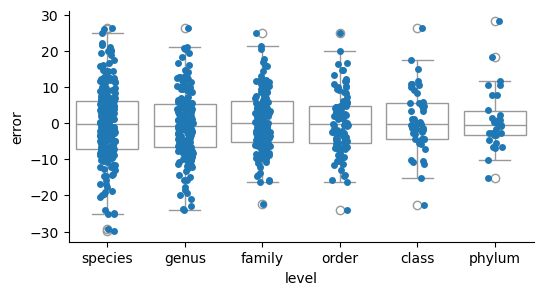

In [54]:
fig, ax = plt.subplots(figsize=(6, 3))


sns.boxplot(data=tax_cv_plotdf,
              x='level',
              y=tax_cv_plotdf['error'].apply(lambda x: x.mean()) * scaler.scale_,
              order=levels[1:][::-1],
              color='white', zorder=0)

sns.stripplot(data=tax_cv_plotdf,
              x='level',
              y=tax_cv_plotdf['error'].apply(lambda x: x.mean()) * scaler.scale_,
              order=levels[1:][::-1], zorder=1)

# group_df = tax_cv_plotdf.groupby('level').apply(lambda x: (x['error'].mean() * scaler.scale_)[0]).reset_index() 
# sns.stripplot(data=group_df,
#                x='level', s=10,
#                 y=0, color='r', zorder=2)

sns.despine()

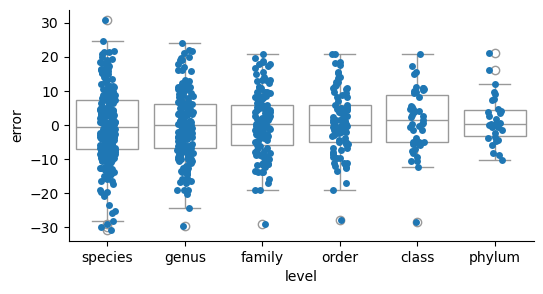

In [173]:
fig, ax = plt.subplots(figsize=(6, 3))
tax_cv_plotdf = pd.concat(errors, axis=1).T

sns.boxplot(data=tax_cv_plotdf,
              x='level',
              y=tax_cv_plotdf['error'].apply(lambda x: x.mean()) * scaler.scale_,
              order=levels[1:][::-1],
              color='white', zorder=0)

sns.stripplot(data=tax_cv_plotdf,
              x='level',
              y=tax_cv_plotdf['error'].apply(lambda x: x.mean()) * scaler.scale_,
              order=levels[1:][::-1], zorder=1)

# group_df = tax_cv_plotdf.groupby('level').apply(lambda x: (x['error'].mean() * scaler.scale_)[0]).reset_index() 
# sns.stripplot(data=group_df,
#                x='level', s=10,
#                 y=0, color='r', zorder=2)

sns.despine()

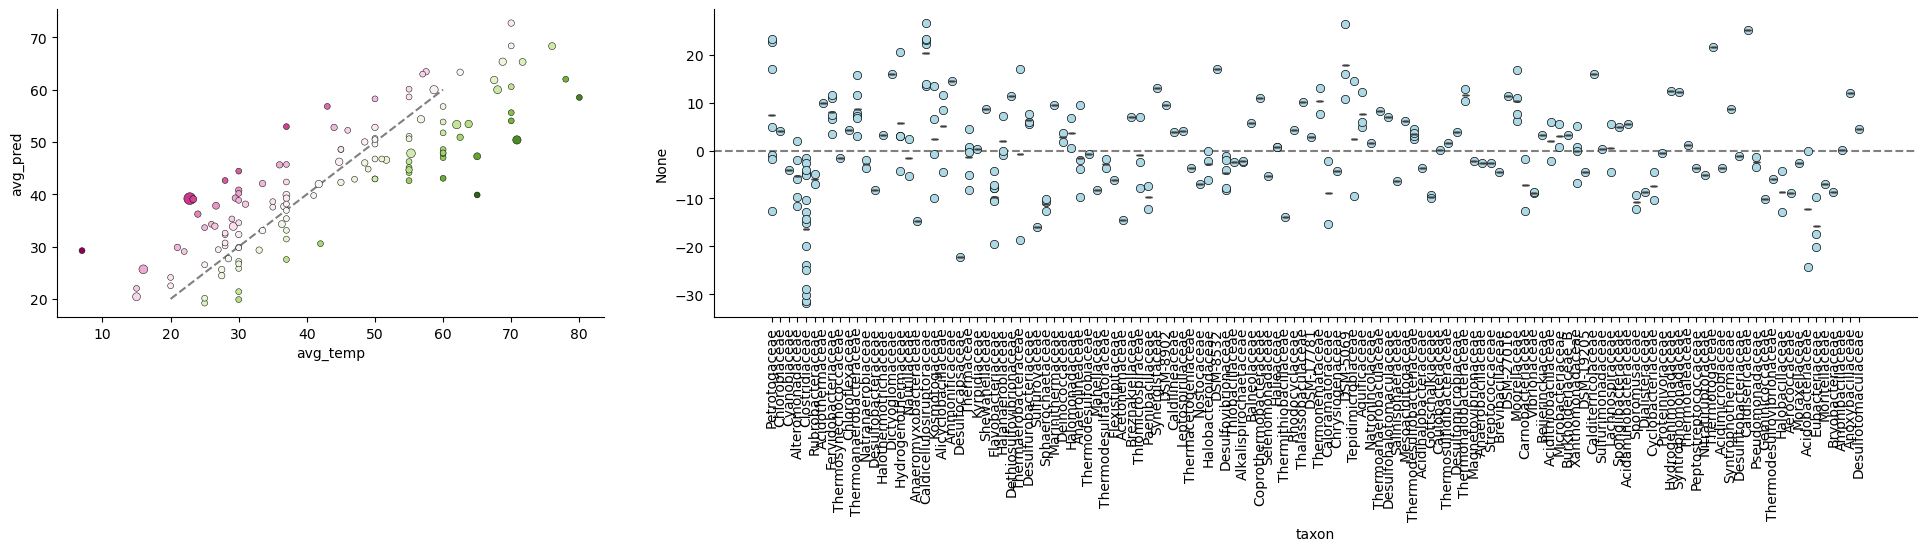

In [55]:
fig = plt.figure(figsize=(24, 4))
gs = fig.add_gridspec(1, 3)
ax = fig.add_subplot(gs[0])
species_cv = tax_cv_plotdf[tax_cv_plotdf.level.eq('family')].copy(deep=True)
species_cv['avg_temp'] = species_cv['avg_temp'].apply(lambda x: unscale_ogts(x, scaler)[0])
species_cv['avg_pred'] = species_cv['avg_pred'].apply(lambda x: unscale_ogts(x, scaler)[0])
vmax = (species_cv['avg_temp'] - species_cv['avg_pred']).max()
vmin = (species_cv['avg_temp'] - species_cv['avg_pred']).min()
sns.scatterplot(data=species_cv,
                x='avg_temp', y='avg_pred',
                edgecolor='k',
                hue=species_cv['avg_temp'] - species_cv['avg_pred'],
                hue_norm=mpl.colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax),
               palette='PiYG',
               size=species_cv.apply(lambda x: len(x['error']), axis=1), legend=False)
sns.despine()
plt.plot((20, 60), (20, 60), '--', c='gray',  zorder=0)

ax = fig.add_subplot(gs[1:])
order = species_cv['taxon'].unique()
sns.boxplot(data=species_cv, order=order,
            x='taxon', y=species_cv['avg_temp'] - species_cv['avg_pred'])
for taxon_x, o in enumerate(order):
    tax_y_vals = species_cv[species_cv.taxon.eq(o)]['error'].values[0] * scaler.scale_
    sns.scatterplot(x=[taxon_x] * len(tax_y_vals),
                   y=tax_y_vals, color='lightblue', edgecolor='k')
ax.axhline(0, color='gray', zorder=0, linestyle='--')
plt.tick_params(rotation=90, axis='x')
sns.despine()

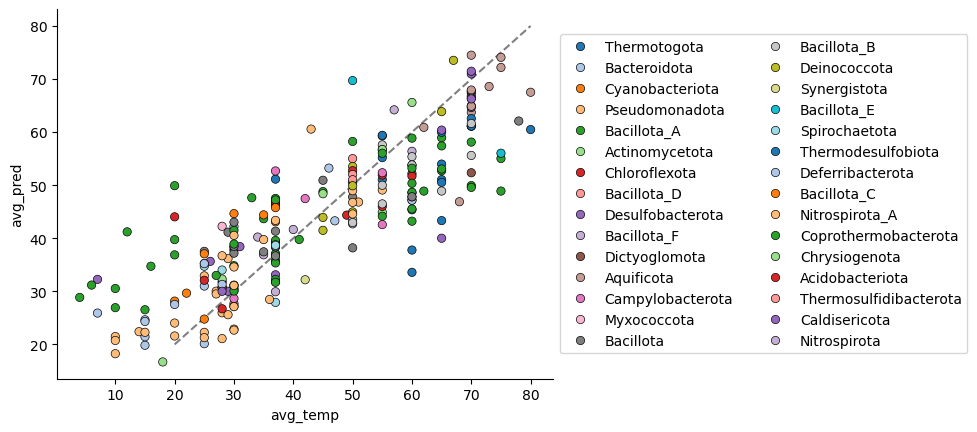

In [56]:
species_cv = tax_cv_plotdf[tax_cv_plotdf.level.eq('species')].copy(deep=True)

species2phylum = genome2tax.loc[[i[0] for i in corkrey_msa_dataset], ['phylum', 'species']].set_index('species')['phylum']
species_cv = pd.merge(species_cv, species2phylum, left_on='taxon', right_index=True)

species_cv['avg_temp'] = species_cv['avg_temp'].apply(lambda x: unscale_ogts(x, scaler)[0])
species_cv['avg_pred'] = species_cv['avg_pred'].apply(lambda x: unscale_ogts(x, scaler)[0])
vmax = (species_cv['avg_temp'] - species_cv['avg_pred']).max()
vmin = (species_cv['avg_temp'] - species_cv['avg_pred']).min()
sns.scatterplot(data=species_cv,
                x='avg_temp', y='avg_pred',
                edgecolor='k',
                hue='phylum', palette='tab20')
lgd = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncols=2)
               #  hue=species_cv['avg_temp'] - species_cv['avg_pred'],
               #  hue_norm=mpl.colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax),
               # palette='PiYG',
               # size=species_cv.apply(lambda x: len(x['error']), axis=1), legend=False)

sns.despine()
plt.plot((20, 80), (20, 80), '--', c='gray',  zorder=0)

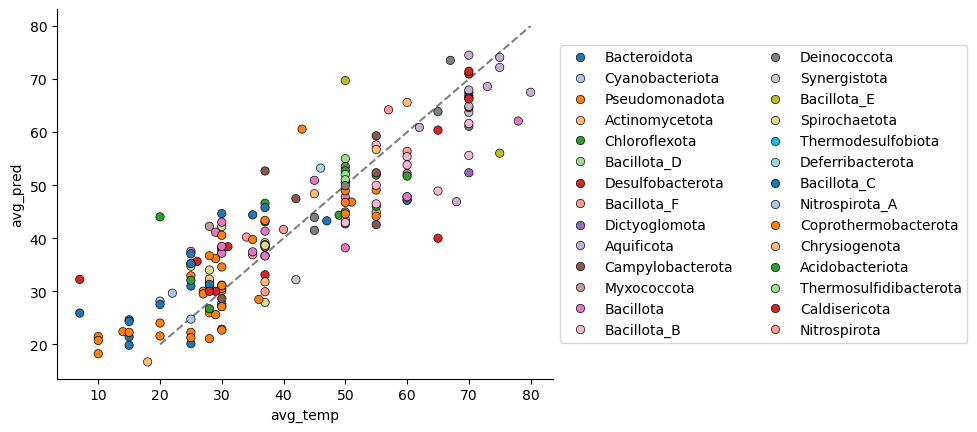

In [57]:
species_cv = tax_cv_plotdf[tax_cv_plotdf.level.eq('species')].copy(deep=True)

species2phylum = genome2tax.loc[[i[0] for i in corkrey_msa_dataset], ['phylum', 'species']].set_index('species')['phylum']
species_cv = pd.merge(species_cv, species2phylum, left_on='taxon', right_index=True)

species_cv['avg_temp'] = species_cv['avg_temp'].apply(lambda x: unscale_ogts(x, scaler)[0])
species_cv['avg_pred'] = species_cv['avg_pred'].apply(lambda x: unscale_ogts(x, scaler)[0])
vmax = (species_cv['avg_temp'] - species_cv['avg_pred']).max()
vmin = (species_cv['avg_temp'] - species_cv['avg_pred']).min()
species_cv = species_cv[~species_cv.phylum.isin(['Bacillota_A', 'Thermotogota'])]
sns.scatterplot(data=species_cv,
                x='avg_temp', y='avg_pred',
                edgecolor='k',
                hue='phylum', palette='tab20')
lgd = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncols=2)
               #  hue=species_cv['avg_temp'] - species_cv['avg_pred'],
               #  hue_norm=mpl.colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax),
               # palette='PiYG',
               # size=species_cv.apply(lambda x: len(x['error']), axis=1), legend=False)

sns.despine()
plt.plot((20, 80), (20, 80), '--', c='gray',  zorder=0)

In [58]:
from sklearn.manifold import TSNE

In [128]:




# 2. Initialize and fit t-SNE
# perplexity: related to the number of nearest neighbors (usually 5-50)
# learning_rate: usually 10-1000. 'auto' is generally best in modern sklearn.
tsne = TSNE(n_components=2, 
            perplexity=30.0, 
            n_iter=1000, 
            random_state=42, 
            init='pca', 
            learning_rate='auto')

embedding = tsne.fit_transform(tuned_even_full_embeddings[:, 0, :])




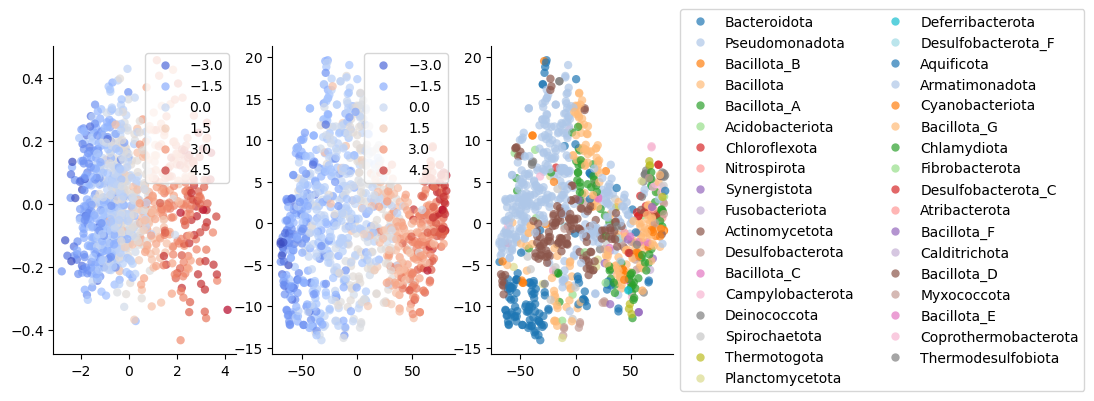

In [129]:
# 3. Visualize the results
fig = plt.figure(figsize=(8, 4))

pca = PCA(n_components=2)
pca_results = pca.fit_transform(tuned_even_full_embeddings[:, 0, :])

ax = fig.add_subplot(1,3,1)
scatter = sns.scatterplot(x=pca_results[:, 0], 
                      y=pca_results[:, 1], 
                      hue=even_temps, 
                      palette='coolwarm', 
                      edgecolor='none', 
                      alpha=0.7)
sns.despine()

ax = fig.add_subplot(1,3,2)
scatter = sns.scatterplot(x=embedding[:, 0], 
                      y=embedding[:, 1], 
                      hue=even_temps, 
                      palette='coolwarm', 
                      edgecolor='none', 
                      alpha=0.7)
sns.despine()
# plt.colorbar(scatter, ticks=range(10))
# plt.title('t-SNE projection', fontsize=16)

ax = fig.add_subplot(1,3,3)
scatter = sns.scatterplot(x=embedding[:, 0], 
                      y=embedding[:, 1], 
                      hue=genome2tax.loc[[i[0] for i in even_msa_dataset], 'phylum'], 
                      palette='tab20', 
                      edgecolor='none', 
                      alpha=0.7)
sns.despine()
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncols=2)
# ax.colorbar(scatter, ticks=range(10))
# ax.set_title('t-SNE projection', fontsize=16)
plt.show()

<Axes: >

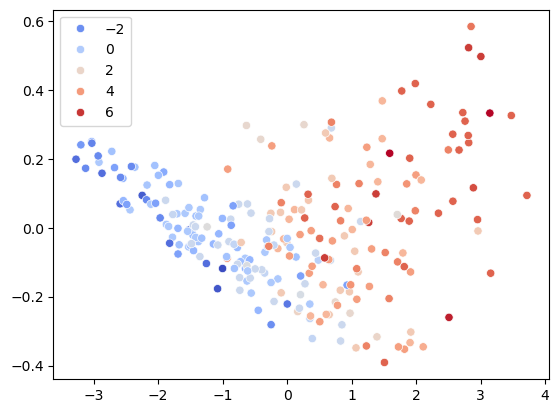

In [138]:
pca = PCA(n_components=2)
pca_comps = pca.fit_transform(tuned_c_w_e_full_embeddings[:, 0, :])
sns.scatterplot(x=pca_comps[:, 0], y=pca_comps[:, 1], hue=c_w_e_temps, palette='coolwarm')

In [141]:
# lm = ElasticNet(alpha=0)
lm = tuned_even_full_embeddings[:, 0, :]
lm.fit(tuned_even_full_embeddings[:, 0, :], even_temps)
lm_pred = lm.predict(tuned_c_w_e_full_embeddings[:, 0, :])

4.0 2.0


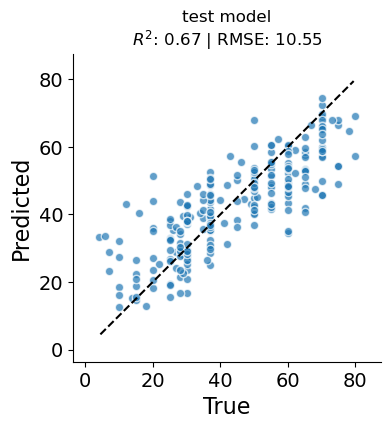

In [142]:
plot_performance(unscale_ogts(c_w_e_temps, scaler), 
                 unscale_ogts(lm_pred, scaler), 
                 'test model', show=True)

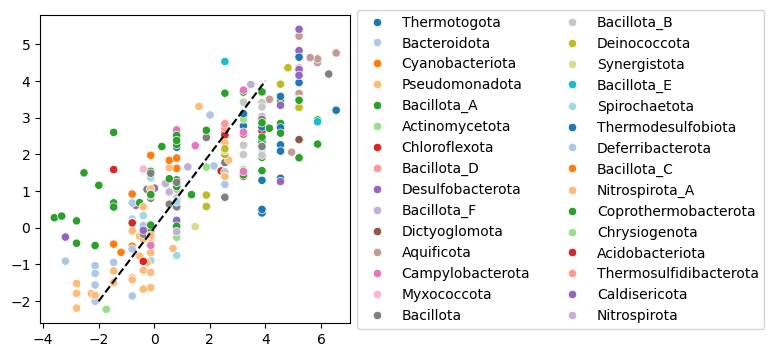

In [121]:
fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(x=c_w_e_temps, 
                y=lm_pred, 
                hue=genome2tax.loc[[i[0] for i in corkrey_msa_dataset], 'phylum'],
               palette='tab20')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncols=2)
plt.plot((-2, 4), (-2, 4), 'k--')

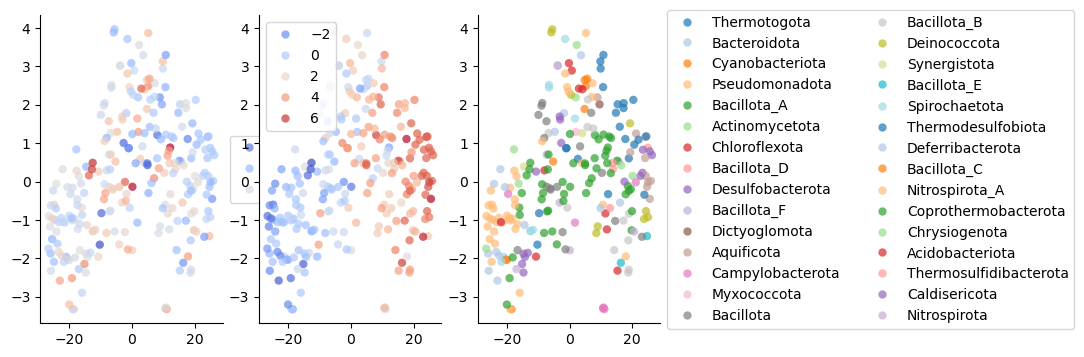

In [108]:
# 2. Initialize and fit t-SNE
# perplexity: related to the number of nearest neighbors (usually 5-50)
# learning_rate: usually 10-1000. 'auto' is generally best in modern sklearn.
tsne = TSNE(n_components=2, 
            perplexity=30.0, 
            n_iter=1000, 
            random_state=42, 
            init='pca', 
            learning_rate='auto')

embedding = tsne.fit_transform(tuned_c_w_e_full_embeddings[:, 0, :])

# 3. Visualize the results
fig = plt.figure(figsize=(8, 4))

ax = fig.add_subplot(1,3,1)
scatter = sns.scatterplot(x=embedding[:, 0], 
                      y=embedding[:, 1], 
                      hue=lm_pred - c_w_e_temps, 
                      palette='coolwarm', 
                      edgecolor='none', 
                      alpha=0.7)
sns.despine()
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncols=2)


ax = fig.add_subplot(1,3,2)
scatter = sns.scatterplot(x=embedding[:, 0], 
                      y=embedding[:, 1], 
                      hue=c_w_e_temps, 
                      palette='coolwarm', 
                      edgecolor='none', 
                      alpha=0.7)
sns.despine()
# plt.colorbar(scatter, ticks=range(10))
# plt.title('t-SNE projection', fontsize=16)

ax = fig.add_subplot(1,3,3)
scatter = sns.scatterplot(x=embedding[:, 0], 
                      y=embedding[:, 1], 
                      hue=genome2tax.loc[[i[0] for i in corkrey_msa_dataset], 'phylum'], 
                      palette='tab20', 
                      edgecolor='none', 
                      alpha=0.7)
sns.despine()
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncols=2)
# ax.colorbar(scatter, ticks=range(10))
# ax.set_title('t-SNE projection', fontsize=16)
plt.show()

In [90]:
tuned_c_w_e_full_embeddings.shape

(243, 183, 768)

In [112]:
spearmans = []
models = []
for comp in range(tuned_c_w_e_full_embeddings.shape[2]):
    spearmans.append(spearmanr(tuned_c_w_e_full_embeddings[:, 0, comp], c_w_e_temps)[0])
    models.append(sm.GLS(even_temps, tuned_even_full_embeddings[:, 0, comp]).fit())

<Axes: ylabel='Count'>

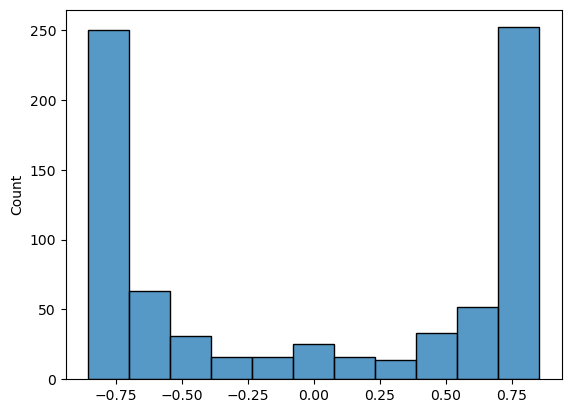

In [115]:
sns.histplot(spearmans)

<Axes: >

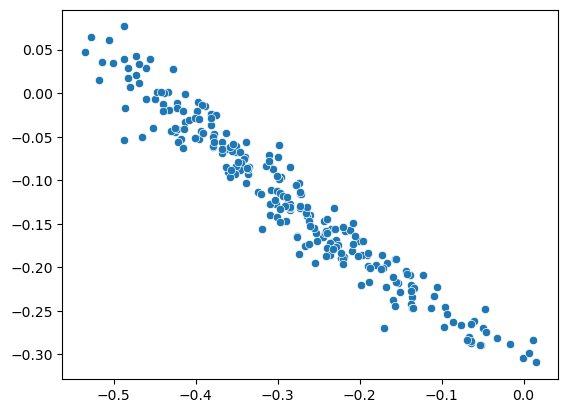

In [119]:
sns.scatterplot(x=tuned_c_w_e_full_embeddings[:, 0, 233], y=tuned_c_w_e_full_embeddings[:, 0, 662])

In [117]:
np.argmax(spearmans), np.argmin(spearmans)

(233, 662)

In [113]:
preds = []
for comp in range(tuned_c_w_e_full_embeddings.shape[2]):
    preds.append(models[comp].predict(tuned_c_w_e_full_embeddings[:, 0, comp]))

<Axes: >

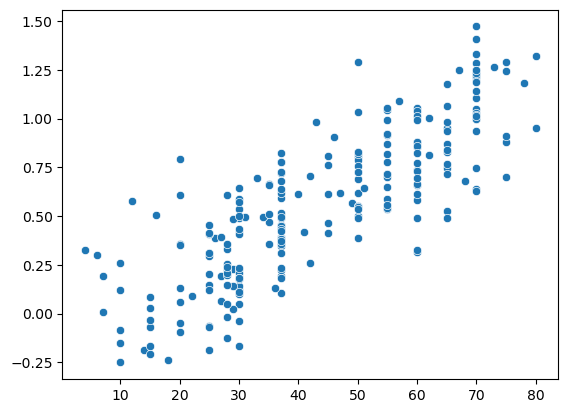

In [114]:
sns.scatterplot(y=np.array(preds).mean(axis=0),
                x=unscale_ogts(c_w_e_temps, scaler))
                

<Axes: >

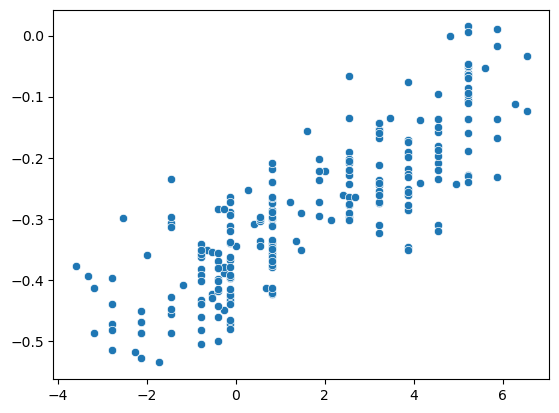

In [101]:
sns.scatterplot(x=c_w_e_temps, y=tuned_c_w_e_full_embeddings[:, 0, 233])

In [286]:
with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_full_tuned_even.pickle', 'rb') as handle:
    arth_full_tuned_even = pickle.load(handle)

with open('./../data/validation_datasets/Arthrobacter/embeddings/Arthrobacter_temps.pickle', 'rb') as handle:
    arth_temps = pickle.load(handle)

In [288]:
lm = ElasticNet(alpha=0.1)
lm.fit(tuned_c_w_e_full_embeddings[:, 0, :], c_w_e_temps)
lm_pred = lm.predict(arth_full_tuned_even[:, 0, :])

<Axes: >

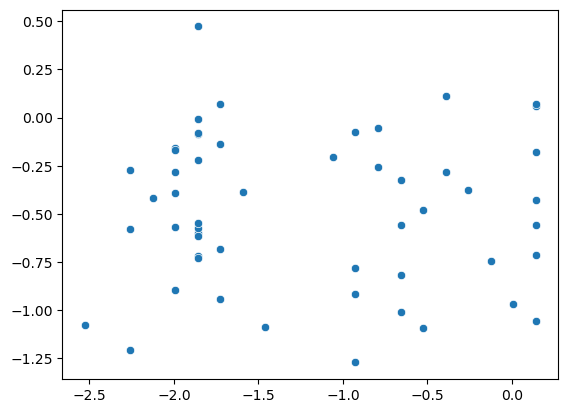

# Models on tuned transformer

In [146]:
trans_emb = tuned_pca.transform(tuned_c_w_e_full_embeddings[:, 0, :])

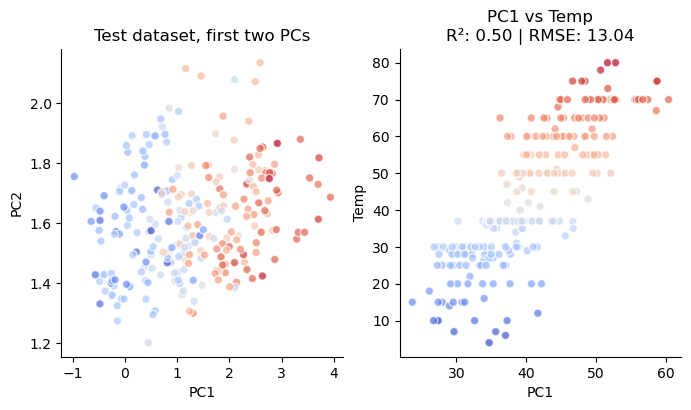

In [147]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,2,1)
ax.scatter(trans_emb[:, 0], trans_emb[:, 1], 
                 c=corkrey_temps, cmap='coolwarm', alpha=0.7, edgecolors='w')
sns.despine()
ax.set_title('Test dataset, first two PCs')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax = fig.add_subplot(1,2,2)
# plt.scatter(y=trans_emb[:, 0], x=temps, c=temps, cmap='coolwarm')
preds = unscale_ogts(np.array(trans_emb[:, 0]), scaler)
y_test = unscale_ogts(np.array(corkrey_temps), scaler)
ax.scatter(y=y_test, x=preds, c=y_test, 
           cmap='coolwarm', alpha=0.7, edgecolors='w', zorder=1)
# ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', zorder=0)

r2 = r2_score(y_test, preds)
mse = np.sqrt(mean_squared_error(y_test, preds))

ax.set_title(f"PC1 vs Temp\nR²: {r2:.2f} | RMSE: {mse:.2f}")
ax.set_ylabel('Temp')
ax.set_xlabel('PC1')
sns.despine()

#### Question
Does the tuned PCA work on untuned embeddings?

In [75]:
trans_emb = tuned_pca.transform(corkrey_embeddings)

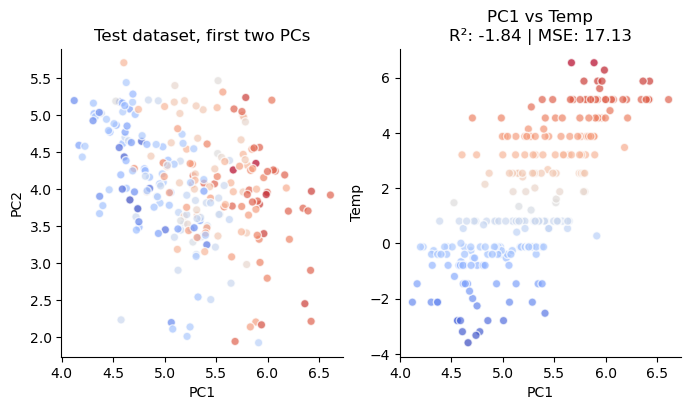

In [76]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,2,1)
ax.scatter(trans_emb[:, 0], trans_emb[:, 1], 
                 c=temps, cmap='coolwarm', alpha=0.7, edgecolors='w')
sns.despine()
ax.set_title('Test dataset, first two PCs')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax = fig.add_subplot(1,2,2)
# plt.scatter(y=trans_emb[:, 0], x=temps, c=temps, cmap='coolwarm')
preds = np.array(trans_emb[:, 0])
y_test = np.array(temps)
ax.scatter(y=y_test, x=preds, c=y_test, 
           cmap='coolwarm', alpha=0.7, edgecolors='w', zorder=1)
# ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', zorder=0)

r2 = r2_score(y_test, preds)
mse = mean_squared_error(y_test, preds)

ax.set_title(f"PC1 vs Temp\nR²: {r2:.2f} | MSE: {mse:.2f}")
ax.set_ylabel('Temp')
ax.set_xlabel('PC1')
sns.despine()

#### Notes
What da hell

In [148]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import LocallyLinearEmbedding, trustworthiness
from sklearn.decomposition import PCA

# 1. Generate the 3D Swiss Roll
X, _ = make_swiss_roll(n_samples=1000, noise=0.01, random_state=42)

# 2. Apply PCA (Linear)
X_pca = PCA(n_components=2).fit_transform(X)

# 3. Apply LLE (Non-linear)
lle = LocallyLinearEmbedding(n_neighbors=12, n_components=2, method='standard')
X_lle = lle.fit_transform(X)

# 4. Calculate Trustworthiness (Standard)
# "Are there fake friends in the 2D map?"
trust_pca = trustworthiness(X, X_pca, n_neighbors=12)
trust_lle = trustworthiness(X, X_lle, n_neighbors=12)

# 5. Calculate Continuity (The "Swap" Trick)
# "Did we break any real friendships?"
cont_pca = trustworthiness(X_pca, X, n_neighbors=12)
cont_lle = trustworthiness(X_lle, X, n_neighbors=12)

print(f"PCA - Trustworthiness: {trust_pca:.3f}, Continuity: {cont_pca:.3f}")
print(f"LLE - Trustworthiness: {trust_lle:.3f}, Continuity: {cont_lle:.3f}")

PCA - Trustworthiness: 0.971, Continuity: 0.990
LLE - Trustworthiness: 0.995, Continuity: 0.995


## SVR and RF

In [346]:
X_train, X_test, y_train, y_test = train_test_split(tuned_corkrey_embeddings, corkrey_temps, test_size=0.2, random_state=111)


models = [RandomForestRegressor] * 2 + [SVR] * 2
labels = ['corkrey_rf_tuned_means', 'corkrey_rf_tuned_pca', 'corkrey_svr_tuned_means', 'corkrey_svr_tuned_pca']
titles = ['RF, tuned means, training: Corkrey', 'RF, tuned PCA, training: Corkrey', 'SVR, tuned means, training: Corkrey', 'SVR, tuned PCA, training: Corkrey']
training_inputs = [X_train, tuned_pca.transform(X_train)] * 2
testing_inputs = [X_test, tuned_pca.transform(X_test)] * 2
training_ys = [y_train, y_train] * 2
testing_ys = [y_test, y_test] * 2
spaces = [rf_space] * 2 + [svr_space] * 2

Running corkrey_svr_tuned_pca ...
100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:25<00:00,  1.25s/trial, best loss: 1.9284929585379207]
10.0 5.0


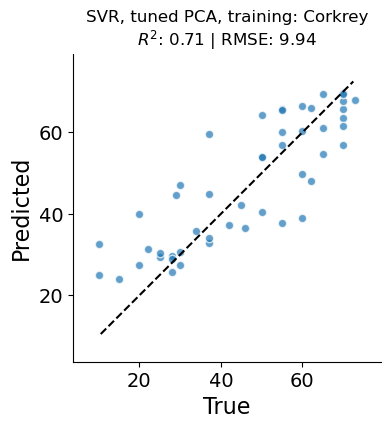

(194, 5)


In [352]:
i = 0
for model, label, title, x_train, x_test, y_train, y_test, space in zip(models,
                                                              labels,
                                                              titles,
                                                              training_inputs, 
                                                              testing_inputs,
                                                              training_ys,
                                                              testing_ys,
                                                              spaces):
    if i == 3:
        print(f'Running {label} ...')
        # Run the optimizer
        optimizer_results = optimize_sklearn_cv(
            model_class=model,
            X_train=x_train, 
            y_train=y_train, 
            X_test=x_test, 
            y_test=y_test, 
            space=space,
            is_regression=True,
            max_evals=20
        )
    
    
        plot_performance(unscale_ogts(optimizer_results['true_values'], scaler), 
                         unscale_ogts(optimizer_results['predictions'], scaler),
                         title,
                         f'./../data/figures/models/{label}.svg')
        
        optimizer_results['metadata'] = {'type':str(model),
                                          'input_shape':x_train.shape,
                                          'title':title,
                                          'label':label
        }
        print(x_train.shape)
        
        with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
            pickle.dump(optimizer_results, handle)
    i += 1

## Linear model

In [ ]:
title = 'LM, tuned means, training: Corkrey'
label = 'corkrey_lm_tuned_means'

lm = sm.WLS(y_train, X_train).fit()

lm_pred = lm.predict(X_test)

lm_results = {'best_model':lm,
           'best_params':lm.params,
           'predictions':lm_pred,
           'true_values': y_test,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':str(lm),
                       'input_shape':X_train.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')


# with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
#     pickle.dump(lm_results, handle)

0.0 0.0


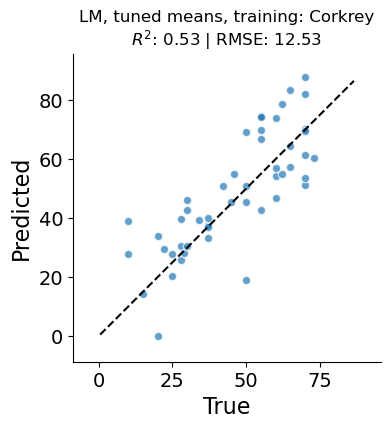

In [319]:
title = 'LM, tuned means, training: Corkrey'
label = 'corkrey_lm_tuned_means'

lm = sm.WLS(y_train, X_train).fit()

lm_pred = lm.predict(X_test)

lm_results = {'best_model':lm,
           'best_params':lm.params,
           'predictions':lm_pred,
           'true_values': y_test,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':str(lm),
                       'input_shape':X_train.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')


with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(lm_results, handle)

10.0 5.0


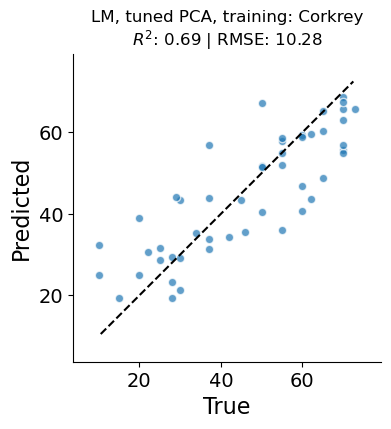

In [320]:
title = 'LM, tuned PCA, training: Corkrey'
label = 'corkrey_lm_tuned_pca'


lm = sm.WLS(y_train, tuned_pca.transform(X_train)).fit()

lm_pred = lm.predict(tuned_pca.transform(X_test))

lm_results = {'best_model':lm,
           'best_params':lm.params,
           'predictions':lm_pred,
           'true_values': y_test,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':str(lm),
                       'input_shape':tuned_pca.transform(X_train).shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')


with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(lm_results, handle)

## Per-site tuned linear model

In [126]:
tuned_corkrey_full_embeddings, _ = get_embeddings(tuned_esm, 
                                    conv, 
                                    corkrey_msa_dataset, 
                                    corkrey_msa_dataset, 
                                    n_context=8, layer=12, return_mean=False)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 243/243 [03:22<00:00,  1.20it/s]


In [140]:
tuned_even_full_embeddings, _ = get_embeddings(tuned_esm, 
                                    conv, 
                                    even_msa_dataset, 
                                    even_msa_dataset, 
                                    n_context=8, layer=12, return_mean=False)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 997/997 [11:21<00:00,  1.46it/s]


In [141]:
tuned_corkrey_full_embeddings.shape

(243, 183, 768)

In [203]:
X_train, X_test, y_train, y_test = train_test_split(tuned_corkrey_full_embeddings, corkrey_temps, test_size=0.2, random_state=111)

10.0 5.0


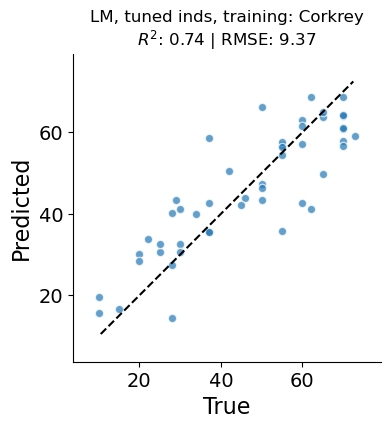

Dumping...
Done


In [204]:
title = 'LM, tuned inds, training: Corkrey'
label = 'corkrey_lm_ind_tuned_means'

# fit models
col_lms = {}
for col in range(tuned_corkrey_full_embeddings.shape[1]):
    display(col)
    clear_output(wait=True)
    col_embedding = X_train[:, col, :]
    col_lm = sm.WLS(y_train, col_embedding).fit()
    col_lms[col] = col_lm

# predict
col_preds = []
for col in range(len(corkrey_col_lms)):
    display(col)
    clear_output(wait=True)
    col_preds.append(col_lms[col].predict(X_test[:, col, :]))

mean_preds = np.array(col_preds).mean(axis=0)

lm_results = {'best_model':col_lms,
           'best_params':dict((k, i.params) for k,i in col_lms.items()),
           'predictions':mean_preds,
          'full_predictions':np.array(col_preds),
           'true_values': y_test,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':f'array of {str(lm)}',
                       'input_shape':X_train.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')

print('Dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(lm_results, handle)
print('Done')

10.0 5.0


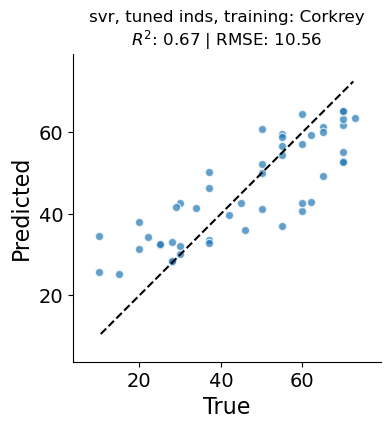

In [208]:
title = 'svr, tuned inds, training: Corkrey'
label = 'corkrey_svr_ind_tuned_pca'

# fit models
col_lms = {}
for col in range(tuned_corkrey_full_embeddings.shape[1]):
    display(col)
    clear_output(wait=True)
    col_embedding = tuned_pca.transform(X_train[:, col, :])
    # col_lm = sm.WLS(y_train, col_embedding).fit()
    col_lm = SVR().fit(col_embedding, y_train)
    col_lms[col] = col_lm

# predict
col_preds = []
for col in range(len(corkrey_col_lms)):
    display(col)
    clear_output(wait=True)
    col_preds.append(col_lms[col].predict(tuned_pca.transform(X_test[:, col, :])))

mean_preds = np.array(col_preds).mean(axis=0)

lm_results = {'best_model':col_lms,
           'best_params':'', #dict((k, i.params) for k,i in col_lms.items()),
           'predictions':mean_preds,
          'full_predictions':np.array(col_preds),
           'true_values': y_test,
           'statsmodels_version':statsmodels.__version__,
           'metadata':{'type':f'array of {str(lm)}',
                       'input_shape':np.array([tuned_pca.transform(X_train[i, :, :]) for i in range(X_train.shape[0])]).shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(lm_results['true_values'], scaler), 
                 unscale_ogts(lm_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')


with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(lm_results, handle)

In [315]:
lm_results['metadata']['input_shape']

(194, 183, 5)

## Neural networks on tuned transformer

Epoch [10/100], Loss: 0.6940
Epoch [20/100], Loss: 0.6662
Epoch [30/100], Loss: 0.6193
Epoch [40/100], Loss: 0.6247
Epoch [50/100], Loss: 0.6041
Epoch [60/100], Loss: 0.6284
Epoch [70/100], Loss: 0.5736
Epoch [80/100], Loss: 0.6095
Epoch [90/100], Loss: 0.5800
Epoch [100/100], Loss: 0.5504
4.0 2.0


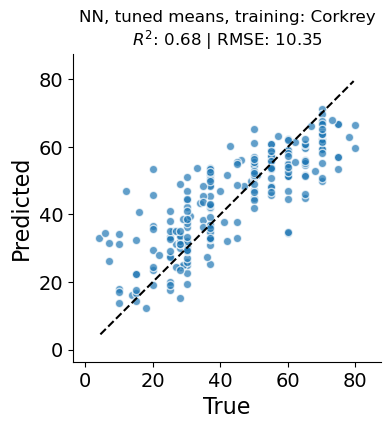

In [89]:
# X_train, X_test, y_train, y_test = train_test_split(tuned_corkrey_embeddings, corkrey_temps, test_size=0.2, random_state=111)

title = 'NN, tuned means, training: Corkrey'
label = 'corkrey_nn_tuned_means'

# train NN on corkrey
nn_model = train_model(tuned_even_full_embeddings[:, 0, :], even_temps, MLPRegressor, 
                       epochs=100, batch_size=32, lr=1e-3)

nn_preds = nn_model.predict(tuned_c_w_e_full_embeddings[:, 0, :]).reshape(1, -1)[0]

torch.save(nn_model.state_dict(), f'./../data/predictive_models/{label}_state_dict.pt')

nn_results = {'best_model':nn_model,
           'best_params':nn_model.state_dict(),
           'predictions':nn_preds,
           'true_values': c_w_e_temps,
           'torch_version':torch.__version__,
           'metadata':{'type':f'Neural network: {str(nn_model)}',
                       'input_shape':X_train.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(nn_results['true_values'], scaler), 
                 unscale_ogts(nn_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')


# print('dumping...')
# with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
#     pickle.dump(nn_results, handle)
# print('Done.')

Epoch [10/100], Loss: 5.1718
Epoch [20/100], Loss: 2.7683
Epoch [30/100], Loss: 2.0260
Epoch [40/100], Loss: 2.4057
Epoch [50/100], Loss: 1.4279
Epoch [60/100], Loss: 1.3789
Epoch [70/100], Loss: 1.5026
Epoch [80/100], Loss: 1.4398
Epoch [90/100], Loss: 1.1521
Epoch [100/100], Loss: 1.0448
10.0 5.0


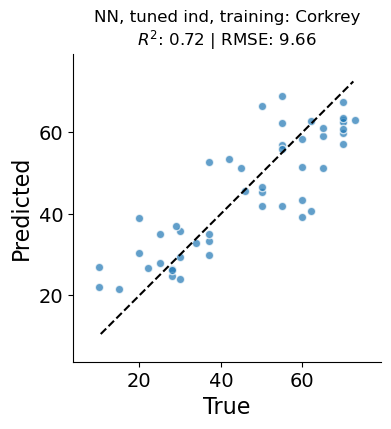

dumping...
Done.


In [151]:
X_train, X_test, y_train, y_test = train_test_split(tuned_corkrey_full_embeddings, corkrey_temps, test_size=0.2, random_state=111)

title = 'NN, tuned ind, training: Corkrey'
label = 'corkrey_nn_ind_tuned_means'

# train NN on corkrey
nn_model = train_model(X_train, y_train, AttentionRegressor, 
                       epochs=100, batch_size=32, lr=1e-4)

nn_preds = nn_model.predict(X_test).reshape(1, -1)[0]

torch.save(nn_model.state_dict(), f'./../data/predictive_models/{label}_state_dict.pt')

nn_results = {'best_model':nn_model,
           'best_params':nn_model.state_dict(),
           'predictions':nn_preds,
           'true_values': y_test,
           'torch_version':torch.__version__,
           'metadata':{'type':f'Neural network: {str(nn_model)}',
                       'input_shape':X_train.shape,
                       'title':title,
                       'label':label
                      }
          }

plot_performance(unscale_ogts(nn_results['true_values'], scaler), 
                 unscale_ogts(nn_results['predictions'], scaler),
                 title,
                 f'./../data/figures/models/{label}.svg')


print('dumping...')
with open(f'./../data/predictive_models/{label}.pickle', 'wb') as handle:
    pickle.dump(nn_results, handle)
print('Done.')

## Big Neural network

In [480]:
# turn off tuning for all components of the newly tuned model
for name, param in tuned_esm.named_parameters():
        param.requires_grad = False

In [483]:
model, conv = train_ogt(hiqual_msa, OGTModel, tuned_esm, conv, epochs=5)

Epoch 4: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 243/243 [02:16<00:00,  1.78it/s, loss=9.4325]


Evaluating test data...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 989/989 [09:03<00:00,  1.82it/s]


(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Regression Performance (Randomized Test Context)'}, xlabel='Actual Normalized OGT', ylabel='Predicted Normalized OGT'>)

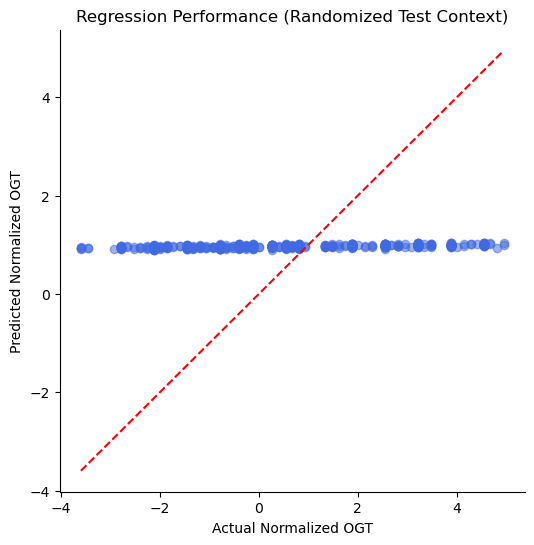

In [484]:
y_true, y_pred = assess_model(model, conv, val_msa, hiqual_msa)
plot_performance(y_true, y_pred)

# Testing on other datasets

In [86]:
def reload_model(path):
    with open(path, 'rb') as handle:
        model_data = pickle.load(handle)
    return model_data

In [87]:
def assess_model(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mse = np.sqrt(mean_squared_error(y_true, y_pred))
    _spearmanr = spearmanr(y_true, y_pred)[0]
    return '$R^{2}$=' + f'{r2:.2f}|MSE={mse:.2f}|SpR={_spearmanr:.2f}'

def calculate_hash(file_path, algorithm='sha256'):
    """Calculates the hash of a file efficiently."""
    # Create a hash object (SHA-256 is recommended)
    hash_obj = hashlib.new(algorithm)
    # Open the file in binary mode for reading ('rb')
    with open(file_path, 'rb') as f:
        # Read the file in chunks (e.g., 64 KB) to handle large files
        while True:
            data = f.read(65536)
            if not data:
                break
            hash_obj.update(data)
    return hash_obj.hexdigest()

def check_hash(f1, old_hash):
    return calculate_hash(f1) == old_hash

In [82]:
# check metadata is formatted properly
allcols = []
for s2t in glob.glob('./../data/validation_datasets/*/md/*_env_temps.tsv'):
    allcols += list(pd.read_csv(s2t, sep='\t').columns)

set(allcols)

{'Unnamed: 0', 'env temp', 'protein', 'sample_or_genome'}

In [97]:
# initial hashing of adk files: not necessary to rerun.
hashes = pd.Series()
for test_data_afa  in [
                     './../data/high_qual_alignments/alignments_to_backbone/Arthrobacter_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Mycobacteria_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Shah2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Youngblut2020_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Antarctic_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Colman2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Australia_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Conteville2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Mara2023_adk_to_backbone.afa',
                       './../data/high_qual_alignments/alignments_to_backbone/Salazar2019_adk_to_backbone.afa',
                    './../data/high_qual_alignments/alignments_to_backbone/RoyoLlonch2021_adk_to_backbone.afa',]:
    hashes.loc[os.path.abspath(test_data_afa)] = calculate_hash(test_data_afa)

hashes.to_csv('./../data/validation_datasets/adk_afa_hashes.tsv', sep='\t')

## Generate embeddings for each dataset

In [147]:
# 


# load hashes: should be rerun
# hashes = pd.read_csv('./../data/validation_datasets/adk_afa_hashes.tsv', sep='\t', index_col=0)['0']

full_msa_keys = set([i[0] for i in full_msa_dataset])
for test_data_afa  in [
                    './../data/high_qual_alignments/alignments_to_backbone/Salazar2019_adk_to_backbone.afa',
                    './../data/high_qual_alignments/alignments_to_backbone/RoyoLlonch2021_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Arthrobacter_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Mycobacteria_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Shah2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Youngblut2020_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Antarctic_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Colman2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Australia_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Conteville2024_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Mara2023_adk_to_backbone.afa',
                    ]:

    # part 1: load data
    # --------------------------------------------
    gate = False

    test_dataset = construct_msa_dataset(test_data_afa, ogt_parse_fn=lambda _str: _str)
    print('Before removing training:',len(test_dataset))
    test_dataset = [i for i in test_dataset if not i[0] in full_msa_keys]
    print('After removing training:',len(test_dataset))

    dataset_name = test_data_afa.split('/')[-1].split('_adk_')[0]
    seq2envtemp = pd.read_csv(f'./../data/validation_datasets/{dataset_name}/md/{dataset_name}_env_temps.tsv', sep='\t').drop('Unnamed: 0', axis=1).set_index('protein')
        
    # add env temps to dataset
    test_dataset = [(i[0], i[1], seq2envtemp.loc[i[0], 'env temp']) for i in test_dataset if i[0] in seq2envtemp.index]

    
    # eliminate nans
    test_dataset = [i for i in test_dataset if not np.isnan(i[2])]
    # scale ogts
    test_dataset, _ = scale_ogts(test_dataset, scaler)

    emb_base = f'./../data/validation_datasets/{dataset_name}/embeddings/'
    os.makedirs(emb_base, exist_ok=True)
    
    with open(f'{emb_base}{dataset_name}_msa_dataset.pickle', 'wb') as handle:
        pickle.dump(test_dataset, handle)

    # only rerun if hasn't been run or adk file has changed
    # if os.path.exists(f'{emb_base}{dataset_name}_full_tuned.pickle'):
    #     gate = True
    #     print('No embeddings found. Running...')
    gate=True
    if gate:
        for context_dataset, context_label in zip([corkrey_msa_dataset, even_msa_dataset],
                                                  ['corkrey', 'even']):
            
            # use the same random context for every embedding
            random_context = get_random_context(msa_dataset=context_dataset,
                                                n_contexts=len(test_dataset),
                                                context_size=8, 
                                                self=False)
            
            for label, _mean, _esm_model in zip(['full'],
                                               [False],
                                                [esm_msa_model]):
                
                test_emb, test_temps, _ = get_embeddings(_esm_model, 
                                                      conv, 
                                                      test_dataset, 
                                                      context_dataset,
                                                      random_context,
                                                      return_mean=_mean)
                
                with open(f'{emb_base}{dataset_name}_{label}_{context_label}.pickle', 'wb') as handle:
                    pickle.dump(test_emb, handle)
                with open(f'{emb_base}{dataset_name}_temps.pickle', 'wb') as handle:
                    pickle.dump(test_temps, handle)
                    
            with open(f'{emb_base}{dataset_name}_{context_label}_context_values.pickle', 'wb') as handle:
                    pickle.dump(random_context, handle)



Before removing training: 14561
After removing training: 6029


100%|██████████████████████████████████████████████████████████████| 5486/5486 [1:01:05<00:00,  1.50it/s]


Before removing training: 16568
After removing training: 8036


100%|██████████████████████████████████████████████████████████████| 7636/7636 [1:29:02<00:00,  1.43it/s]


Before removing training: 9723
After removing training: 1191


...

100%|████████████████████████████████████████████████████████████████| 2211/2211 [25:59<00:00,  1.42it/s]


Before removing training: 9518
After removing training: 986


100%|██████████████████████████████████████████████████████████████████| 970/970 [11:06<00:00,  1.45it/s]


Before removing training: 16568
After removing training: 8036


100%|██████████████████████████████████████████████████████████████| 7636/7636 [1:25:08<00:00,  1.49it/s]


## Problems:
This approaches embeds all of the datasets using corkrey, and maybe some should be embedded using the even dataset (if a model which also uses the even dataset is applied)

## Run models on each test dataset

In [90]:
full_msa_keys = set([i[0] for i in full_msa_dataset])
for test_data_afa in [
                     './../data/high_qual_alignments/alignments_to_backbone/Arthrobacter_adk_to_backbone.afa',
                     './../data/high_qual_alignments/alignments_to_backbone/Mycobacteria_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Shah2024_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Youngblut2020_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Antarctic_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Colman2024_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Australia_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Conteville2024_adk_to_backbone.afa',
                     # './../data/high_qual_alignments/alignments_to_backbone/Mara2023_adk_to_backbone.afa',
                       # './../data/high_qual_alignments/alignments_to_backbone/Salazar2019_adk_to_backbone.afa',
                    # './../data/high_qual_alignments/alignments_to_backbone/RoyoLlonch2021_adk_to_backbone.afa'
                    ]:
    # part 1: load data
    # --------------------------------------------
    pred_df_list = []
    print(test_data_afa)
    test_dataset = construct_msa_dataset(test_data_afa, ogt_parse_fn=lambda _str: _str)
    print('Before removing training:',len(test_dataset))
    test_dataset = [i for i in test_dataset if not i[0] in full_msa_keys]
    print('After removing training:',len(test_dataset))

    dataset_name = test_data_afa.split('/')[-1].split('_adk_')[0]
    seq2envtemp = pd.read_csv(f'./../data/validation_datasets/{dataset_name}/md/{dataset_name}_env_temps.tsv', sep='\t').drop('Unnamed: 0', axis=1).set_index('protein')
        
    # add env temps to dataset
    test_dataset = [(i[0], i[1], seq2envtemp.loc[i[0], 'env temp']) for i in test_dataset if i[0] in seq2envtemp.index]
    # eliminate nans
    test_dataset = [i for i in test_dataset if not np.isnan(i[2])]
    # scale ogts
    test_dataset, _ = scale_ogts(test_dataset, scaler)

    print('loading embeddings')
    emb_base = f'./../data/validation_datasets/{dataset_name}/embeddings/'
    # load embeddings
    loaded_embeddings = {'corkrey':{}, 'even':{}}
    for context_label in ['corkrey', 'even']:
        for label in ['mean', 'mean_tuned', 'full', 'full_tuned']:
            with open(f'{emb_base}{dataset_name}_{label}_{context_label}.pickle', 'rb') as handle:
                loaded_emb = pickle.load(handle)
            loaded_embeddings[context_label][label] = loaded_emb

    with open(f'{emb_base}{dataset_name}_temps.pickle', 'rb') as handle:
            test_temps = pickle.load(handle)
        

    # part 2: run models
    # --------------------------------------------
    model_pickles = [i for i in sorted(glob.glob('./../data/predictive_models/*.pickle')) if not 'tuned' in i]
    
    logname = os.path.join('./../data/validation_datasets/prediction_results/', f'{dataset_name}.log')
    
    # clear out any existing handlers
    for handler in logging.root.handlers[:]:
        logging.root.removeHandler(handler)
        
    logging.basicConfig(filename=logname,
                        filemode='w',
                        format='%(asctime)s,%(msecs)03d %(name)s %(levelname)s %(message)s',
                        datefmt='%Y-%m-%d %H:%M:%S',
                        level=logging.DEBUG)
    
    logging.info(f'Found {len(model_pickles)} models')
    predictions = ''
    
    for model_pickle in model_pickles:
        del predictions
        # load model
        display(model_pickle)
        logging.info(model_pickle)
        loaded_model = reload_model(model_pickle)
        logging.info('Loaded model: ')
        model_label = loaded_model['metadata']['label']
        logging.info(model_label + ', training data shape:' + f"{loaded_model['metadata']['input_shape']}")
        
        # make sure the model is labeled correctly
        assert model_label == model_pickle.split('/')[-1].replace('.pickle', ''), 'model may be mislabeled'
        
        # define string to describe what data were used
        used_str = ''

        # need to use embeddings embedded in same context as model predictions
        if 'corkrey' in model_label:
            test_embeddings = loaded_embeddings['corkrey']
        else:
            test_embeddings = loaded_embeddings['even']
        
        # if it's tuned
        if '_tuned_' in model_label:
            
            used_str += 'tuned '
            if '_ind' in model_label:
                model_input_data = copy.deepcopy(test_embeddings['full_tuned'])
                used_str += ' full '
                if '_pca' in model_label:
                    # linear models
                    model_input_data = np.array([tuned_pca.transform(model_input_data[i, :, :]) for i in range(model_input_data.shape[0])]) 
                    used_str += ' pca '
                
            else:
                
                model_input_data = copy.deepcopy(test_embeddings['mean_tuned'])
                if '_pca' in model_label:
                    model_input_data = tuned_pca.transform(model_input_data)
                    used_str += ' pca '
                else:    
                    used_str += ' mean '
            # pass
        else:
            # pca_t = copy.deepcopy(pca)
            used_str += 'NOT tuned '
            if '_ind' in model_label:
                model_input_data = copy.deepcopy(test_embeddings['full'])
                used_str += ' full '
            else:
                model_input_data = copy.deepcopy(test_embeddings['mean'])
                used_str += ' mean '
    
        # check that input shape matches
        logging.info(f'Input shape: {model_input_data.shape}')
        assert loaded_model['metadata']['input_shape'][1:] == model_input_data.shape[1:], 'input data is wrong shape'
    
        
        if not '_ind' in model_label:
            predictions = loaded_model['best_model'].predict(model_input_data)
        else:
            if '_lm_' in model_label:
                predictions = np.array([loaded_model['best_model'][i].predict(model_input_data[:, i, :]) for i in loaded_model['best_model'].keys()]).mean(0)
            else:
                predictions = loaded_model['best_model'].predict(model_input_data)
        
        predictions = unscale_ogts(predictions, scaler)
        actuals = unscale_ogts(test_temps, scaler)
        logging.info(used_str)
        assessment = assess_model(actuals, predictions)
        logging.info(f'Result: {assessment}')
    
        # plot_performance(y_pred=predictions,
        #              y_true=actuals,
        #              title='Testing on: Arthobacter\n' + loaded_model['metadata']['label'] + f' {assessment}')
    
        prediction_df = pd.DataFrame(zip(predictions, 
                                     actuals,
                                     [i[0] for i in test_dataset]))
    
        prediction_df = prediction_df.rename(columns={0:'prediction', 
                                      1:'actual',
                                     2:'protein'}).assign(model_label=model_label, dataset=dataset_name)
        
        prediction_df = pd.merge(prediction_df,
                 seq2envtemp, left_on='protein', right_index=True)
        logging.info('Done!')
        pred_df_list.append(prediction_df)
        clear_output(wait=True)

    full_test_preds = pd.concat(pred_df_list)
    
    full_test_scores = full_test_preds.groupby(['dataset', 'model_label']).apply(lambda x: pd.Series(data=[spearmanr(x['prediction'], x['actual'])[0],
                                                                           np.sqrt(mean_squared_error(x['prediction'], x['actual']))
                                                                          ],
                                                                          
                                                                    index=['SpearmanR', 'MSE']))
    
    full_test_preds.to_csv(f'./../data/validation_datasets/prediction_results/{dataset_name}_full_test_preds.tsv', sep='\t')
    full_test_scores.to_csv(f'./../data/validation_datasets/prediction_results/{dataset_name}_full_test_scores.tsv', sep='\t')

'./../data/predictive_models/even_svr_means.pickle'

In [314]:
full_test_preds

,prediction,actual,protein,model_label,dataset,sample_or_genome,env temp
0,28.674938,16.0,contig_4_579|8HZ65L_1_ASP410-2_hmmsearch.tbl|X...,corkrey_lm_ind,Arthrobacter,8HZ65L_1_ASP410-2,16
1,16.150657,27.0,contig_2_682|8HZ65L_3_24664_hmmsearch.tbl|XXXt...,corkrey_lm_ind,Arthrobacter,8HZ65L_3_24664,27
2,29.697427,15.0,contig_1_351|barcode01_consensus_hmmsearch.tbl...,corkrey_lm_ind,Arthrobacter,barcode01,15
3,31.974832,17.0,contig_1_2021|barcode02_consensus_hmmsearch.tb...,corkrey_lm_ind,Arthrobacter,barcode02,17
4,19.627307,18.0,contig_1_919|barcode03_consensus_hmmsearch.tbl...,corkrey_lm_ind,Arthrobacter,barcode03,18
...,...,...,...,...,...,...,...
48,27.225556,32.0,contig_1_3063|barcode53_consensus_hmmsearch.tb...,even_svr_means,Arthrobacter,barcode53,32
49,23.649873,24.0,BAABED010000001.1_658|D14008_GCA_039539965.1_A...,even_svr_means,Arthrobacter,barcode14,24
50,29.866075,25.0,RBIR01000002.1_325|D25586_GCA_003634095.1_ASM3...,even_svr_means,Arthrobacter,barcode50,25
51,24.451830,12.0,contig_2_2269|DS72QC_1_ASP_418-1_hmmsearch.tbl...,even_svr_means,Arthrobacter,barcode19,12


In [ ]:
##

## Plotting

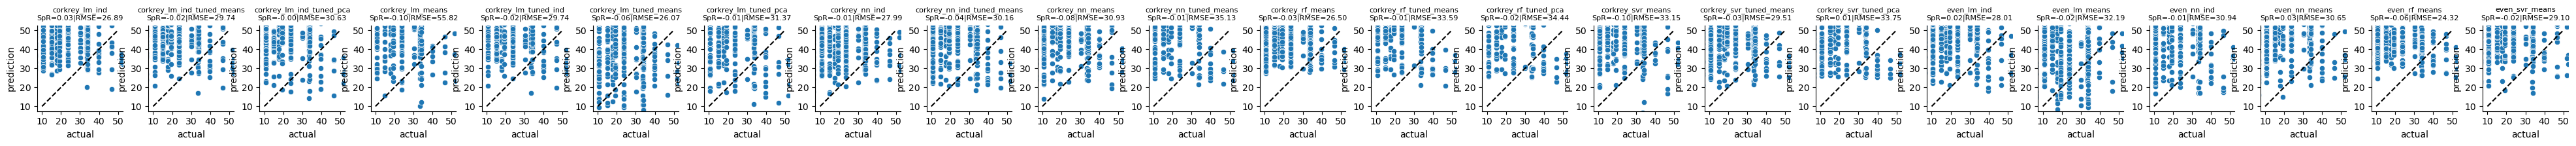

In [488]:
n_models = len(full_test_scores.index.get_level_values(1).unique())
n_datasets = len(full_test_scores.index.get_level_values(0).unique())
fig = plt.figure(figsize=(50, 5))
ind = 1
colors = sns.color_palette('tab10', n_colors=2)
for i, dataset in enumerate(full_test_scores.index.get_level_values(0).unique()):
    for j, model in enumerate(full_test_scores.index.get_level_values(1).unique()):
        display(i, j)
        clear_output(wait=True)
        ax = fig.add_subplot(n_datasets, n_models, ind)

        sns.scatterplot(data=full_test_preds[full_test_preds['dataset'].eq(dataset) & full_test_preds['model_label'].eq(model)],
                       x='actual', y='prediction', color=colors[i])
        plt.plot((10, 50), (10, 50), 'k--')
        score1 = full_test_scores.loc[idx[dataset, model], 'SpearmanR']
        score2 = full_test_scores.loc[idx[dataset, model], 'MSE']
        ax.set_title(f'{model}\nSpR={score1:.2f}|RMSE={score2:.2f}', fontsize=8)
        sns.despine()
        ax.set_ylim(7.5, 52.5)
        ax.set_xlim(7.5, 52.5)
        ax.set_xticks(range(10, 60, 10))
        ax.set_yticks(range(10, 60, 10))
        ax.set_aspect('equal')
        ind += 1

fig.subplots_adjust(wspace=0.3, hspace=0.3)
# plt.savefig('./../data/figures/models/all_models_isolates.svg', bbox_inches='tight')

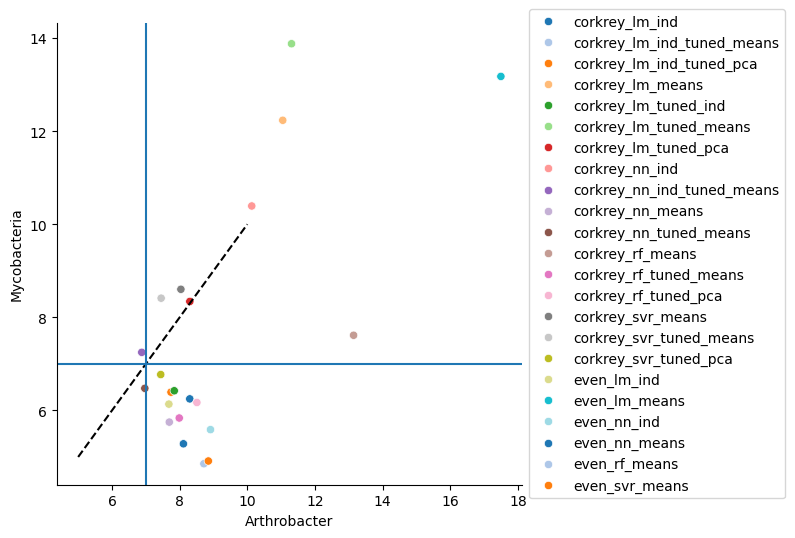

In [461]:
# sns.scatterplot()
fig,ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data=full_test_scores['MSE'].unstack().T, 
                x='Arthrobacter', y='Mycobacteria', hue='model_label', palette='tab20')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.plot((5, 10), (5, 10), 'k--')
sns.despine()
ax.axvline(7)
ax.axhline(7)

In [422]:
full_test_scores.loc[idx[_dataset, :], 'MSE'].sort_values()

dataset       model_label               
Mycobacteria  even_rf_means                  4.855175
              even_svr_means                 4.913509
              even_nn_means                  5.283342
              even_nn_ind                    5.587790
              corkrey_nn_means               5.749340
              corkrey_rf_tuned_means         5.837541
              even_lm_ind                    6.135982
              corkrey_rf_tuned_pca           6.171042
              corkrey_lm_ind                 6.248264
              corkrey_lm_ind_tuned_pca       6.392758
              corkrey_lm_tuned_ind           6.422596
              corkrey_lm_ind_tuned_means     6.422596
              corkrey_nn_tuned_means         6.474996
              corkrey_svr_tuned_pca          6.771168
              corkrey_nn_ind_tuned_means     7.248174
              corkrey_rf_means               7.615087
              corkrey_lm_tuned_pca           8.341478
              corkrey_svr_tuned_means    

In [407]:
full_test_preds.head()

,prediction,actual,protein,model_label,dataset,sample_or_genome,env temp
0,27.149084,16.0,contig_4_579|8HZ65L_1_ASP410-2_hmmsearch.tbl|X...,corkrey_lm_ind,Arthrobacter,8HZ65L_1_ASP410-2,16.0
1,19.574426,27.0,contig_2_682|8HZ65L_3_24664_hmmsearch.tbl|XXXt...,corkrey_lm_ind,Arthrobacter,8HZ65L_3_24664,27.0
2,22.493697,15.0,contig_1_351|barcode01_consensus_hmmsearch.tbl...,corkrey_lm_ind,Arthrobacter,barcode01,15.0
3,29.068946,17.0,contig_1_2021|barcode02_consensus_hmmsearch.tb...,corkrey_lm_ind,Arthrobacter,barcode02,17.0
4,18.771668,18.0,contig_1_919|barcode03_consensus_hmmsearch.tbl...,corkrey_lm_ind,Arthrobacter,barcode03,18.0


In [188]:
full_msa_keys = set([i[0] for i in full_msa_dataset])
for test_data_afa  in sorted(glob.glob('./../data/high_qual_alignments/alignments_to_backbone/*_adk_to_backbone.afa'))[:1]:
    print(test_data_afa)
    test_dataset = construct_msa_dataset(test_data_afa, ogt_parse_fn=lambda _str: _str)
    print(len(test_dataset))
    test_dataset = [i for i in test_dataset if not i[0] in full_msa_keys]
    print(len(test_dataset))
    # # add env temps to dataset
    # test_dataset = [(i[0], i[1], seq2envtemp.loc[i[0], 'env temp']) for i in test_dataset]
    # # scale ogts
    # test_dataset, _ = scale_ogts(test_data, scaler)

    

    # test_full_emb, test_temps = get_embeddings(original_esm_snapshot, conv, test_dataset, corkrey_msa_dataset, 
    #                                            n_context=8, return_mean=False)
    # tuned_test_full_emb, test_temps = get_embeddings(tuned_esm, conv, test_dataset, corkrey_msa_dataset, 
    #                                                  n_context=8, return_mean=False)
    
    
    

./../data/high_qual_alignments/alignments_to_backbone/Antarctic_adk_to_backbone.afa
9815
984


In [465]:
test_data = construct_msa_dataset('./../data/high_qual_alignments/alignments_to_backbone/RoyoLlonch2021_adk_to_backbone.afa')

# scale ogts
test_dataset, _ = scale_ogts(test_data, scaler)

full_msa_keys = set([i[0] for i in full_msa_dataset])
test_dataset = random.sample([i for i in test_dataset if not i[0] in full_msa_keys], 150)
print(len(test_dataset))

test_emb_tuned, test_temps = get_embeddings(tuned_esm, conv, test_dataset, corkrey_msa_dataset, n_context=8, return_mean=False)

test_emb_tuned = np.array(test_emb_tuned)

150


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [01:32<00:00,  1.63it/s]


-2.0 -1.0


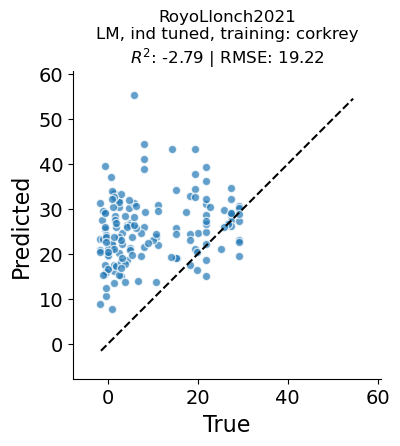

In [466]:
# predict
test_col_preds = []
for col in range(len(corkrey_col_lms)):
    display(col)
    
    test_col_preds.append(corkrey_col_lms[col].predict(test_emb_tuned[:, col, :]))
    clear_output(wait=True)

test_mean_preds = np.array(test_col_preds).mean(axis=0)

plot_performance(unscale_ogts(test_temps,  scaler),
                unscale_ogts(test_mean_preds, scaler),
                 'RoyoLlonch2021\nLM, ind tuned, training: corkrey')

-2.0 -1.0


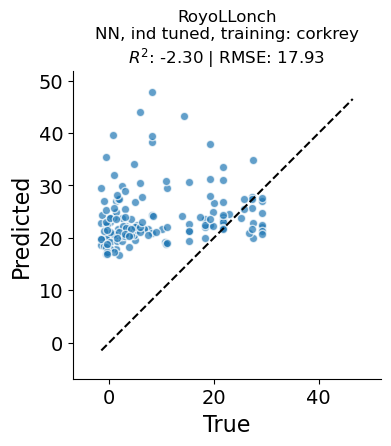

In [467]:
test_nn_preds = nn_model.predict(test_emb_tuned).reshape(1, -1)[0]
plot_performance(unscale_ogts(test_temps,  scaler),
                unscale_ogts(test_nn_preds, scaler),
                 'RoyoLLonch\nNN, ind tuned, training: corkrey')

# Embedding the remainder of the MSA for plotting

In [162]:
corkrey_keys = set([i[0] for i in corkrey_msa_dataset])
even_keys = set([i[0] for i in even_msa_dataset])
extra_msa_dataset = [i for i in full_msa_dataset if not any(i[0] in s for s in [corkrey_keys, even_keys])]


7591


In [165]:
%store scaler

Stored 'scaler' (StandardScaler)


In [177]:
tuned_extra_full_embeddings, extra_temps = get_embeddings(tuned_esm, 
                                    conv, 
                                    extra_msa_dataset, 
                                    extra_msa_dataset, 
                                    n_context=8, layer=12, return_mean=False)

100%|███████████████████████████████████████████████████████████████████████████████████| 7591/7591 [1:16:35<00:00,  1.65it/s]


In [178]:
extra_full_embeddings, extra_temps = get_embeddings(esm_msa_model, 
                                    conv, 
                                    extra_msa_dataset, 
                                    extra_msa_dataset, 
                                    n_context=8, layer=12, return_mean=False)

100%|███████████████████████████████████████████████████████████████████████████████████| 7591/7591 [1:18:58<00:00,  1.60it/s]


## run extra embeddings through models

In [179]:
loaded_model = reload_model('./../data/predictive_models/even_lm_ind.pickle')

In [180]:
predictions = np.array([loaded_model['best_model'][i].predict(extra_full_embeddings[:, i, :]) for i in loaded_model['best_model'].keys()]).mean(0)

<Axes: >

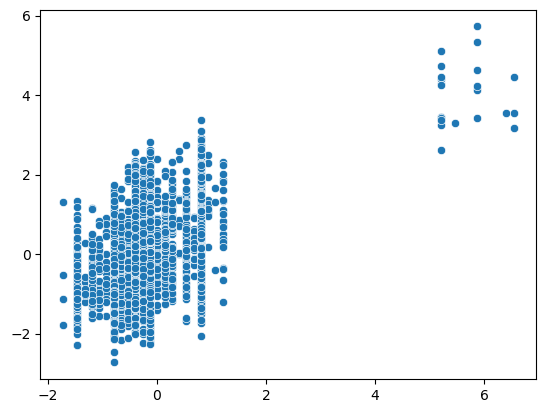

In [182]:
sns.scatterplot(y=predictions, x=extra_temps)

## save all embeddings

In [ ]:
with open('./../data/esm_msa/corkrey_embeddings.pickle', 'wb') as handle:
    pickle.dump(corkrey_embeddings, handle)

In [185]:
with open('./../data/esm_msa/corkrey_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(corkrey_full_embeddings, handle)

In [186]:
with open('./../data/esm_msa/even_embeddings.pickle', 'wb') as handle:
    pickle.dump(even_embeddings, handle)

In [187]:
with open('./../data/esm_msa/even_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(even_full_embeddings, handle)

In [201]:
with open('./../data/esm_msa/even_temps.pickle', 'wb') as handle:
    pickle.dump(even_temps, handle)

### Tuned versions

In [192]:
with open('./../data/esm_msa/tuned_corkrey_embeddings.pickle', 'wb') as handle:
    pickle.dump(tuned_corkrey_embeddings, handle)

In [193]:
with open('./../data/esm_msa/tuned_corkrey_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(tuned_corkrey_full_embeddings, handle)

In [190]:
with open('./../data/esm_msa/tuned_even_embeddings.pickle', 'wb') as handle:
    pickle.dump(tuned_even_embeddings, handle)

In [191]:
with open('./../data/esm_msa/tuned_even_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(tuned_even_full_embeddings, handle)

### Extra

In [188]:
with open('./../data/esm_msa/extra_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(extra_full_embeddings, handle)

In [189]:
with open('./../data/esm_msa/tuned_extra_full_embeddings.pickle', 'wb') as handle:
    pickle.dump(tuned_extra_full_embeddings, handle)

In [195]:
with open('./../data/esm_msa/extra_temps.pickle', 'wb') as handle:
    pickle.dump(extra_temps, handle)

# Tuning a second ESM MSA

In [710]:
original_esm_snapshot_2 = copy.deepcopy(original_esm_snapshot)

In [711]:
rl_data = construct_msa_dataset('./../data/high_qual_alignments/alignments_to_backbone/RoyoLlonch2021_adk_to_backbone.afa', get_scaled)

rl_data = random.sample([i for i in rl_data if not i[0] in seqs_with_ogt.keys()], 2000)
rl_data_1 = rl_data[:(len(rl_data) // 2)]
rl_data_2 = rl_data[(len(rl_data) // 2):]
print(len(rl_data))


2000


In [712]:
tuned_esm_rl = tune_esm_separation(original_esm_snapshot_2, conv, rl_data_1, epochs=10)

Tuning ESM Epoch 9: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [11:30<00:00,  1.45it/s, loss=0.358]


Extracting embeddings for visualization: Tuned ESM Space...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [04:26<00:00,  3.75it/s]


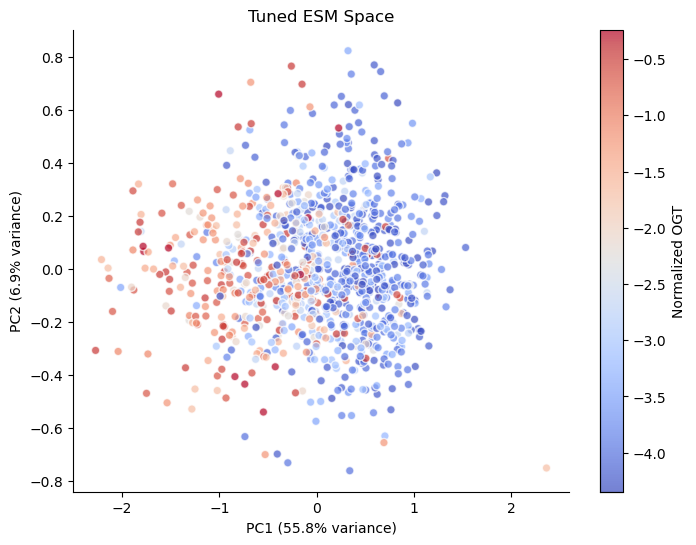

In [713]:
# generating its own PCA
pca, pca_result = visualize_esm_separation(tuned_esm_rl, conv, rl_data_2, n_comps=5, title="Tuned ESM Space")

In [714]:
emb, temps = get_embeddings(tuned_esm_rl, conv, data_list=rl_data_2, training_context=rl_data_1, n_context=4)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [05:47<00:00,  2.88it/s]


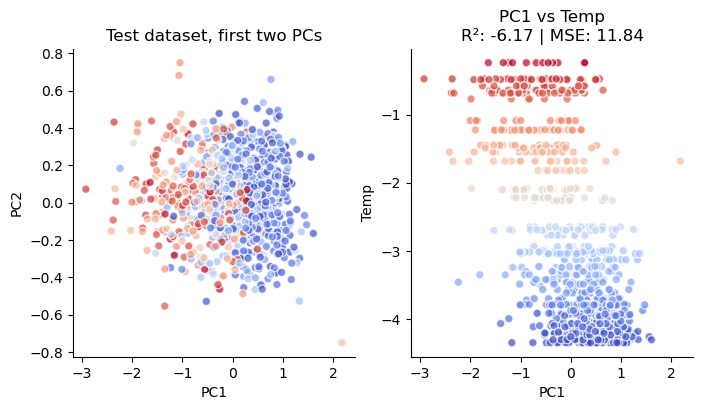

In [715]:
# PCA transformation with original tuned transformer's PCA instance
trans_emb = pca.transform(emb)

fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,2,1)
ax.scatter(trans_emb[:, 0], trans_emb[:, 1], 
                 c=temps, cmap='coolwarm', alpha=0.7, edgecolors='w')
sns.despine()
ax.set_title('Test dataset, first two PCs')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax = fig.add_subplot(1,2,2)
# plt.scatter(y=trans_emb[:, 0], x=temps, c=temps, cmap='coolwarm')
preds = np.array(trans_emb[:, 0])
y_test = np.array(temps)
ax.scatter(y=y_test, x=preds, c=y_test, 
           cmap='coolwarm', alpha=0.7, edgecolors='w', zorder=1)
# ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', zorder=0)

r2 = r2_score(y_test, preds)
mse = mean_squared_error(y_test, preds)

ax.set_title(f"PC1 vs Temp\nR²: {r2:.2f} | MSE: {mse:.2f}")
ax.set_ylabel('Temp')
ax.set_xlabel('PC1')
sns.despine()

Generating embeddings for Train and Test sets...
Training Random Forest and SVR...


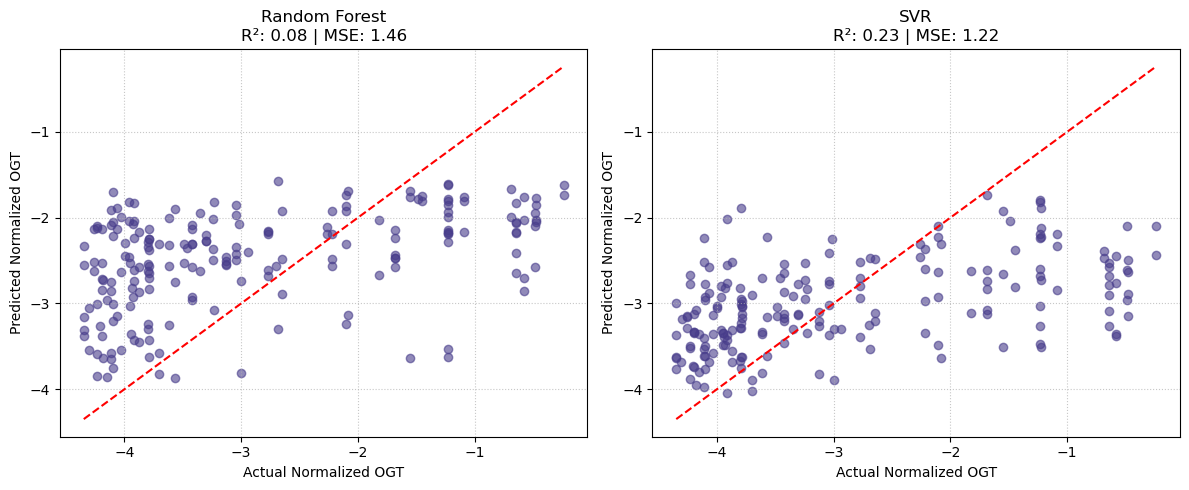

CPU times: user 25min 46s, sys: 5min 9s, total: 30min 55s
Wall time: 3min 20s


In [716]:
%time run_classical_baseline(rl_data_2, tuned_esm_rl, alphabet, conv)

Training Random Forest and SVR...


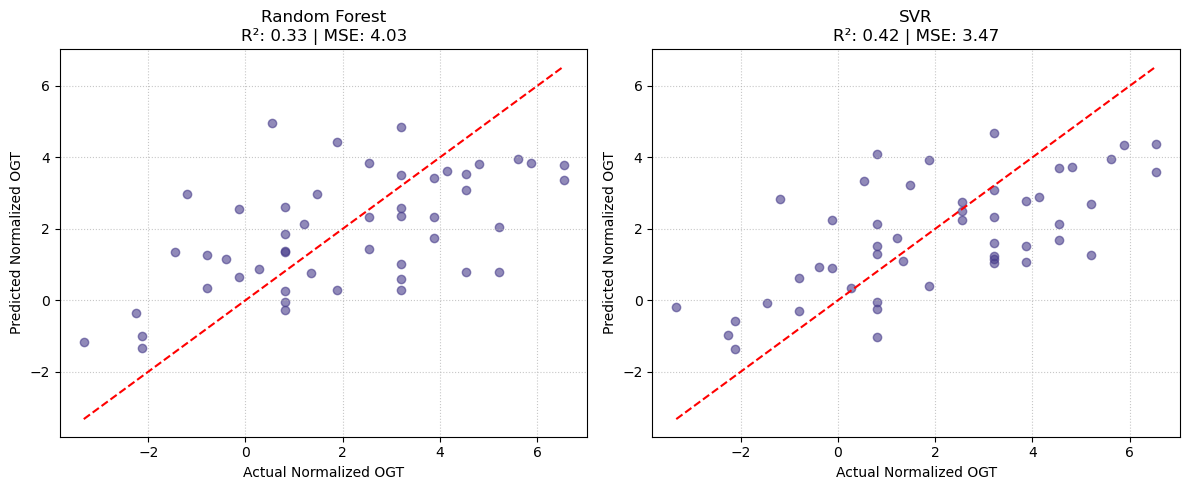

In [779]:
X_train, X_test, y_train, y_test = train_test_split(trans_emb, np.array(temps), test_size=0.2)


# 3. Train Regressors
rf = RandomForestRegressor(n_estimators=100, random_state=42)
svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)

print("Training Random Forest and SVR...")
rf.fit(X_train, y_train)
svr.fit(X_train, y_train)

# 4. Predict
rf_preds = rf.predict(X_test)
svr_preds = svr.predict(X_test)

# 5. Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds, title in zip([ax1, ax2], [rf_preds, svr_preds], ["Random Forest", "SVR"]):
    ax.scatter(y_test, preds, alpha=0.6, color='darkslateblue')
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    
    r2 = r2_score(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    
    ax.set_title(f"{title}\nR²: {r2:.2f} | MSE: {mse:.2f}")
    ax.set_xlabel("Actual Normalized OGT")
    ax.set_ylabel("Predicted Normalized OGT")
    ax.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

## Compare tuned models

In [674]:
def compare_tuning_consensus(m_orig, m_tuned_a, m_tuned_b):
    results = []
    
    for i in range(len(m_orig.layers)):
        with torch.no_grad():
            # Define target sub-modules
            submodules = [
                ('Row-Attr', 'row_self_attention'),
                ('Col-Attr', 'column_self_attention'),
                ('FFN', 'feed_forward_layer')
            ]
            
            for label, name in submodules:
                # Get weights
                w_orig = getattr(m_orig.layers[i], name).layer
                w_a = getattr(m_tuned_a.layers[i], name).layer
                w_b = getattr(m_tuned_b.layers[i], name).layer
                
                # We target the Q-projection as a proxy for attention shift
                # For FFN, we target fc1
                if label == 'FFN':
                    delta_a = w_a.fc1.weight - w_orig.fc1.weight
                    delta_b = w_b.fc1.weight - w_orig.fc1.weight
                else:
                    delta_a = w_a.q_proj.weight - w_orig.q_proj.weight
                    delta_b = w_b.q_proj.weight - w_orig.q_proj.weight
                
                # Calculate Frobenius norms (Magnitude of change)
                norm_a = torch.norm(delta_a).item()
                norm_b = torch.norm(delta_b).item()
                
                # Calculate Cosine Similarity of the updates (Direction of change)
                # This tells us if the models are moving in the SAME direction in parameter space
                sim = torch.nn.functional.cosine_similarity(delta_a.view(1, -1), delta_b.view(1, -1)).item()
                
                results.append({
                    "Layer": i,
                    "Module": label,
                    "Shift_Dataset_A": norm_a,
                    "Shift_Dataset_B": norm_b,
                    "Direction_Consistency": sim
                })

    return pd.DataFrame(results)

# Analysis Execution
df_consensus = compare_tuning_consensus(esm_orig, esm_tuned_1, esm_tuned_2)

[('NODE_5_length_244793_cov_26.942117|SRR32180441_215|SRR32180441_hmmsearch.tbl|env_temp=31.6|bitscore=187.1',
  'MRIVLLGPPGAGKGTQAQKLADKLGVPHVSTGDLFRYNISNNTELGVEAKKYLDAGDLVPASLTNALVDDRLDDEDAKAGFILDGFPRSVEQAEALDKRNLSLDAVLEFRVPEEELVSRLQGR----GRADDTEDVIRNRFKVYRDETAPLLDYYSE--TLTTVDAVGELDEVFTRALKALG',
  0.08765286010155819),
 ('NODE_64_length_33264_cov_17.408426|SRR32180442_20|SRR32180442_hmmsearch.tbl|env_temp=38.2|bitscore=178.7',
  'MRVVLLGPPGAGKGTQAQKLAEKLGIPQISTGELFRKNIQDGTKLGVEAKRYLDAGDLVPSDLTNQLVDDRLDQPDTAAGFILDGYPRSVEQAKALHERDTDIDAVLEFRVSQDELLQRLKGR----GRADDTDEVILNRMKVYRDETAPLLEFYDT--EVKTVDAIGTLDEVFARALQALG',
  0.967936113577896),
 ('NODE_8_length_214623_cov_14.510741|SRR32180443_23|SRR32180443_hmmsearch.tbl|env_temp=37.4|bitscore=185.9',
  'MRIVLLGAPGAGKGTQAQKLSEKLGIPQISTGDLFRQNISEGTELGLEAKRYLDAGDLVPASLTNALVEDRINQPDAANGFILDGFPRSVEQAEALDKLNVRLDAVLEFQVSEEELLARLKAR----GRADDTEDVIRNRMAVYRSETEPLLDYYRD--QLKTVDAVGTLDEVFERALTALG',
  0.8612351131565211),
 ('NODE_9_length_205973_cov_23.46423

# potentially helpful code

In [ ]:
derep = pd.read_csv('./../data/validation_datasets/RoyoLlonch2021/derep_adk_cluster.tsv', sep='\t', header=None, names=['rep', 'member'])

len(derep['rep'].unique())

## Errors

<Axes: xlabel='env temp', ylabel='None'>

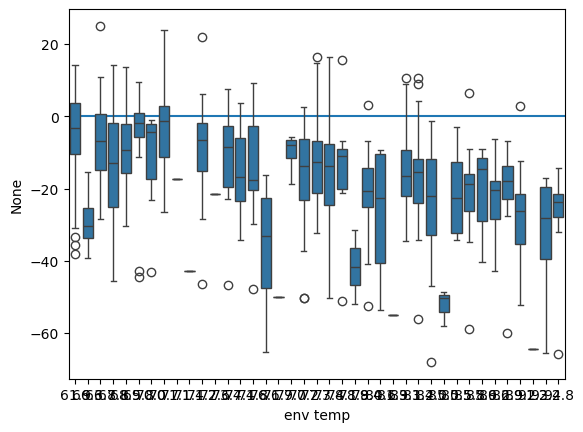

In [289]:
plt.axhline(0)
sns.boxplot(y=plotdf['predicted'] - plotdf['env temp'],
                x=plotdf['env temp'])

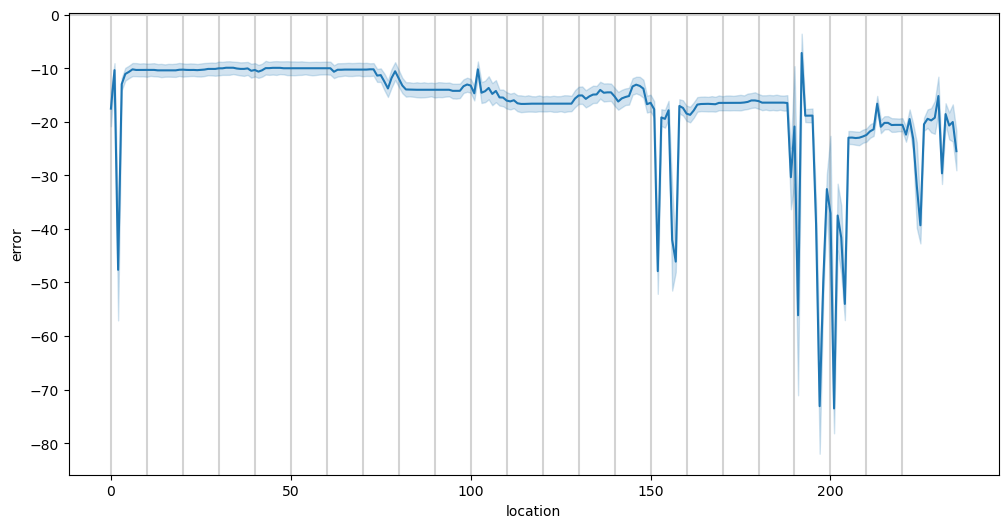

In [290]:
plotdf = y_pred.apply(lambda x: x - y, axis=0).stack().reset_index().rename(columns={'level_0':'genome', 'level_1':'location', 0:'error'})

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=plotdf, 
             x='location', 
             y='error', 
             # hue='genome', 
             legend=False)

for i in range(0, 230, 10):
    ax.axvline(i, color='lightgray', zorder=0)
    
ax.axhline(0, color='lightgray', zorder=0)

In [292]:
plotdf.to_csv('./../data/validation_datasets/Colman2024/Coleman2024_error.tsv', sep='\t')

In [293]:
plotdf.groupby('location').agg({'error':'mean'}).sort_values('error')

,error
location,
201,-73.521453
197,-73.092892
191,-56.123185
204,-54.008952
198,-49.917977
...,...
45,-9.938117
32,-9.919409
33,-9.919409


In [294]:
counts = colman2024_aln_df.apply(lambda col: col.value_counts(), axis=0).fillna(0)

counts = counts.divide(counts.sum()).T
counts.head()

,-,A,C,D,E,F,G,H,I,K,...,M,N,P,Q,R,S,T,V,W,Y
0,0.814257,0.002008,0.0,0.000000,0.000000,0.000000,0.001004,0.000000,0.002008,0.000000,...,0.135542,0.000000,0.000000,0.000000,0.021084,0.012048,0.001004,0.001004,0.000000,0.001004
1,0.131526,0.003012,0.0,0.002008,0.026104,0.000000,0.008032,0.001004,0.033133,0.029116,...,0.665663,0.000000,0.000000,0.001004,0.017068,0.002008,0.005020,0.052209,0.000000,0.017068
2,0.923695,0.005020,0.0,0.000000,0.000000,0.001004,0.019076,0.000000,0.019076,0.005020,...,0.013052,0.000000,0.000000,0.001004,0.010040,0.001004,0.000000,0.000000,0.001004,0.001004
3,0.128514,0.000000,0.0,0.018072,0.004016,0.004016,0.001004,0.019076,0.112450,0.167671,...,0.005020,0.144578,0.001004,0.003012,0.351406,0.000000,0.000000,0.014056,0.000000,0.019076
4,0.054217,0.003012,0.0,0.000000,0.000000,0.005020,0.000000,0.000000,0.288153,0.001004,...,0.001004,0.000000,0.000000,0.000000,0.014056,0.000000,0.001004,0.130522,0.004016,0.002008


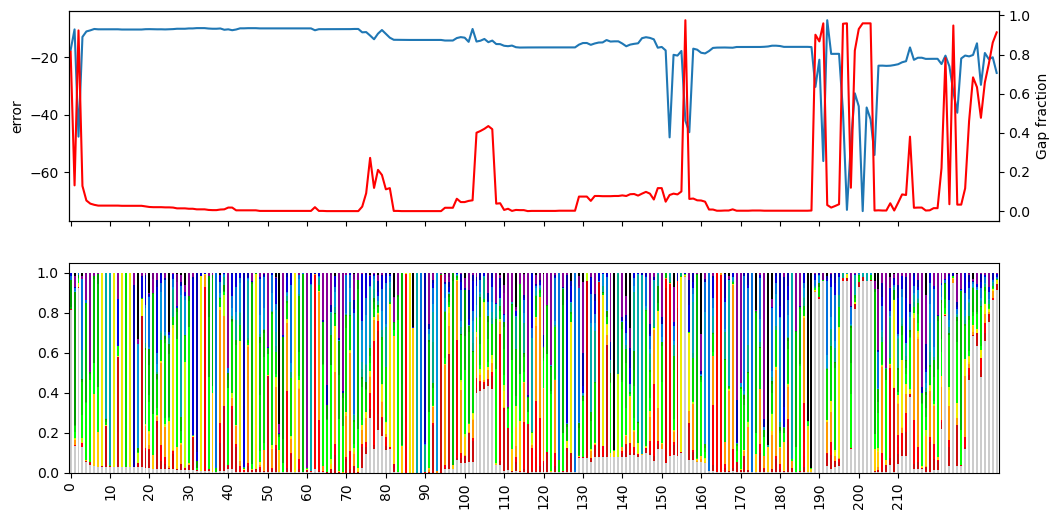

In [295]:
# number of gaps per site
fig= plt.figure(figsize=(12,6))
ax = fig.add_subplot(2,1,1)
sns.lineplot(plotdf.groupby('location').agg({'error':'mean'})['error'], 
             ax=ax)

rax = ax.twinx()
sns.lineplot(colman2024_aln_df.eq('-').sum() / colman2024_aln_df.shape[0], ax=rax, color='r')

rax.set_xlim(10, 210)
rax.set_ylabel('Gap fraction')

ax = fig.add_subplot(2,1,2, sharex=ax)
counts.plot(kind='bar', stacked=True, legend=False, ax=ax, cmap='nipy_spectral_r')
xticks = ax.set_xticks(range(0,220,10))

## Examining embeddings

In [300]:
with open('./../data/validation_datasets/Colman2024/keeplength_adk_nogap.afa', 'r') as handle:
    lines = [pd.Series(index=range(len(r.seq)), data=[i for i in str(r.seq)], name=r.id) for r in SeqIO.parse(handle, 'fasta')]

colman2024_aln_df = pd.concat(lines, axis=1).T

colman2024_aln_df.head()

,0,1,2,3,4,5,6,7,8,9,...,226,227,228,229,230,231,232,233,234,235
CP000699.1_1354|GB_GCA_000016765.1|adk|temp=30.0|bitscore=175.3,-,M,-,N,I,I,L,L,G,P,...,L,D,N,-,-,-,-,-,-,-
JH590862.1_220|GB_GCA_000242235.1|adk|temp=37.0|bitscore=192.2,M,M,-,G,I,V,M,L,G,A,...,L,L,-,-,-,-,-,-,-,-
AP012044.1_910|GB_GCA_000283575.1|adk|temp=30.0|bitscore=168.7,-,M,-,R,L,I,L,L,G,A,...,L,G,-,-,-,R,-,-,-,-
AQXR01000011.1_67|GB_GCA_000376885.1|adk|temp=37.0|bitscore=178.2,-,M,-,R,L,L,I,M,G,P,...,L,T,K,-,-,-,-,-,-,-
KE150266.1_745|GB_GCA_000411155.1|adk|temp=37.0|bitscore=164.5,G,-,-,A,I,L,I,L,G,A,...,L,E,Y,-,L,L,E,K,-,-


In [301]:
data = []
for index, row in colman2024_aln_df.iterrows():
    seq = ''.join([s for s in row.values if s != '-'])

    # Clean sequence to ensure valid AAs only
    VALID_AAS = set("ACDEFGHIKLMNPQRSTVWY")
    clean_seq = ''.join([aa for aa in seq if aa in VALID_AAS])
    
    if len(seq) == len(clean_seq):
        
        # Batch convert
        data.append((index, clean_seq))
    else:
        print('Uh oh, invalid AA!')
    
    # print(len(protein.sequence), len(seq), protein.get_embedding(layer=12).shape)

Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!


In [302]:
%%time
# compute representations from sixth layer
labels, strs, toks = batch_converter(data)
    
with torch.no_grad():
    out = model(toks, repr_layers=[6])
    reps = out["representations"][6]

# Get per-residue embedding (remove CLS, keep real residues)
per_residue_embed = reps[0, 1:len(clean_seq)+1]  # shape: (L, embed_dim)

CPU times: user 26min 57s, sys: 26min 21s, total: 53min 18s
Wall time: 4min 56s


In [303]:
# make a df
cls_embedding = pd.DataFrame(index=[l.split('|')[1] for l in labels], data=reps[:, 0, :])

In [304]:
tsne = TSNE(n_components=2, random_state=143, perplexity=50)
embedding_2d = tsne.fit_transform(cls_embedding)

In [305]:
plotdf = pd.DataFrame(embedding_2d, index=cls_embedding.index)

In [306]:
plotdf.head()

,0,1
GB_GCA_000016765.1,-1.951909,21.641901
GB_GCA_000242235.1,32.616722,32.847656
GB_GCA_000283575.1,3.130796,-10.479993
GB_GCA_000376885.1,-63.828403,-12.298232
GB_GCA_000411155.1,-40.371212,8.162785


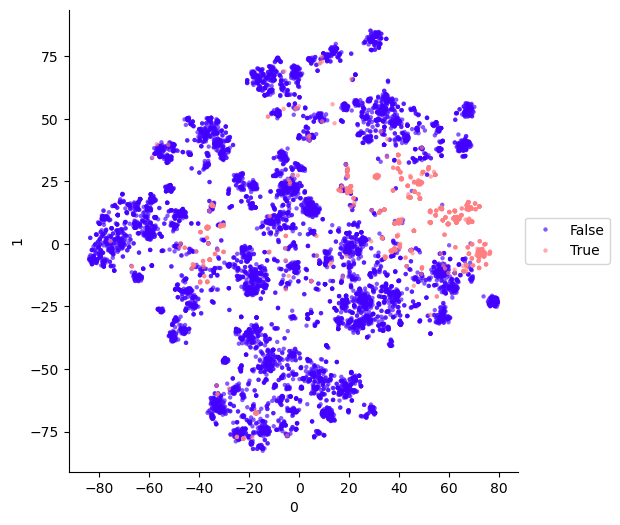

In [307]:
fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data=plotdf, x=0, y=1, s=10, hue=plotdf.index.str.contains('tbl'), palette='gnuplot2', 
                linewidth=0, alpha=0.65)
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_aspect('equal')
sns.despine()
plt.show()


In [309]:
cls_embedding.to_csv('./../data/validation_datasets/Colman2024/Coleman2024_embedding.tsv', sep='\t')

In [206]:
yb_aln_df = get_aln_df('./../data/validation_datasets/Youngblut2020/keeplength_adk_nogap.afa') 

yb_aln_df = yb_aln_df[~yb_aln_df.index.isin(aln_df.index)]

yb_aln_df.head()

,0,1,2,3,4,5,6,7,8,9,...,227,228,229,230,231,232,233,234,235,236
NODE_31_length_115180_cov_5.826067_21|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=162.8,-,M,-,-,I,I,M,L,G,A,...,-,D,-,-,-,-,-,-,-,-
NODE_43_length_105063_cov_15.865629_59|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=176.0,-,M,K,N,I,V,I,F,G,A,...,I,D,R,A,-,-,-,-,-,-
NODE_48_length_99316_cov_9.973817_31|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=167.1,-,I,-,I,F,I,-,-,A,P,...,L,R,-,-,-,S,Q,A,-,-
NODE_51_length_96540_cov_13.100275_11|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=182.4,-,M,L,Y,L,I,L,F,G,A,...,L,E,G,K,-,-,-,-,-,-
NODE_83_length_82459_cov_17.568613_58|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=205.8,-,M,-,K,I,V,F,M,G,P,...,L,G,G,N,-,K,-,-,-,-


In [207]:
data = get_esm_input(yb_aln_df)

Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!
Uh oh, invalid AA!


In [208]:
print(f'There are {len(data)} proteins in this dataset')

There are 648 proteins in this dataset


In [209]:
%%time
labels, strs, toks = batch_converter(data)
    
with torch.no_grad():
    out = model(toks, repr_layers=[6])
    reps = out["representations"][6]

# Get per-residue embedding (remove CLS, keep real residues)
# per_residue_embed = reps[0, 1:len(clean_seq)+1]  # shape: (L, embed_dim)

CPU times: user 2min 40s, sys: 1min 13s, total: 3min 54s
Wall time: 25 s


In [210]:
len(labels)

648

In [211]:
yb_aln_df

,0,1,2,3,4,5,6,7,8,9,...,227,228,229,230,231,232,233,234,235,236
NODE_31_length_115180_cov_5.826067_21|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=162.8,-,M,-,-,I,I,M,L,G,A,...,-,D,-,-,-,-,-,-,-,-
NODE_43_length_105063_cov_15.865629_59|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=176.0,-,M,K,N,I,V,I,F,G,A,...,I,D,R,A,-,-,-,-,-,-
NODE_48_length_99316_cov_9.973817_31|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=167.1,-,I,-,I,F,I,-,-,A,P,...,L,R,-,-,-,S,Q,A,-,-
NODE_51_length_96540_cov_13.100275_11|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=182.4,-,M,L,Y,L,I,L,F,G,A,...,L,E,G,K,-,-,-,-,-,-
NODE_83_length_82459_cov_17.568613_58|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=205.8,-,M,-,K,I,V,F,M,G,P,...,L,G,G,N,-,K,-,-,-,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NODE_1922_length_5725_cov_9.289771_8|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=182.4,M,I,-,N,L,I,L,L,G,L,...,L,S,K,D,-,-,-,-,-,-
NODE_1947_length_5641_cov_3.683136_2|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=191.6,-,M,-,R,L,I,F,L,G,P,...,L,E,K,-,A,S,A,-,-,-
NODE_2061_length_5384_cov_10.056859_2|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=178.0,-,M,-,N,L,I,L,F,G,P,...,L,A,-,-,-,-,-,-,-,-
NODE_5588_length_2478_cov_3.345027_1|scaffolds_hmmsearch.tbl|XXXtemp=XXX|bitscore=160.0,-,M,V,N,I,V,L,F,G,A,...,I,D,R,K,-,-,-,-,-,-


In [213]:
col_datasets = assemble_col_dataset(yb_aln_df.reindex(index=labels), labels)

16 rows available for col 236 |--------------------|      